In [3]:
from functools import partial
from pprint import pprint
from termcolor import colored

import torch

from tqdm import tqdm

from search_strategies import create_search_strategy
from pcfg import PCFG
from grammars import grammars
from evaluation import evaluation_fn
from arguments import parse_arguments
from data import get_data_loaders
from utils import load_config, Limiter

import numpy as np
from matplotlib import pyplot as plt

import copy
import time
import random

from search_state import DerivationTreeNode, Operation
from grammars import einspace

from tqdm import tqdm
from scipy.stats import skewnorm

from visualise import visualise_derivation_tree
import pickle
import baselines

import os

In [17]:
a = {"b":1,"c":2}
for aa in a: print(a[aa])
"b" in a
str(["a", "b", "c"])

1
2


"['a', 'b', 'c']"

In [4]:
class ARGS():
    def __init__(self, config, device):
        self.config = config
        self.device = device
        self.acquisition_fn = "uct"
        self.exploration_weight=1.0
        self.incubent_type="parent"
        self.reward_mode="sum"
        self.regularised=True
        self.vis_interval = 10
        
args = ARGS("D:/Adri/Projects/NAS/einspace/einsearch-main_new/configs/einspace_quick/evolution_test/addnist/evolution.yaml", "cpu")
args = load_config(args)
args.individual_memory = args.mem_limit
args.dataset = "addnist"
args.generational = False
args.regularised = True
args.elitism = 0
args.mutation_rate = 0.0
args.crossover_strategy = None
args.crossover_rate = 0
args.load_in_gpu = False
args.channels = 3
args.load_from = "a"
args.architecture_seed = 0
args.add_full_paths = True
args.n_tries = 100000000
#args.time_limit = 10
#pprint(vars(args))

# set the seed
torch.manual_seed(args.seed)

# create the limiter
# this makes sure that the search does not exceed
# time, memory (GPU and RAM), depth, or node limits during the search
limiter = Limiter(
    limits={
        "time": args.time_limit,
        "max_id": args.max_id_limit,
        "depth": args.depth_limit,
        "memory": args.mem_limit,
        "individual_memory": args.individual_memory
    }
)

# create the grammar
grammar = PCFG(
    grammar=grammars[args.search_space],
    limiter=limiter,
)
#print(grammar)

train_loader, val_loader, _, _ = get_data_loaders(
    dataset=args.dataset,
    batch_size=args.batch_size,
    image_size=args.image_size,
    root=r"D:\Adri\Projects\NAS\einspace\einsearch-main_new\data",
    load_in_gpu=args.load_in_gpu,
    device=args.device,
    log=args.verbose_eval,
)

eval_fn = partial(
    evaluation_fn,
    args=args,
    train_loader=train_loader,
    val_loader=val_loader,
)

# create the input parameters
input_params = {
    "shape": torch.Size([1, args.channels, *args.image_size]),
    "other_shape": None,
    "mode": "im",
    "other_mode": None,
    "branching_factor": 1,
    "last_im_shape": None,
}

# create the search strategy
search = create_search_strategy(args, grammar, eval_fn, limiter, input_params)

D:\Adri\Projects\NAS\einspace\einsearch-main_new\configs\einspace_quick\evolution_test\addnist\evolution.yaml
D:\Adri\Projects\NAS\einspace\einsearch-main_new\configs\einspace_quick\evolution_test\addnist\evolution.yaml
Limiter({'time': 300, 'max_id': 10000, 'depth': 20, 'memory': 4096, 'individual_memory': 4096})


AttributeError: 'ARGS' object has no attribute 'restart_time_limit'

# Definition of the classes and functions

Two variations of the main class are defined here (recursive and standard AlignmentMatrix), along with some other functions. The naming of the variables, classes and functions is definitely not up to code, there's a lot of commented code and messy stuff, and I should really give each section a brief explanation, but for now treat this as black magic and that's it.

In [ ]:
class MatrixCell():
    # This class represents each position within a distance matrix and holds information regarding its distance to the starting position and path to get to it 
    def __init__(self):
        self.top = [] # list of costs of continuing each path of the above matrix position downwards
        self.left = [] # list of costs of continuing each path of the matrix to the left position rightwards
        self.corner = [] # list of costs of continuing each path of the matrix on the left-top corner position down-rightwards
        self.paths = [] # list of valid, most optimal paths to reach this position in the matrix
        self.value = np.nan # distance to the starting position

    def __str__(self):
        return "Value of "+str(self.value)+" with posible paths:\n"+"".join([str(path)+"\n" for path in self.paths])

    def __repr__(self):
        return str(self)

class MatrixOperation(object):
    # This class represents a single mutation to be performed to a model
    def __init__(self, op_id = None, op_type = None, node1_id = None, node2_id = None, i = None, j = None, ii = None, jj = None, value = 0, disabler_ops = [], enabler_ops = []):
        self.id = op_id # operation identifier
        self.op_type = op_type # operation type (can be "add", "rem" or "mut", followed by "_wrap" if dealing with a routing or branching module, and followed by "_sep" or "end" if dealing with the branch/routing separator tokens)
        self.i = i # corresponding matrix row (position within the first model) where the operation starts
        self.j = j # corresponding matrix column (position within the second model) where the operation starts
        self.ii = ii # corresponding matrix row (position within the first model) where the operation ends if it's a branching or routing wrapper, or list of rows for the branch separators in a branching(2)
        self.jj = jj # corresponding matrix column (position within the first model) where the operation ends if it's a branching or routing wrapper, or list of columns for the branch separators in a branching(2)
        self.node1_id = node1_id # id of the node corresponding to position i of the first model
        self.node2_id = node2_id # id of the node corresponding to position j of the second model
        self.value = value # cost of performing this operation
        self.i_swapped = False # wether or not we had to swap the order of the branches in the first model if it corresponds to a branching(2) node
        self.j_swapped = False # wether or not we had to swap the order of the branches in the second model if it corresponds to a branching(2) node
        self.disabler_ops = disabler_ops # list of operations that, if all are performed, do not allow this operation to be performed (for instance, removing all nodes that would be wrapped by a routing dissable the adition of said routing, as it would have nothing to wrap around)
        self.enabler_ops = enabler_ops # list of operations that, if any is performed, allow this operation to be performed even if all disabler operations are performed (in the above example, adding anoder node to be wrapped by the routing before adding the routing)
        
    def __str__(self):
        string = self.op_type+" (id: "+str(self.id)+") with a cost of "+str(self.value)+". "
        if len(self.disabler_ops):
            string = string[:-2]+" (disabled by "
            for branch in self.disabler_ops:
                if type(branch) != list: branch = [branch]
                for op in branch: string += str(op.id)+", "
            if string[-3:] == "by ": string += "none, "
            string = string[:-2]+")."
        if len(self.enabler_ops):
            string = string[:-2]+" ("*(len(self.disabler_ops)==0)+"; "*(len(self.disabler_ops)>0)+"enabled by "
            for branch in self.enabler_ops:
                if type(branch) != list: branch = [branch]
                for op in branch: string += str(op.id)+", "
            if string[-3:] == "by ": string += "none, "
            string = string[:-2]+")."
        return string
        
    def __repr__(self):
        return str(self)

    def __eq__(self, other):
        return self.id == other.id
    
class DecoyOperation(object):
    # This is an empty class to hold an operation name as if it was a node's operation
    def __init__(self, name):
        self.name = name
    
class DecoyNode(object):
    # This is an empty class to hold an operation name and id as if it was a node, as well as its parent and branch number if it is an branch separator/end decoy node
    def __init__(self, parent, branch, name):
        self.parent = parent # node parent (branching/routing to close if it is a separator/end node)
        self.operation = DecoyOperation(name) # decoy operation
        self.children = [] # decoy nodes (start node and separator/end nodes) do not have children
        if parent is None: self.id = -1 # if it is a start node, its id will be -1
        else: self.id = self.parent.id # otherwise, it will inherit the id of the node it is separating/closing

    def is_root(self):
        return self.parent is not None
        
    def __eq__(self, other):
        if isinstance(other, self.__class__):
            return self.id == other.id
        else:
            return False

    def __ne__(self, other):
        return not self.__eq__(other)
        
    def __str__(self):
        return str(self.operation.name)+" (id "+str(self.id)+")"

    def __repr__(self):
        return str(self)

class AlignmentMatrixRecursive():
    # This class computes the distance and operations required to transform one model into another, and provides with some function to select and aply said operations
    def __init__(self, model1, model2, collapse_corners = False, img_name = None, precomputed_matrix = None, verbose = False):
        self.collapse_corners = collapse_corners # Wether to collapse the paths at the corners of the matrix to avoid making unnecesary computations that probably won't yield better alignments
        self.img_name = img_name # Name to save the visualization of the distance matrix as
        self.verbose = verbose # Wether to print the operations and matrix
        # Express first model in a sequential form
        self.model1 = model1
        if self.verbose: print("First model: ", self.model1)
        self.model_ops1 = [DecoyNode(None, None, "start_node")] + self.breakdown(self.model1)
        # Express second model in a sequential form
        self.model2 = model2
        self.new_node_id = max([node.id for node in self.model1.serialise()])+1
        for node in self.model2.serialise(): self.update_id(node) # We reset the models' node ids to avoid anything breaking when we combine the models because of id repetitions
        if self.verbose: print("Second model:", self.model2)
        self.model_ops2 = [DecoyNode(None, None, "start_node")] + self.breakdown(self.model2)
        # Calculate the matrix
        timestart = time.time()
        self.operations = []
        self.nontrivial_ops = []
        if precomputed_matrix == None:
            self.matrix = self.initialize_matrix()
            self.matrix = self.calculate_matrix()
        else: self.matrix = precomputed_matrix
        # Save distance and computing time
        self.distance = self.matrix[-1][-1].value
        self.compute_time = time.time()-timestart
        # Calculate enabler and disabler relationships for the different operations and fix indexes if we need to swap branches within branching(2) nodes
        self.calculate_restrictions()
        # Print stuff it need be
        if self.verbose: print("\nDistance of", round(self.distance,2), "through", len(self.nontrivial_ops), "operations, calculated in" ,round((self.compute_time)*1000,2),"ms."), self.print_operations(), self.visualize_alignment_matrix()
    
    def breakdown(self, node):
        # This function is used to express the nodes of a model into a secuential series of tokens, adding separators when needed
        model_ops = []
        # If we are not dealing with a terminal computation node
        if node.parent: condition = "computation" not in node.parent.operation.name
        else: condition = True
        if condition:
            # We add the node to the list of tokens, unless it is a sequential node
            if not ("sequential" in node.operation.name):
                model_ops = [node]
            # If we have several children (branchings, routings...)
            if len(node.children) > 2:
                # we ignore the first and last children, which will be treated as hyperparameters of their parent node
                for child in range(1, len(node.children)-1):
                    # and recursively call this function on the children node, adding separator tokens afterwards as needed
                    model_ops += self.breakdown(node.children[child])
                    model_ops += [DecoyNode(node, child, "wrap_"+"end"*(child==len(node.children)-2)+"sep"*(child!=len(node.children)-2))]
            # Otherwise, we call this function on the (allegedly sequential) node's children
            else:
                for child in node.children:
                    model_ops += self.breakdown(child)
        return model_ops

    def initialize_matrix(self, model_ops1 = None, model_ops2 = None):
        # This function is used to generate an empty distance matrix
        matrix = []
        if (model_ops1 == None) and (model_ops2 == None): complete_matrix = True
        else: complete_matrix = False
        if model_ops1 == None: model_ops1 = self.model_ops1
        if model_ops2 == None: model_ops2 = self.model_ops2
        size = (len(model_ops1), len(model_ops2))
        # We initialize the whole matrix with empty cells
        for i in range(size[0]):
            row = []
            for j in range(size[1]):
                row.append(MatrixCell())
            matrix.append(row)
        # If we called the function with no arguments, we properly initialize the value of the top and left borders, as well as the initial corner operation
        if complete_matrix:
            for i in range(size[0]):
                matrix[i][0].left = [np.inf ]
                matrix[i][0].corner = [np.inf]
            for j in range(size[1]):
                matrix[0][j].top = [np.inf]
                matrix[0][j].corner = [np.inf] 
            matrix[0][0].value = 0
            matrix[0][0].paths = [[MatrixOperation(op_id = 0, op_type = "start", node1_id = model_ops1[0].id, node2_id = model_ops2[0].id, i = 0, j = 0)]]
        return matrix
        
    def calculate_matrix(self, matrix = None, model_ops1 = None, model_ops2 = None, start_i = 0, start_j = 0):
        # This function calculates the distance matrix for a given set of tokens
        if matrix == None: matrix = self.matrix
        if model_ops1 == None: model_ops1 = self.model_ops1
        if model_ops2 == None: model_ops2 = self.model_ops2
        matrix_iswap, matrix_jswap, matrix_ijswap = None, None, None
        prev_i,prev_j = 0, 0
        
        while np.isnan(matrix[-1][-1].value):
            # We define the submatrix that we will fill up next by looking at the next instances of branching(2) openings and closings in either model
            compute_submatrix = [False, False]
            if (model_ops1[prev_i].operation.name == "branching(2)") and prev_i>0:
                compute_submatrix[0] = True
                for mid_i in range(prev_i+1, len(model_ops1)):
                    if (model_ops1[prev_i].id == model_ops1[mid_i].id) and ("sep" in model_ops1[mid_i].operation.name): break
                for max_i in range(mid_i+1, len(model_ops1)):
                    if (model_ops1[prev_i].id == model_ops1[max_i].id) and ("end" in model_ops1[max_i].operation.name): break
            else:
                for max_i in range(prev_i+1, len(model_ops1)):
                    if (model_ops1[max_i].operation.name == "branching(2)"): break
            max_i += 1
            if (model_ops2[prev_j].operation.name == "branching(2)") and prev_j>0:
                compute_submatrix[1] = True
                for mid_j in range(prev_j+1, len(model_ops2)):
                    if (model_ops2[prev_j].id == model_ops2[mid_j].id) and ("sep" in model_ops2[mid_j].operation.name): break
                for max_j in range(mid_j+1, len(model_ops2)):
                    if (model_ops2[prev_j].id == model_ops2[max_j].id) and ("end" in model_ops2[max_j].operation.name): break
            else:
                for max_j in range(prev_j+1, len(model_ops2)):
                    if (model_ops2[max_j].operation.name == "branching(2)"): break
            max_j += 1
            # Then, if we have found a new branching(2), we need to calculate all the posible branch swapps
            if (compute_submatrix[0] or compute_submatrix[1]) and ((prev_i, prev_j) != (0, 0)):
                # If we did not have aur auxiliary matrices for keeping track of branch swappings, we initialize them
                if matrix_iswap == None: matrix_iswap = copy.deepcopy(matrix)
                if matrix_jswap == None: matrix_jswap = copy.deepcopy(matrix)
                if matrix_ijswap == None: matrix_ijswap = copy.deepcopy(matrix)
                # We cut down our model operations to the submatrix of interest
                aux_model_ops1 = model_ops1[prev_i:max_i]
                aux_model_ops2 = model_ops2[prev_j:max_j]
                # Reorder tokens pertaining to each branch
                if compute_submatrix[0]: aux_model_ops1_swap = [model_ops1[prev_i]]+model_ops1[mid_i+1:max_i-1]+[model_ops1[mid_i]]+model_ops1[prev_i+1:mid_i]+[model_ops1[max_i-1]]
                else: aux_model_ops1_swap = aux_model_ops1
                if compute_submatrix[1]: aux_model_ops2_swap = [model_ops2[prev_j]]+model_ops2[mid_j+1:max_j-1]+[model_ops2[mid_j]]+model_ops2[prev_j+1:mid_j]+[model_ops2[max_j-1]]
                else: aux_model_ops2_swap = aux_model_ops2
                # and recursively call this function to calculate the distance if we did not perform any swaps
                aux_matrix = self.calculate_matrix(matrix = [[row[j] for j in range(prev_j,max_j)] for row in matrix[prev_i:max_i]], model_ops1 = aux_model_ops1, model_ops2 = aux_model_ops2, start_i = prev_i, start_j = prev_j)
                # We dump the results onto the original sized matrix
                for i in range(prev_i, max_i):
                    for j in range(prev_j, max_j):
                        matrix[i][j] = aux_matrix[i-prev_i][j-prev_j]
                # Then, we compute the same for the required swaps
                if compute_submatrix[0]:
                    aux_matrix_iswap = [[row[j] for j in range(prev_j,max_j)] for row in matrix_iswap[prev_i:max_i]]
                    if np.isnan(aux_matrix_iswap[0][-1].value): aux_matrix_iswap[0] = matrix[prev_i][prev_j:max_j]
                    aux_matrix_iswap = self.calculate_matrix(matrix = aux_matrix_iswap, model_ops1 = aux_model_ops1_swap, model_ops2 = aux_model_ops2, start_i = prev_i, start_j = prev_j)
                    for j in range(prev_j, max_j):
                        for path in matrix_iswap[max_i-1][j].paths: path[-1].i_swapped = True
                    if (not np.isnan(matrix_ijswap[prev_i][prev_j].value)) and (not compute_submatrix[1]): # if we have not collapsed the matrix with swaps in both branches, we calculate its paths as well
                        aux_matrix_ijswap = [[row[j] for j in range(prev_j,max_j)] for row in matrix_ijswap[prev_i:max_i]]
                        #for i, pos in enumerate([matrix_iswap[prev_i+i][prev_j] for i in range(1,len(aux_matrix_ijswap))]): aux_matrix_ijswap[i+1][0] = pos
                        aux_matrix_ijswap = self.calculate_matrix(matrix = aux_matrix_ijswap, model_ops1 = aux_model_ops1_swap, model_ops2 = aux_model_ops2_swap, start_i = prev_i, start_j = prev_j)
                        # Then, we dump the computed ij submatrix into the original sized one
                        for i in range(prev_i, max_i):
                            for j in range(prev_j, max_j):
                                matrix_ijswap[i][j] = aux_matrix_ijswap[i-prev_i][j-prev_j]
                        # We then collapse the ijswap onto the iswap matrix on the right side
                        for j in range(prev_j, max_j):
                            if matrix_iswap[max_i-1][j].value < matrix_ijswap[max_i-1][j].value:
                                matrix_ijswap[max_i-1][j] = matrix_iswap[max_i-1][j]
                            elif matrix_iswap[max_i-1][j].value > matrix_ijswap[max_i-1][j].value:
                                matrix_iswap[max_i-1][j] = matrix_ijswap[max_i-1][j]
                    # Lastly, we dump the computed iswap submatrix onto the original sized one
                    for i in range(prev_i, max_i):
                        for j in range(prev_j, max_j):
                            matrix_iswap[i][j] = aux_matrix_iswap[i-prev_i][j-prev_j]
                    # and we collapse the iswap onto the original matrix on the right side
                    for j in range(prev_j, max_j):
                        if matrix[max_i-1][j].value < matrix_iswap[max_i-1][j].value:
                            matrix_iswap[max_i-1][j] = matrix[max_i-1][j]
                            for path in matrix[max_i-1][j].paths: path[-1].i_swapped = False
                        elif matrix[max_i-1][j].value > matrix_iswap[max_i-1][j].value:
                            matrix[max_i-1][j] = matrix_iswap[max_i-1][j]
                        
                if compute_submatrix[1]:
                    aux_matrix_jswap = [[row[j] for j in range(prev_j,max_j)] for row in matrix_jswap[prev_i:max_i]]
                    if np.isnan(aux_matrix_jswap[-1][0].value):
                        for i, pos in enumerate([matrix[prev_i+i][prev_j] for i in range(len(aux_matrix_jswap))]): aux_matrix_jswap[i][0] = pos
                    aux_matrix_jswap = self.calculate_matrix(matrix = aux_matrix_jswap, model_ops1 = aux_model_ops1, model_ops2 = aux_model_ops2_swap, start_i = prev_i, start_j = prev_j)
                    for i in range(prev_i, max_i):
                        for path in matrix_jswap[i][max_j-1].paths: path[-1].j_swapped = True
                    if (not np.isnan(matrix_ijswap[prev_i][prev_j].value)) and (not compute_submatrix[0]): # if we have not collapsed the matrix with swaps in both branches, we calculate its paths as well
                        aux_matrix_ijswap = [[row[j] for j in range(prev_j,max_j)] for row in matrix_ijswap[prev_i:max_i]]
                        #aux_matrix_ijswap[0][1:] = matrix_jswap[prev_i][prev_j+1:max_j]
                        aux_matrix_ijswap = self.calculate_matrix(matrix = aux_matrix_ijswap, model_ops1 = aux_model_ops1_swap, model_ops2 = aux_model_ops2_swap, start_i = prev_i, start_j = prev_j)
                        # Then, we dump the computed ij submatrix into the original sized one
                        for i in range(prev_i, max_i):
                            for j in range(prev_j, max_j):
                                matrix_ijswap[i][j] = aux_matrix_ijswap[i-prev_i][j-prev_j]
                        # We then collapse the ijswap onto the jswap matrix on the bottom side
                        for i in range(prev_i, max_i):
                            if matrix_jswap[i][max_j-1].value < matrix_ijswap[i][max_j-1].value:
                                matrix_ijswap[i][max_j-1] = matrix_jswap[i][max_j-1]
                            elif matrix_jswap[i][max_j-1].value > matrix_ijswap[i][max_j-1].value:
                                matrix_jswap[i][max_j-1] = matrix_ijswap[i][max_j-1]
                    # Lastly, we dump the computed jswap submatrix onto the original sized one
                    for i in range(prev_i, max_i):
                        for j in range(prev_j, max_j):
                            matrix_jswap[i][j] = aux_matrix_jswap[i-prev_i][j-prev_j]
                    # and we collapse the jswap onto the original matrix on the bottom side
                    for i in range(prev_i, max_i):
                        if matrix[i][max_j-1].value < matrix_jswap[i][max_j-1].value:
                            matrix[i][max_j-1] = matrix[i][max_j-1]
                        elif matrix[i][max_j-1].value > matrix_jswap[i][max_j-1].value:
                            matrix[i][max_j-1] = matrix_jswap[i][max_j-1]
                                
                if compute_submatrix[0] and compute_submatrix[1]:
                    # In the case of swapping branches in both models simultaneously,
                    aux_matrix_ijswap = [[row[j] for j in range(prev_j,max_j)] for row in matrix_ijswap[prev_i:max_i]]
                    # if we have no values from previous ijswap calculations, we take them from the separated i and j swapped matrices;
                    # the first row will come from the matrix_jswap matrix
                    if np.isnan(aux_matrix_ijswap[0][-1].value): aux_matrix_ijswap[0] = matrix_jswap[prev_i][prev_j:max_j]
                    # and the first column will come from the matrix_jswap matrix
                    if np.isnan(aux_matrix_ijswap[-1][0].value):
                        for i, pos in enumerate([matrix_iswap[prev_i+i][prev_j] for i in range(len(aux_matrix_ijswap))]): aux_matrix_ijswap[i][0] = pos
                    # Then, we compute the distance submatrix
                    aux_matrix_ijswap = self.calculate_matrix(matrix = aux_matrix_ijswap, model_ops1 = aux_model_ops1_swap, model_ops2 = aux_model_ops2_swap, start_i = prev_i, start_j = prev_j)

                    # We collapse the ijswap matrix on the branches that we have exited
                    for i in range(len(aux_matrix_ijswap)):
                        for path in aux_matrix_ijswap[i][-1].paths: path[-1].i_swapped = True
                        if aux_matrix_jswap[i][-1].value < aux_matrix_ijswap[i][-1].value:
                            aux_matrix_ijswap[i][-1] = aux_matrix_jswap[i][-1]
                    for j in range(len(aux_matrix_ijswap[0])):
                        for path in aux_matrix_ijswap[-1][j].paths: path[-1].j_swapped = True
                        if aux_matrix_iswap[-1][j].value < aux_matrix_ijswap[-1][j].value:
                            aux_matrix_ijswap[-1][j] = aux_matrix_iswap[-1][j]
                    # Then, we dump the computed ij submatrix into the original sized one, and we specify where we have to 
                    for i in range(prev_i, max_i):
                        for j in range(prev_j, max_j):
                            matrix_ijswap[i][j] = aux_matrix_ijswap[i-prev_i][j-prev_j]
                    # We can collapse the original matrix at the corner because we exited both branches. The rest, we signal that we would need to collapse it
                    if matrix[max_i-1][max_j-1].value > matrix_ijswap[max_i-1][max_j-1].value: matrix[max_i-1][max_j-1] = matrix_ijswap[max_i-1][max_j-1]

            # If we are not dealing with branch swaps, we simply fill the matrix from the corner downwards
            else:
                # We decide the sequence to fill the matrix positions in
                sequence = self.expanding_corner_loop(max_i-prev_i, max_j-prev_j)
                for position in sequence:
                    i = position[0] + prev_i
                    j = position[1] + prev_j
                    # If we don't have a value for that position of the matrix we check if we can approach it from the three posible directions
                    if np.isnan(matrix[i][j].value):
                        if matrix[i][j].top == []:
                            for path in matrix[i-1][j].paths:
                                if model_ops1[i].operation.name in ["wrap_end", "wrap_sep"]: # If we are trying to close a new branch,
                                    op = 0
                                    level = 0 # we keep track of how many branches/routings we go into or exit through the current path with this "level" tracker
                                    closed_branches = 0 # and the branches that we close
                                    while (model_ops1[i].id != path[op].node1_id) or (path[op].op_type not in ["add_wrap", "add_wrap_jump"]):
                                        op -= 1
                                        # We update the depth level and the number of branches we closed
                                        if (model_ops1[i].id == path[op].node1_id) and ("add" in path[op].op_type): closed_branches += 1
                                        if path[op].op_type in ["rem_wrap", "mut_wrap"]: level -= 1
                                        elif path[op].op_type in ["rem_wrap_end", "mut_wrap_end"]: level += 1
                                        if (level == -1) or (path[op].op_type == "start"): break # If we exit the outer branch/rout, we break this loop
                                    # We check that we have closed all the branches we were meant to
                                    branches_to_close = len(model_ops1[i].parent.children) - 2 - (model_ops1[i].operation.name=="wrap_sep")
                                    if ("_jump" in path[op].op_type): branches_to_close = 3 - branches_to_close
                                    if (level==0) and (branches_to_close == closed_branches): matrix[i][j].top += [matrix[i-1][j].value] # If the branch was added within this depth, we allow the ending of the branch
                                    else: matrix[i][j].top += [np.inf]
                                else: matrix[i][j].top += [matrix[i-1][j].value + 1] # If we are not trying to close a branch, we simply sum the cost of adding whatever we're adding
        
                        if matrix[i][j].left == []:
                            for path in matrix[i][j-1].paths:
                                if model_ops2[j].operation.name in ["wrap_end", "wrap_sep"]: # If we are trying to close a branch we removed,
                                    op = 0
                                    level = 0 # we keep track of how many branches/routings we go into or exit through the current path with this "level" tracker
                                    closed_branches = 0 # and the branches that we close
                                    while (model_ops2[j].id != path[op].node2_id) or (path[op].op_type not in ["rem_wrap", "rem_wrap_jump"]):
                                        op -= 1
                                        # We update the depth level and the number of branches we closed
                                        if (model_ops2[j].id == path[op].node2_id) and ("rem" in path[op].op_type): closed_branches += 1
                                        if path[op].op_type in ["add_wrap", "mut_wrap"]: level -= 1
                                        elif path[op].op_type in ["add_wrap_end", "mut_wrap_end"]: level += 1
                                        if (level == -1) or (path[op].op_type == "start"): break # If we exit the outer branch/rout, we break this loop
                                    # We check that we have closed all the branches we were meant to
                                    branches_to_close = len(model_ops2[j].parent.children) - 2 - (model_ops2[j].operation.name=="wrap_sep")
                                    if ("_jump" in path[op].op_type): branches_to_close = 3 - branches_to_close
                                    if (level==0) and (branches_to_close == closed_branches): matrix[i][j].left += [matrix[i][j-1].value] # If the branch was removed within this depth, we allow the ending of the branch
                                    else: matrix[i][j].left += [np.inf]
                                else:
                                    matrix[i][j].left += [matrix[i][j-1].value + 1] # If we are not trying to close a branch, we simply sum the cost of removing whatever we're removing
        
                        if matrix[i][j].corner == []:
                            mut_cost = self.cost_mut(model_ops1[i], model_ops2[j])
                            for path in matrix[i-1][j-1].paths:
                                if (model_ops1[i].operation.name in ["wrap_end", "wrap_sep"]) and (model_ops2[j].operation.name == model_ops1[i].operation.name): # If we are trying to close a branch we mutated into another,
                                    op = 0
                                    closed_branches1 = 0 # We keep track of how many branches we close on either model
                                    closed_branches2 = 0
                                    while not (((model_ops1[i].id == path[op].node1_id) and (model_ops2[j].id == path[op].node2_id)) and (path[op].op_type == "mut_wrap")): # we simply have to look at where we added/removed/mutated both branches
                                        op -= 1
                                        if (model_ops1[i].id == path[op].node1_id) and ("mut" in path[op].op_type): closed_branches1 += 1
                                        if (model_ops2[j].id == path[op].node2_id) and ("mut" in path[op].op_type): closed_branches2 += 1
                                        if (path[op].op_type == "start"): break
                                    # We check that we have closed all the branches we were meant to
                                    branches_to_close1 = len(model_ops1[i].parent.children) - 2 - (model_ops1[i].operation.name=="wrap_sep")
                                    branches_to_close2 = len(model_ops2[j].parent.children) - 2 - (model_ops2[j].operation.name=="wrap_sep")
                                    if (branches_to_close1 == closed_branches1) and (branches_to_close2 == closed_branches2): matrix[i][j].corner += [matrix[i-1][j-1].value] # and if the branches were mutated, we allow the ending of the branch through mutation
                                    else: matrix[i][j].corner += [np.inf]
                                else: matrix[i][j].corner += [matrix[i-1][j-1].value + mut_cost] # If we are not trying to close a branch, we simply sum the cost of mutating whatever we're mutating

                        # Then, we compare the cost of coming from each direction and only keep the paths with the least cost 
                        matrix[i][j].value = np.nanmin(matrix[i][j].top + matrix[i][j].corner + matrix[i][j].left)
                        for idx, top in enumerate(matrix[i][j].top):
                            if top == matrix[i][j].value:
                                path = matrix[i-1][j].paths[idx]
                                if np.isinf(matrix[i][j].value): op_value = matrix[i][j].value
                                else: op_value = matrix[i][j].value-matrix[i-1][j].value
                                if model_ops1[i].operation.name == "wrap_end": matrix[i][j].paths += [path + [MatrixOperation(op_id = len(path), op_type = "add_wrap_end", node1_id = model_ops1[i].id, node2_id = model_ops2[j].id, i = i+start_i, j = j+start_j)]]
                                elif model_ops1[i].operation.name == "wrap_sep": matrix[i][j].paths += [path + [MatrixOperation(op_id = len(path), op_type = "add_wrap_sep", node1_id = model_ops1[i].id, node2_id = model_ops2[j].id, i = i+start_i, j = j+start_j)]]    
                                elif (len(model_ops1[i].children) >= 3): matrix[i][j].paths += [path + [MatrixOperation(op_id = len(path), op_type = "add_wrap", node1_id = model_ops1[i].id, node2_id = model_ops2[j].id, i = i+start_i, j = j+start_j, value = op_value)]]
                                else: matrix[i][j].paths += [path + [MatrixOperation(op_id = len(path), op_type = "add_module", node1_id = model_ops1[i].id, node2_id = model_ops2[j].id, i = i+start_i, j = j+start_j, value = op_value)]]
                    
                        for idx, left in enumerate(matrix[i][j].left):
                            if left == matrix[i][j].value:
                                path = matrix[i][j-1].paths[idx]
                                if np.isinf(matrix[i][j].value): op_value = matrix[i][j].value
                                else: op_value = matrix[i][j].value-matrix[i][j-1].value
                                if model_ops2[j].operation.name == "wrap_end": matrix[i][j].paths += [path + [MatrixOperation(op_id = len(path), op_type = "rem_wrap_end", node1_id = model_ops1[i].id, node2_id = model_ops2[j].id, i = i+start_i, j = j+start_j)]]
                                elif model_ops2[j].operation.name == "wrap_sep": matrix[i][j].paths += [path + [MatrixOperation(op_id = len(path), op_type = "rem_wrap_sep", node1_id = model_ops1[i].id, node2_id = model_ops2[j].id, i = i+start_i, j = j+start_j)]]
                                elif (len(model_ops2[j].children) >= 3): matrix[i][j].paths += [path + [MatrixOperation(op_id = len(path), op_type = "rem_wrap", node1_id = model_ops1[i].id, node2_id = model_ops2[j].id, i = i+start_i, j = j+start_j, value = op_value)]]
                                else: matrix[i][j].paths += [path + [MatrixOperation(op_id = len(path), op_type = "rem", node2_id = model_ops2[j].id, i = i+start_i, j = j+start_j, value = op_value)]]
                                
                        for idx, corner in enumerate(matrix[i][j].corner):
                            if corner == matrix[i][j].value:
                                path = matrix[i-1][j-1].paths[idx]
                                if np.isinf(matrix[i][j].value): op_value = matrix[i][j].value
                                else: op_value = matrix[i][j].value-matrix[i-1][j-1].value
                                if model_ops1[i].operation.name == "wrap_end": matrix[i][j].paths += [path + [MatrixOperation(op_id = len(path), op_type = "mut_wrap_end", node1_id = model_ops1[i].id, node2_id = model_ops2[j].id, i = i+start_i, j = j+start_j)]]
                                elif model_ops1[i].operation.name == "wrap_sep": matrix[i][j].paths += [path + [MatrixOperation(op_id = len(path), op_type = "mut_wrap_sep", node1_id = model_ops1[i].id, node2_id = model_ops2[j].id, i = i+start_i, j = j+start_j)]]
                                elif (len(model_ops2[j].children) >= 3): matrix[i][j].paths += [path + [MatrixOperation(op_id = len(path), op_type = "mut_wrap", node1_id = model_ops1[i].id, node2_id = model_ops2[j].id, i = i+start_i, j = j+start_j, value = op_value)]]
                                else: matrix[i][j].paths += [path + [MatrixOperation(op_id = len(path), op_type = "mut", node1_id = model_ops1[i].id, node2_id = model_ops2[j].id, i = i+start_i, j = j+start_j, value = op_value)]]

                        if matrix_iswap != None: matrix_iswap[i][j] = matrix[i][j]
                        if matrix_jswap != None: matrix_jswap[i][j] = matrix[i][j]
                        if matrix_ijswap != None: matrix_ijswap[i][j] = matrix[i][j]
                        # We can collapse the paths on the corners, which are really unlikely to contain the best path, to avoid computing unnecesary garbage in really big matrices
                        if self.collapse_corners and (((j+start_j-i-start_i) >= len(self.model_ops2)*0.25) or ((i+start_i-j-start_j) >= len(self.model_ops1)*0.25)): matrix[i][j].paths = [matrix[i][j].paths[0]]

            # We get rid of the paths that we don't need anymore to compute anything with to liberate some memory
            if (model_ops1 == self.model_ops1) and (model_ops2 == self.model_ops2): 
                for i in range(prev_i, max_i-(max_i<len(model_ops1))):
                    for j in range(prev_j, max_j-(max_j<len(model_ops2))):
                        if (i<len(self.model_ops1)-1) and (j<len(self.model_ops2)-1):
                            matrix[i][j].paths = []
                            if matrix_iswap != None: matrix_iswap[i][j].paths = []
                            if matrix_jswap != None: matrix_jswap[i][j].paths = []

            # We move on to the next submatrix
            if max_j >= len(model_ops2):
                prev_j = 0
                prev_i = max_i-1
            else: prev_j = max_j-1
        return matrix

    def cost_mut(self, op1, op2, max_cost = np.inf):
        # This function simply computes the cost of mutating a node into another
        if "wrap_" in op1.operation.name or "wrap_" in op2.operation.name:
            return max_cost
        elif op1.operation.name.split("(")[0] == op2.operation.name.split("(")[0]:
            if max_cost == 1: # This only happens when comparing submodules
                if op1.operation == op2.operation: return 0.
                else: return 0.5
            elif sum([op.operation.name == "branching(2)" for op in (op1,op2)]) == 1: return max_cost # We can't change a branching(2) into a branching(8) for instance
            elif len(op1.children)>2: return ((self.cost_mut(op1.children[0], op2.children[0], 1))+(self.cost_mut(op1.children[-1], op2.children[-1], 1)))/4 # If we substitute a branching/branching(2)/rounting module by another, we compare the subtype of module
            else: return (self.cost_mut(op1.children[0], op2.children[0], 1))/2 # If we substitute a computation module by another, we compare the subtype of module
        else:
            return max_cost

    def expanding_corner_loop(self, rows, cols):
        # This functions computes the sequence of indexes to fill the matrix expanding from the top left corner, processing anti-diagonals where i + j = d
        sequence = []
        for d in range(rows + cols - 1):
            if d % 2 == 0:
                i_start = max(0, d - (cols - 1))
                i_end = min(d, rows - 1)
                for i in range(i_start, i_end + 1):
                    j = d - i
                    sequence.append((i, j))
            else:
                i_end = max(0, d - (cols - 1))
                i_start = min(d, rows - 1)
                for i in range(i_start, i_end - 1, -1):
                    j = d - i
                    sequence.append((i, j))
        return sequence
    
    def visualize_alignment_matrix(self, matrix = None, model_ops1 = None, model_ops2 = None, i = -1, j = -1, start_i = 0, start_j = 0):
        # This function is used to print and optionally save a visualization of the distance matrix
        if matrix == None: matrix = self.matrix
        if model_ops1 == None: model_ops1 = self.model_ops1
        if model_ops2 == None: model_ops2 = self.model_ops2
        
        size = (len(matrix), len(matrix[0]))
        m = np.zeros(size)
        for ii in range(size[0]):
            for jj in range(size[1]):
                m[ii,jj] = matrix[ii][jj].value
        plt.figure(figsize=(5+len(model_ops1)/10,5+len(model_ops2)/10))
        plt.imshow(m)
        plt.xlim((-0.5, size[1]-0.5))
        plt.ylim((size[0]-0.5, -0.5))
        ax = plt.gca()
        ax.tick_params(top=True, labeltop=True, bottom=False, labelbottom=False)
        ax.set_yticks([x for x in range(len(model_ops1))])
        ax.set_yticklabels([self.get_op_name(op).replace("wrap", self.get_op_name(op.parent)) if "wrap" in self.get_op_name(op) else self.get_op_name(op) for op in model_ops1], rotation=0)
        ax.set_xticks([y for y in range(len(model_ops2))])
        ax.set_xticklabels([self.get_op_name(op).replace("wrap", self.get_op_name(op.parent)) if "wrap" in self.get_op_name(op) else self.get_op_name(op) for op in model_ops2], rotation=90)
        
        length = 1.7
        interval_space = 0.7
        linewidth = 2
        cmap = plt.get_cmap('ocean', len(matrix[i][j].paths))
        already_drawn = []
        for p, path in enumerate(matrix[i][j].paths):
            position = [-start_i, -start_j]
            for op in path[1:]:
                if ((position[0], op.i),(position[1], op.j)) not in already_drawn:
                    already_drawn += [((position[0], op.i),(position[1], op.j))]
                    color = cmap(len(matrix[i][j].paths)-p)
                    # This line of code shows the matrix value on top of each position in the visualization, mostly for debugging purposes
                    #if ((op.i-start_i)>=0) and ((op.j-start_j)>=0): plt.text(op.j-start_j-0.5, op.i-start_i+0.2, str(matrix[op.i-start_i][op.j-start_j].value), color="cyan", fontsize=12, rotation=45, rotation_mode='default')
                    pos_i = np.linspace(position[0], op.i-start_i, 30)
                    pos_j = np.linspace(position[1], op.j-start_j, 30)
                    linestyle = "-"
                    if (abs(op.i-start_i-position[0]) > 1) or (abs(op.j-start_j-position[1]) > 1):
                        linestyle = "--"
                        r = np.sqrt((op.i-start_i-position[0])**2 + (op.j-start_j-position[1])**2)/2
                        try: a0 = np.arctan((op.i-start_i-position[0])/(op.j-start_j-position[1]))
                        except: a0 = np.pi/2
                        pos_i = (op.i-start_i+position[0])/2 + r * np.sin(a0 + np.linspace(np.pi, 2*np.pi, 30))
                        pos_j = (op.j-start_j+position[1])/2 + r * np.cos(a0 + np.linspace(np.pi, 2*np.pi, 30))
                    plt.plot(pos_j, pos_i, linestyle = linestyle, color = color, linewidth=(0.75+op.value)*linewidth)
                position  = [op.i-start_i, op.j-start_j]
                
        if self.img_name: plt.savefig(self.img_name+".svg", format='svg')
        plt.show()

    def get_op_name(self, op):
        # This function outputs a prettier version of the node's operation name for plotting purposes
        if "computation" in op.operation.name: return "comp<"+op.children[0].operation.name+">"
        if "wrap_" in op.operation.name: return op.parent.operation.name+op.operation.name[4:]
        else: return op.operation.name
            
    def update_id(self, node):
        # This function generates a new unique id for every node in the original models and every node we create to generate the offspring
        node.id = self.new_node_id
        self.new_node_id += 1

    def split_sequentials(self, original_node, split_id):
        # This function changes the nesting of the nodes within a sequential node, mostly to be able to later wrap routing or branchiing nodes around a portion of the nodes within
        if split_id not in [n.id for n in original_node.serialise()]: return original_node
        parent_node = original_node.parent
        if not original_node.is_root(): child_idx = parent_node.children.index(original_node)
        nodes_list = original_node.children

        sequential_in_list = True
        while sequential_in_list:
            sequential_in_list = False
            for n, node in enumerate(nodes_list):
                if node.operation.name == "sequential":
                    sequential_in_list = True
                    nodes_list = nodes_list[:n] + node.children + nodes_list[n+1:]
                    break
        
        for n, node in enumerate(nodes_list):
            if node.id == split_id: break
        
        list1 = nodes_list[:n]
        list2 = nodes_list[n:]
        for _ in range(len(list1)-1):
            child2 = list1.pop()
            child1 = list1.pop()
            list1 += [DerivationTreeNode(0,
                                         level=node.level,
                                         parent=node.parent,
                                         input_params=node.input_params,
                                         depth=node.depth,
                                         limiter=node.limiter,
                                         operation = Operation(name="sequential",
                                                               build=einspace.build_sequential_module,
                                                               infer=einspace.infer_sequential_module,
                                                               valid=einspace.valid_sequential_module,
                                                               inherit = [einspace.inherit_first_child,einspace.inherit_other_child],
                                                               give_back = [einspace.give_back_default,einspace.give_back_default],
                                                               type="nonterminal",
                                                               child_levels=["module","module"])
                                        )]
            self.update_id(list1[-1])
            list1[-1].children=[child1, child2]
            child1.parent = list1[-1]
            child2.parent = list1[-1]
        
        for _ in range(len(list2)-1):
            child2 = list2.pop()
            child1 = list2.pop()
            list2 += [DerivationTreeNode(0,
                                         level=node.level,
                                         parent=node.parent,
                                         input_params=node.input_params,
                                         depth=node.depth,
                                         limiter=node.limiter,
                                         operation = Operation(name="sequential",
                                                               build=einspace.build_sequential_module,
                                                               infer=einspace.infer_sequential_module,
                                                               valid=einspace.valid_sequential_module,
                                                               inherit = [einspace.inherit_first_child,einspace.inherit_other_child],
                                                               give_back = [einspace.give_back_default,einspace.give_back_default],
                                                               type="nonterminal",
                                                               child_levels=["module","module"])
                                        )]
            self.update_id(list2[-1])
            list2[-1].children=[child1, child2]
            child1.parent = list2[-1]
            child2.parent = list2[-1]

        if len(list2):
            resequentialized_node = DerivationTreeNode(0,
                                                       level=node.level,
                                                       parent=node.parent,
                                                       input_params=node.input_params,
                                                       depth=node.depth,
                                                       limiter=node.limiter,
                                                       operation = Operation(name="sequential",
                                                                             build=einspace.build_sequential_module,
                                                                             infer=einspace.infer_sequential_module,
                                                                             valid=einspace.valid_sequential_module,
                                                                             inherit = [einspace.inherit_first_child,einspace.inherit_other_child],
                                                                             give_back = [einspace.give_back_default,einspace.give_back_default],
                                                                             type="nonterminal",
                                                                             child_levels=["module","module"])
                                                      )
            self.update_id(resequentialized_node)
            resequentialized_node.children=[list1[0], list2[0]]
            list1[0].parent = resequentialized_node
            list2[0].parent = resequentialized_node
        else:
            raise Exception("Unable to resequentialize as requested")

        if not original_node.is_root(): parent_node.children[child_idx] = resequentialized_node
        resequentialized_node.parent = parent_node
        return resequentialized_node
        
        
    def calculate_restrictions(self, position = (-1, -1), path_n = 0):
        # This function is used to calculate enabler and disabler relationships for the different operations,
        # as well as fix indexes if need be to swap branches within branching(2) nodes
        path_idxs = [path_idx for path_idx in range(len(self.matrix[position[0]][position[1]].paths))]
        ids1 = [node.id for node in self.model_ops1]
        ids2 = [node.id for node in self.model_ops2]
        for path_idx in path_idxs:
            # For every path, we start by fixing their indexes to account for the branch swaps
            operations = copy.deepcopy(self.matrix[position[0]][position[1]].paths[path_idx])
            for idx, op in enumerate(operations):
                if ("wrap_end" in op.op_type):
                    if (("add" in op.op_type) or ("mut" in op.op_type)) and (len(self.model_ops1[ids1.index(op.node1_id)].children) == 4):
                        i_ops = [in_op for in_op in operations if (in_op.op_type[:3] == op.op_type[:3]) and (in_op.node1_id == op.node1_id)]
                        for i_op in i_ops:
                            i_op.i_swapped = op.i_swapped
                        i = [i_op.i for i_op in i_ops]
                        if op.i_swapped:
                            for inside_op in operations:
                                if (inside_op.i >= i[0]) and (inside_op.i < i[1]):
                                    inside_op.i += (i[2]-i[1])
                                elif (inside_op.i >= i[1]) and (inside_op.i < i[2]):
                                    inside_op.i -= (i[1]-i[0])
            for idx, op in enumerate(operations): 
                if ("wrap_end" in op.op_type):  
                    if (("rem" in op.op_type) or ("mut" in op.op_type)) and (len(self.model_ops2[ids2.index(op.node2_id)].children) == 4):
                        j_ops = [j_op for j_op in operations if ((j_op.op_type[:3] == op.op_type[:3]) and (j_op.node2_id == op.node2_id))]
                        for j_op in j_ops:
                            j_op.j_swapped = op.j_swapped
                        j = [j_op.j for j_op in j_ops]
                        if op.j_swapped:
                            for inside_op in operations:
                                if (inside_op.j >= j[0]) and (inside_op.j < j[1]):
                                    inside_op.j += (j[2]-j[1])
                                elif (inside_op.j >= j[1]) and (inside_op.j < j[2]):
                                    inside_op.j -= (j[1]-j[0])
            
            # Then, we calculate disabler and enabler operations for every operation in the path
            for idx, op in enumerate(operations):
                if "add" in op.op_type:
                    if (len(self.model_ops1[op.i].children) == 4): # If we have are adding a branching(2) (that is, parallelizing some modules),
                        for sep_idx, sep_operation in enumerate(operations[idx+1:]): # we look for the corresponding branch separator
                            if ("add_wrap" in sep_operation.op_type) and (self.model_ops1[sep_operation.i].id == self.model_ops1[op.i].id): break
                        sep_idx+=idx+1
                        end_idx = 0
                        for end_idx, end_operation in enumerate(operations[sep_idx+1:]): # and the corresponding branch end
                            if (end_operation.op_type == "add_wrap_end") and (self.model_ops1[end_operation.i].id == self.model_ops1[op.i].id): break
                        end_idx+=sep_idx+1
                        disabler_ops = []
                        enabler_ops = []
                        adds = [[],[]]
                        muts = [[],[]]
                        rems = [[],[]]
                        for inside_op in operations[idx:sep_idx+1]:
                            if "wrap" not in inside_op.op_type:
                                if "add" in inside_op.op_type: adds[0] += [inside_op]
                                if "mut" in inside_op.op_type: muts[0] += [inside_op]
                                if "rem" in inside_op.op_type: rems[0] += [inside_op]
                        if not len(muts[0]):
                            for rem_op in rems[0]:
                                rem_op.enabler_ops = rem_op.enabler_ops + adds[0]
                                rem_op.disabler_ops = rem_op.disabler_ops + [rem_op2 for rem_op2 in rems[0] if rem_op2 != rem_op]
                            disabler_ops = disabler_ops + [rems[0]]
                            enabler_ops = enabler_ops + [adds[0]*len(rems[0])]
                        for inside_op in operations[sep_idx+1:end_idx]:
                            if "wrap" not in inside_op.op_type:
                                if "add" in inside_op.op_type: adds[1] += [inside_op]
                                if "mut" in inside_op.op_type: muts[1] += [inside_op]
                                if "rem" in inside_op.op_type: rems[1] += [inside_op]
                        if not len(muts[1]):
                            for rem_op in rems[1]:
                                rem_op.enabler_ops = rem_op.enabler_ops + adds[1]
                                rem_op.disabler_ops = rem_op.disabler_ops + [rem_op2 for rem_op2 in rems[1] if rem_op2 != rem_op]
                            disabler_ops = disabler_ops + [rems[1]]
                            enabler_ops = enabler_ops + [adds[1]*len(rems[1])]
                        op.disabler_ops = disabler_ops
                        op.enabler_ops = enabler_ops
                        if (len(adds[0]) and (not len(rems[0])) and (not len(muts[0]))) or (len(adds[1]) and (not len(rems[1])) and (not len(muts[1]))): # If we don't remove anything from any branch, and we have to add everything that's inside,
                            op.disabler_ops = op.disabler_ops + [[op],[op]] # the operation becomes its own disabler for both branches,
                            op.enabler_ops = op.enabler_ops + adds # only enabled by adding anything inside each branch first
                    
                    elif (len(self.model_ops1[op.i].children) == 3): # If we have some of those "group-M-cat" or "rout-M-rout" situations,
                        for end_idx, end_operation in enumerate(operations[idx:]): # we look for the corresponding branch end
                            if (end_operation.op_type == "add_wrap_end") and (self.model_ops1[end_operation.i].id == self.model_ops1[op.i].id): break
                        end_idx+=idx
                        disabler_ops = []
                        enabler_ops = []
                        adds = []
                        muts = []
                        rems = []
                        for inside_op in operations[idx:end_idx+1]:
                            if "wrap" not in inside_op.op_type:
                                if "add" in inside_op.op_type: adds += [inside_op]
                                if "mut" in inside_op.op_type: muts += [inside_op]
                                if "rem" in inside_op.op_type: rems += [inside_op]
                        if not len(muts):
                            for rem_op in rems:
                                rem_op.enabler_ops = rem_op.enabler_ops + adds
                                rem_op.disabler_ops = rem_op.disabler_ops + [rem_op2 for rem_op2 in rems if rem_op2 != rem_op]
                            disabler_ops = disabler_ops + rems
                            enabler_ops = enabler_ops + adds*len(rems)
                        op.ii = end_operation.i
                        op.jj = end_operation.j
                        op.disabler_ops = disabler_ops
                        op.enabler_ops = enabler_ops
                        if len(adds) and (not len(rems)) and (not len(muts)): # If we don't remove anything, and we have to add everything that's inside,
                            op.disabler_ops = op.disabler_ops + [op] # the operation becomes its own disabler,
                            op.enabler_ops = op.enabler_ops + adds # only enabled by adding anything inside the wrapper first
    
                elif "rem" in op.op_type:
                    if (len(self.model_ops2[op.j].children) == 3): # If we have some of those "group-M-cat" or "rout-M-rout" situations,
                        for end_idx, end_operation in enumerate(operations[idx:]):
                            if (end_operation.op_type == "rem_wrap_end") and (self.model_ops2[end_operation.j].id == self.model_ops2[op.j].id): break # we look for the corresponding branch end,
                        end_idx+=idx
                        adds = []
                        muts = []
                        rems = []
                        for inside_op in operations[idx:end_idx+1]: # check the operations we perform and,
                            if "wrap" not in inside_op.op_type:
                                if "add" in inside_op.op_type: adds += [inside_op]
                                if "mut" in inside_op.op_type: muts += [inside_op]
                                if "rem" in inside_op.op_type: rems += [inside_op]
                        if not len(muts): # if we are not forced to have modules inside regardless of the operations we perform,
                            for rem_op in rems:
                                rem_op.disabler_ops = rem_op.disabler_ops + rems # we forbid removing all layers inside the wrap
                                rem_op.enabler_ops = rem_op.enabler_ops + adds + [op] # unless we add any layer, or remove the wrap itself
                    elif (len(self.model_ops2[op.j].children) == 4): # If we have are removing a branching(2) (that is, serializing some modules),
                        for sep_idx, sep_operation in enumerate(operations[idx+1:]): # we look for the corresponding branch separator
                            if ("rem_wrap" in sep_operation.op_type) and (self.model_ops2[sep_operation.j].id == self.model_ops2[op.j].id): break
                        sep_idx+=idx+1
                        end_idx = 0
                        for end_idx, end_operation in enumerate(operations[sep_idx+1:]): # and the corresponding branch end
                            if (end_operation.op_type == "rem_wrap_end") and (self.model_ops2[end_operation.j].id == self.model_ops2[op.j].id): break
                        end_idx+=sep_idx+1
                        adds = [[],[]]
                        muts = [[],[]]
                        rems = [[],[]] # and, for each branch
                        for inside_op in operations[idx:sep_idx+1]:
                            if "wrap" not in inside_op.op_type:
                                if "add" in inside_op.op_type: adds[0] += [inside_op]
                                if "mut" in inside_op.op_type: muts[0] += [inside_op]
                                if "rem" in inside_op.op_type: rems[0] += [inside_op]
                        if not len(muts[0]): # if we are not forced to have modules inside the branch regardless of the operations we perform,
                            for rem_op in rems[0]:
                                rem_op.disabler_ops = rem_op.disabler_ops + rems[0] # we forbid removing all layers inside the branch
                                rem_op.enabler_ops = rem_op.enabler_ops + adds[0] + [op] # unless we add any layer, or remove the wrap itself
                        for inside_op in operations[sep_idx+1:end_idx]:
                            if "wrap" not in inside_op.op_type:
                                if "add" in inside_op.op_type: adds[1] += [inside_op]
                                if "mut" in inside_op.op_type: muts[1] += [inside_op]
                                if "rem" in inside_op.op_type: rems[1] += [inside_op]
                        if not len(muts[1]):
                            for rem_op in rems[1]:
                                rem_op.disabler_ops = rem_op.disabler_ops + rems[1]
                                rem_op.enabler_ops = rem_op.enabler_ops + adds[1] + [op]
            # We replace the path with its fixed version
            self.matrix[position[0]][position[1]].paths[path_idx] = operations
            if path_idx == path_n: self.operations = operations[1:]
        
        # Lastly, we reorder the operations to follow the order of the unswapped models
        self.operations_unordered = self.operations.copy()
        for idx, op in enumerate(self.operations):
            if ("add" in op.op_type) and ((len(self.model_ops1[op.i].children) == 4) or ("sep" in self.model_ops1[op.i].operation.name)) and op.i_swapped:
                for sep_idx, sep_operation in enumerate(self.operations[idx+1:]): # we look for the corresponding branch separator
                    if ("add" in sep_operation.op_type) and (self.model_ops1[sep_operation.i].id == self.model_ops1[op.i].id): break
                sep_idx+=idx+1
                end_idx = 0
                for end_idx, end_operation in enumerate(self.operations[sep_idx+1:]): # and the corresponding branch end
                    if ("add" in end_operation.op_type) and (self.model_ops1[end_operation.i].id == self.model_ops1[op.i].id): break
                end_idx+=sep_idx+1
                if (self.model_ops1[sep_operation.i].id == self.model_ops1[op.i].id) and (self.model_ops1[end_operation.i].id == self.model_ops1[op.i].id): self.operations = self.operations[:idx+1] + self.operations[sep_idx:end_idx] + self.operations[idx+1:sep_idx] + self.operations[end_idx:]
        
            elif ("rem" in op.op_type) and ((len(self.model_ops2[op.j].children) == 4) or ("sep" in self.model_ops2[op.j].operation.name)) and op.j_swapped:
                for sep_idx, sep_operation in enumerate(self.operations[idx+1:]): # we look for the corresponding branch separator
                    if ("rem" in sep_operation.op_type) and (self.model_ops2[sep_operation.j].id == self.model_ops2[op.j].id): break
                sep_idx+=idx+1
                end_idx = 0
                for end_idx, end_operation in enumerate(self.operations[sep_idx+1:]): # and the corresponding branch end
                    if ("rem" in end_operation.op_type) and (self.model_ops2[end_operation.j].id == self.model_ops2[op.j].id): break
                end_idx+=sep_idx+1
                if (self.model_ops2[sep_operation.j].id == self.model_ops2[op.j].id) and (self.model_ops2[end_operation.j].id == self.model_ops2[op.j].id): self.operations = self.operations[:idx+1] + self.operations[sep_idx:end_idx] + self.operations[idx+1:sep_idx] + self.operations[end_idx:]
            
            elif ("mut" in op.op_type) and ((len(self.model_ops1[op.i].children) == 4) or ("sep" in self.model_ops1[op.i].operation.name)) and (op.i_swapped or op.j_swapped):
                for sep_idx, sep_operation in enumerate(self.operations[idx+1:]): # we look for the corresponding branch separator
                    if self.model_ops1[sep_operation.i].id == self.model_ops1[op.i].id: break
                sep_idx+=idx+1
                for end_idx, end_operation in enumerate(self.operations[sep_idx+1:]): # and the corresponding branch end
                    if self.model_ops1[end_operation.i].id == self.model_ops1[op.i].id: break
                end_idx+=sep_idx+1
                if (self.model_ops1[sep_operation.i].id == self.model_ops1[op.i].id) and (self.model_ops1[end_operation.i].id == self.model_ops1[op.i].id): self.operations = self.operations[:idx+1] + self.operations[sep_idx:end_idx] + self.operations[idx+1:sep_idx] + self.operations[end_idx:]
        self.operations.reverse()
        self.nontrivial_ops = [operation for operation in self.operations if operation.value]

    def print_operations(self):
        # This function simply prints the operations required to mutate one model into the other
        print("\nOperations to change from model 1 to model 2:")
        self.nontrivial_ops.reverse()
        for op in self.nontrivial_ops:
            node1 = self.model_ops1[op.i]
            if not node1.is_root:
                if node1.id == node1.parent.id: node1 = node1.parent
            node2 = self.model_ops2[op.j]
            if not node2.is_root:
                if node2.id == node2.parent.id: node2 = node2.parent
            
            if ("end" in op.op_type) or ("sep" in op.op_type):
                if "add" in op.op_type:
                    print(f"\t(+{op.value}) Close branch {self.get_op_name(node1)} (id: {node1.id}) at indexes {(op.i,op.j)}")
                elif "rem" in op.op_type:
                    print(f"\t(+{op.value}) Close branch {self.get_op_name(node2)} (id: {node2.id}) at indexes {(op.i,op.j)}")
                else:
                    print(f"\t(+{op.value}) Close branches {self.get_op_name(node1)} (id: {node1.id}) and {self.get_op_name(node2)} (id: {node2.id}) at indexes {(op.i,op.j)}")
                    
            else:
                if "add" in op.op_type:
                    if (len(node1.children) == 4):
                        print(f"\t(+{op.value}) Parallelize using {self.get_op_name(node1)} (id: {self.model_ops1[op.i].id}) from indexes {(op.i,op.j)} to {(op.ii,op.jj)}")
                    elif (len(node1.children) == 3):
                        print(f"\t(+{op.value}) Add wrapper {self.get_op_name(node1)} (id: {node1.id}) from indexes {(op.i,op.j)} to {(op.ii,op.jj)}")
                    else:
                        print(f"\t(+{op.value}) Add {self.get_op_name(node1)} (id: {node1.id}) at indexes {(op.i,op.j)}")
                elif "rem" in op.op_type:
                    print(f"\t(+{op.value}) Remove {self.get_op_name(node2)} (id: {node2.id}) at indexes {(op.i,op.j)}")
                else:
                    print(f"\t(+{op.value}) Substitute {self.get_op_name(node2)} (id: {node2.id}) by {self.get_op_name(node1)} (id: {node1.id}) at indexes {(op.i,op.j)}")
        self.nontrivial_ops.reverse()

    def generate_offspring(self, selected_ops = None):
        # This function generates a hybrid offspring given a list of operations, printing the parent and intermediate offspring as they are being created
        if selected_ops == None: selected_ops = self.nontrivial_ops
        if self.verbose: print(">>>Parent model 1\n",colored(self.model2, "red"), "\n>>>Parent model 2\n",colored(self.model1, "green"),"\n")
        
        self.performed_ops = []
        offspring = self.apply_all_operations(selected_ops, copy.deepcopy(self.model2))
        
        if self.verbose: print(">>>Final model\n", colored(offspring, "yellow"))
        return offspring

    def apply_all_operations(self, selected_ops, offspring):
        # This function applies a list of operations to a model in an order that respects enabler operation dependencies
        for op in selected_ops:
            if len(op.enabler_ops): # If we have operations to perform beforehand, we perform them
                if (type(op.enabler_ops) == list) and (op.i_swapped or op.j_swapped):
                    op.enabler_ops.reverse()
                for branch in op.enabler_ops:
                    if type(branch) != list: branch = [branch]
                    offspring = self.apply_all_operations([r_op for r_op in branch if r_op in selected_ops], offspring)
            offspring = self.apply_op(op, offspring)
        return offspring

    def apply_op(self, op, offspring):
        # This function applies a single operation to a model, mutating the offspring one operation at a time
        if op.id not in self.performed_ops:
            self.performed_ops += [op.id]
            if "mut" in op.op_type:
                for node in self.model_ops1:
                    if node.id == self.model_ops1[op.i].id:
                        node1 = copy.deepcopy(node)
                        break

                for node in offspring.serialise():
                    if (node.id == self.model_ops2[op.j].id) or (node.id == self.model_ops1[op.i].id):
                        node2 = copy.deepcopy(node)
                        break
                if (not node1.id == self.model_ops1[op.i].id) or ((not node.id == self.model_ops2[op.j].id) and (not node.id == self.model_ops1[op.i].id)): raise Exception("Nodes to mutate not found")
                
                node1str = str(node1)
                if ("branching" in node1.operation.name): node1str = node1str.split(")")[0]+")"+node1str.split(")")[1]+")...}"
                if ("routing" in node1.operation.name): node1str = node1str.split(")")[0]+")...]"
                node2str = str(node2)
                if ("branching" in node2.operation.name): node2str = node2str.split(")")[0]+")"+node2str.split(")")[1]+")...}"
                if ("routing" in node2.operation.name): node2str = node2str.split(")")[0]+")...]"
                if self.verbose: print(">>>Mutating",colored(node2str, "red"),"into", colored(node1str, "green"))
                
                node1.parent = node2.parent
                if not node2.is_root(): node2.parent.children[node2.parent.children.index(node2)] = node1

                if ("branching(2)" in node1.operation.name):
                    if sum([op.i_swapped, op.j_swapped])==1:
                        node1.children[2] = node2.children[1]
                        node1.children[1] = node2.children[2]
                    else:
                        node1.children[1] = node2.children[1]
                        node1.children[2] = node2.children[2]
                    node1.children[1].parent = node1
                    node1.children[2].parent = node1
                elif ("branching" in node1.operation.name) or ("routing" in node1.operation.name):
                    node1.children[1] = node2.children[1]
                    node1.children[1].parent = node1
                
                offspring = node1.get_root()
                                    
            elif "rem" in op.op_type:
                for node in offspring.serialise():
                    if node.id == self.model_ops2[op.j].id:
                        break
                if (not node.id == self.model_ops2[op.j].id): print(">>>Tried to remove module with id", colored(self.model_ops2[op.j].id, "red"), "but it was not found.")
                else:
                    if "branching(2)" in node.operation.name:
                        b1 = node.children[1+op.j_swapped]
                        b2 = node.children[2-op.j_swapped]
                        if self.verbose: print(">>>Serializing branches",colored(str(b1), "red"),"and",colored(str(b2), "red")+" (swapping branches)"*op.j_swapped)
                        
                        sequential_node = DerivationTreeNode(0,
                                                             level=node.level,
                                                             parent=node.parent,
                                                             input_params=node.input_params,
                                                             depth=node.depth,
                                                             limiter=node.limiter,
                                                             operation = Operation(name="sequential",
                                                                                   build=einspace.build_sequential_module,
                                                                                   infer=einspace.infer_sequential_module,
                                                                                   valid=einspace.valid_sequential_module,
                                                                                   inherit = [einspace.inherit_first_child,einspace.inherit_other_child],
                                                                                   give_back = [einspace.give_back_default,einspace.give_back_default],
                                                                                   type="nonterminal",
                                                                                   child_levels=["module","module"])
                                                        )
                        self.update_id(sequential_node)
                        sequential_node.children=[b1, b2]
                        b1.parent = sequential_node
                        b2.parent = sequential_node
                        if node.parent: node.parent.children[node.parent.children.index(node)] = sequential_node
                        offspring = sequential_node.get_root()
                        
                    else:
                        nodestr = str(node)
                        if ("branching" in node.operation.name): nodestr = nodestr.split(")")[0]+")"+nodestr.split(")")[1]+")...}"
                        if ("routing" in node.operation.name): nodestr = nodestr.split(")")[0]+")...]"
                        if self.verbose: print(">>>Removing", colored(nodestr, "red"))
                            
                        parent_node = node.parent
                        if ("branching" in node.operation.name) or ("routing" in node.operation.name):
                            if parent_node: parent_node.children[parent_node.children.index(node)] = node.children[1]
                            node.children[1].parent = node.parent
                            offspring = node.children[1].get_root()
                        else:
                            if parent_node.operation.name == "sequential": sibling_node = parent_node.children[parent_node.children.index(node)-1]
                            else: sibling_node = parent_node.children[1+(parent_node.children.index(node)==1)]
                            if not parent_node.is_root():
                                sibling_node.parent = parent_node.parent
                                parent_node.parent.children[parent_node.parent.children.index(parent_node)] = sibling_node
                            else:
                                sibling_node.parent = None
                            offspring = sibling_node.get_root()
                            
            elif op.op_type == "add_wrap":
                for node in self.model_ops1:
                    if node.id == self.model_ops1[op.i].id:
                        node1 = copy.deepcopy(node)
                        break
                offspring_serialised = offspring.serialise()
                if len(node.children) == 3:
                    split_pos = [0, 0] # We look for the id of the node we want to start the parallelization at
                    jjj = 1 # which will come from the second model if we already had the first node from the first branch
                    if op.j+jjj < len(self.model_ops2):
                        while ("wrap_" in self.model_ops2[op.j+jjj].operation.name) or (self.model_ops2[op.j+jjj].id not in [n.id for n in offspring.serialise()]):
                            jjj += 1
                            if op.j+jjj == len(self.model_ops2): break
                    if op.j+jjj < len(self.model_ops2):
                        while offspring.serialise()[split_pos[0]].id != self.model_ops2[op.j+jjj].id:
                            split_pos[0] = split_pos[0] + 1
                            if split_pos[0] == len(offspring.serialise()): break
                    else: split_pos[0] = len(offspring.serialise())
                    
                    iii = 0 # or from the first model if we had to add the first node from the first branch
                    if op.i+iii < len(self.model_ops1):
                        while ("wrap_" in self.model_ops1[op.i+iii].operation.name) or (self.model_ops1[op.i+iii].id not in [n.id for n in offspring.serialise()]):
                            iii += 1
                            if op.i+iii == len(self.model_ops1): break
                    if op.i+iii < len(self.model_ops1):
                        while offspring.serialise()[split_pos[1]].id != self.model_ops1[op.i+iii].id:
                            split_pos[1] += 1
                            if split_pos[1] == len(offspring.serialise()): break
                    else: split_pos[1] = len(offspring.serialise())
    
                    node = offspring.serialise()[min(split_pos)]
                    starting_node = node
                    
                    depths = self.calculate_depth_of_path(offspring_serialised)
                    after_layer = [0,0]
                    closing_op, closing_j = [(in_idx, in_op.j) for in_idx, in_op in enumerate(self.operations_unordered) if (in_op.node1_id==op.node1_id) and ("_end" in in_op.op_type)][0]
                    try:
                        if (self.model_ops2[closing_j] in offspring_serialised) and ("_end" in self.model_ops2[closing_j].operation.name):
                            selected_idx0, op_distances0 = [(aux_idx, abs(aux_idx-closing_op)) for aux_idx, aux_op in enumerate(self.operations_unordered) if aux_op.j == closing_j][0]
                            after_layer[0] = True
                        else:
                            op_distances0 = []
                            for aux_idx, aux_op in enumerate(self.operations_unordered):
                                if (("rem" in aux_op.op_type) or ("mut" in aux_op.op_type)) and (self.model_ops2[aux_op.j] in offspring_serialised) and (("_sep" not in self.model_ops2[aux_op.j].operation.name) and ("_end" not in self.model_ops2[aux_op.j].operation.name)) and ((aux_idx-closing_op > 0) or (len(self.model_ops2[aux_op.j].children)<2)): op_distances0 += [aux_idx-closing_op]
                                else: op_distances0 += [np.inf]
                            op_distances0 = [op_dist if (depths[op_idx]==depths[self.operations_unordered.index(op)]) and (op_dist!=0) else np.inf for op_idx, op_dist in enumerate(op_distances0)]
                            selected_idx0 = np.argmin([abs(op_dist0) for op_dist0 in op_distances0])
                            after_layer[0] = op_distances0[selected_idx0] < 0
                            op_distances0 = abs(op_distances0[selected_idx0])
                    except:
                        selected_idx0 = -1
                        op_distances0 = np.inf
                        after_layer[0] = False
                    try:
                        op_distances1 = []
                        for aux_idx, aux_op in enumerate(self.operations_unordered):
                            if (("add" in aux_op.op_type) or ("mut" in aux_op.op_type)) and (self.model_ops1[aux_op.i] in offspring_serialised) and (("_sep" not in self.model_ops1[aux_op.i].operation.name) and ("_end" not in self.model_ops1[aux_op.i].operation.name)) and ((aux_idx-closing_op > 0) or (len(self.model_ops1[aux_op.i].children)<2)):
                                op_distances1 += [aux_idx-closing_op]
                            else: op_distances1 += [np.inf]
                        op_distances1 = [op_dist if (depths[op_idx]==depths[self.operations_unordered.index(op)]) and (op_dist!=0) else np.inf for op_idx, op_dist in enumerate(op_distances1)]
                        selected_idx1 = np.argmin([abs(op_dist1) for op_dist1 in op_distances1])
                        after_layer[1] = op_distances1[selected_idx1] < 0
                        op_distances1 = abs(op_distances1[selected_idx1])
                    except:
                        selected_idx1 = -1
                        op_distances1 = np.inf
                        after_layer[1] = False

                    chosen_pos = np.argmin([op_distances0, op_distances1])
                    after_layer = after_layer[chosen_pos]
                    final_layer = [self.model_ops2[self.operations_unordered[selected_idx0].j], self.model_ops1[self.operations_unordered[selected_idx1].i]][chosen_pos]
                    final_layer_id = final_layer.id
                    split_pos = offspring_serialised.index(final_layer)

                    if (split_pos == len(offspring_serialised)): end_at_id = -1
                    else: # If we are wrapping until the end of the model nor a wrap_end, we save the id of the last node to split the sequentials at further on
                        if after_layer and (split_pos < len(offspring_serialised)):
                            split_pos += 1
                            while offspring_serialised[split_pos] not in self.model_ops1+self.model_ops2:
                                split_pos += 1
                                if split_pos == len(offspring_serialised): break
                            if split_pos < len(offspring_serialised): end_at_id = offspring_serialised[split_pos].id
                            else: end_at_id = -1
                        else: end_at_id = offspring_serialised[split_pos].id

                    found_parent_sequential = False
                    if split_pos == len(offspring_serialised): # If we need to wrap up until the end of the model
                        while not found_parent_sequential: # We need to find the sequential node that holds the modules up to the end of the model
                            if not node.is_root():
                                if (node.parent.operation.name == "sequential") and (end_at_id not in [aux_node.id for aux_node in node.serialise()]): node = node.parent 
                                else: found_parent_sequential = True
                            else: found_parent_sequential = True
                    else: # If we need to wrap up until a certain modulefound_parent_sequential = False
                        while not found_parent_sequential: # We need to find the sequential node that holds up to the module we woould like to wrap
                            if not node.is_root():
                                if (node.parent.operation.name == "sequential") and (end_at_id not in [aux_node.id for aux_node in node.serialise()]): node = node.parent 
                                else: found_parent_sequential = True
                            else: found_parent_sequential = True
                                
                    if node.operation.name == "sequential":
                        try:
                            node = self.split_sequentials(node, starting_node.id).children[1] # We resequentialize the modules to be able to fit the wrap where we want it to be
                        except: # If we couldn't split it, it means that the original sequential already started with the first module we are insterested in
                            node = node
                    else: node = node
                        
                    if node.operation.name == "sequential": # If  we are wrapping a sequential module
                        if (end_at_id != -1) and (end_at_id in [aux_node.id for aux_node in node.serialise()]): # and we have a valid end id,
                            node2 = self.split_sequentials(node, end_at_id).children[0] # we resequentialize the modules to be able to fit the wrap where we want it to be
                        else: node2 = node
                    else: node2 = node
                    if self.verbose: print(">>>Adding wrapper", colored(node1.operation.name, "green"), "around", colored(str(node2), "red"))
                    node1.parent = node2.parent
                    if not node2.is_root(): node2.parent.children[node2.parent.children.index(node2)] = node1
                    node1.children[1] = node2
                    node2.parent = node1
                    offspring = node1.get_root()

                elif len(node.children) == 4:
                    split_pos = [0, 0] # We look for the id of the node we want to start the parallelization at
                    jjj = 1 # which will come from the second model if we already had the first node from the first branch
                    if op.j+jjj < len(self.model_ops2):
                        while ("wrap_" in self.model_ops2[op.j+jjj].operation.name) or (self.model_ops2[op.j+jjj].id not in [n.id for n in offspring.serialise()]):
                            jjj += 1
                            if op.j+jjj == len(self.model_ops2): break
                    if op.j+jjj < len(self.model_ops2):
                        while offspring.serialise()[split_pos[0]].id != self.model_ops2[op.j+jjj].id:
                            split_pos[0] = split_pos[0] + 1
                            if split_pos[0] == len(offspring.serialise()): break
                    else: split_pos[0] = len(offspring.serialise())
                    
                    iii = 0 # or from the first model if we had to add the first node from the first branch
                    if op.i+iii < len(self.model_ops1):
                        while ("wrap_" in self.model_ops1[op.i+iii].operation.name) or (self.model_ops1[op.i+iii].id not in [n.id for n in offspring.serialise()]):
                            iii += 1
                            if op.i+iii == len(self.model_ops1): break
                    if op.i+iii < len(self.model_ops1):
                        while offspring.serialise()[split_pos[1]].id != self.model_ops1[op.i+iii].id:
                            split_pos[1] += 1
                            if split_pos[1] == len(offspring.serialise()): break
                    else: split_pos[1] = len(offspring.serialise())
    
                    node = offspring.serialise()[min(split_pos)]
                    starting_node = node
                    
                    depths = self.calculate_depth_of_path(offspring_serialised)
                    after_layer = [0,0]
                    closing_op, closing_j = [(in_idx, in_op.j) for in_idx, in_op in enumerate(self.operations_unordered) if (in_op.node1_id==op.node1_id) and ("_end" in in_op.op_type)][0]
                    try:
                        if (self.model_ops2[closing_j] in offspring_serialised) and ("_end" in self.model_ops2[closing_j].operation.name):
                            selected_idx0, op_distances0 = [(aux_idx, abs(aux_idx-closing_op)) for aux_idx, aux_op in enumerate(self.operations_unordered) if aux_op.j == closing_j][0]
                            after_layer[0] = True
                        else:
                            op_distances0 = []
                            for aux_idx, aux_op in enumerate(self.operations_unordered):
                                if (("rem" in aux_op.op_type) or ("mut" in aux_op.op_type)) and (self.model_ops2[aux_op.j] in offspring_serialised) and (("_sep" not in self.model_ops2[aux_op.j].operation.name) and ("_end" not in self.model_ops2[aux_op.j].operation.name)) and ((aux_idx-closing_op > 0) or (len(self.model_ops2[aux_op.j].children)<2)): op_distances0 += [aux_idx-closing_op]
                                else: op_distances0 += [np.inf]
                            op_distances0 = [op_dist if (depths[op_idx]==depths[self.operations_unordered.index(op)]) and (op_dist!=0) else np.inf for op_idx, op_dist in enumerate(op_distances0)]
                            selected_idx0 = np.argmin([abs(op_dist0) for op_dist0 in op_distances0])
                            after_layer[0] = op_distances0[selected_idx0] < 0
                            op_distances0 = abs(op_distances0[selected_idx0])
                    except:
                        selected_idx0 = -1
                        op_distances0 = np.inf
                        after_layer[0] = False
                    try:
                        op_distances1 = []
                        for aux_idx, aux_op in enumerate(self.operations_unordered):
                            if (("add" in aux_op.op_type) or ("mut" in aux_op.op_type)) and (self.model_ops1[aux_op.i] in offspring_serialised) and (("_sep" not in self.model_ops1[aux_op.i].operation.name) and ("_end" not in self.model_ops1[aux_op.i].operation.name)) and ((aux_idx-closing_op > 0) or (len(self.model_ops1[aux_op.i].children)<2)):
                                op_distances1 += [aux_idx-closing_op]
                            else: op_distances1 += [np.inf]
                        op_distances1 = [op_dist if (depths[op_idx]==depths[self.operations_unordered.index(op)]) and (op_dist!=0) else np.inf for op_idx, op_dist in enumerate(op_distances1)]
                        selected_idx1 = np.argmin([abs(op_dist1) for op_dist1 in op_distances1])
                        after_layer[1] = op_distances1[selected_idx1] < 0
                        op_distances1 = abs(op_distances1[selected_idx1])
                    except:
                        selected_idx1 = -1
                        op_distances1 = np.inf
                        after_layer[1] = False

                    chosen_pos = np.argmin([op_distances0, op_distances1])
                    after_layer = after_layer[chosen_pos]
                    final_layer = [self.model_ops2[self.operations_unordered[selected_idx0].j], self.model_ops1[self.operations_unordered[selected_idx1].i]][chosen_pos]
                    final_layer_id = final_layer.id
                    split_pos = offspring_serialised.index(final_layer)

                    if (split_pos == len(offspring_serialised)): end_at_id = -1
                    else: # If we are wrapping until the end of the model nor a wrap_end, we save the id of the last node to split the sequentials at further on
                        if after_layer and (split_pos < len(offspring_serialised)):
                            split_pos += 1
                            while offspring_serialised[split_pos] not in self.model_ops1+self.model_ops2:
                                split_pos += 1
                                if split_pos == len(offspring_serialised): break
                            if split_pos < len(offspring_serialised): end_at_id = offspring_serialised[split_pos].id
                            else: end_at_id = -1
                        else: end_at_id = offspring_serialised[split_pos].id

                    found_parent_sequential = False
                    if split_pos == len(offspring_serialised): # If we need to wrap up until the end of the model
                        while not found_parent_sequential: # We need to find the sequential node that holds the modules up to the end of the model
                            if not node.is_root():
                                if (node.parent.operation.name == "sequential") and (end_at_id not in [aux_node.id for aux_node in node.serialise()]): node = node.parent 
                                else: found_parent_sequential = True
                            else: found_parent_sequential = True
                    else: # If we need to wrap up until a certain modulefound_parent_sequential = False
                        while not found_parent_sequential: # We need to find the sequential node that holds up to the module we woould like to wrap
                            if not node.is_root():
                                if (node.parent.operation.name == "sequential") and (end_at_id not in [aux_node.id for aux_node in node.serialise()]): node = node.parent 
                                else: found_parent_sequential = True
                            else: found_parent_sequential = True

                    if node.operation.name == "sequential":
                        try:
                            node = self.split_sequentials(node, starting_node.id).children[1] # We resequentialize the modules to be able to fit the wrap where we want it to be
                        except: # If we couldn't split it, it means that the original sequential already started with the first module we are insterested in
                            node = node
                    else: node = node
                        
                    if node.operation.name == "sequential": # If  we are wrapping a sequential module
                        if (end_at_id != -1) and (end_at_id in [aux_node.id for aux_node in node.serialise()]): # and we have a valid end id,
                            node2 = self.split_sequentials(node, end_at_id).children[0] # we resequentialize the modules to be able to fit the wrap where we want it to be
                        else: node2 = node
                    else: node2 = node
                    
                    depths = self.calculate_depth_of_path(offspring_serialised)
                    after_layer = [0,0]
                    closing_op = [in_idx for in_idx, in_op in enumerate(self.operations_unordered) if (in_op.node1_id==op.node1_id) and ("_sep" in in_op.op_type)][0]
                    try:
                        op_distances0 = []
                        for aux_idx, aux_op in enumerate(self.operations_unordered):
                            if (("rem" in aux_op.op_type) or ("mut" in aux_op.op_type)) and (self.model_ops2[aux_op.j] in offspring_serialised) and (("_sep" not in self.model_ops2[aux_op.j].operation.name) and ("_end" not in self.model_ops2[aux_op.j].operation.name)) and ((aux_idx-closing_op > 0) or (len(self.model_ops2[aux_op.j].children)<2)): op_distances0 += [aux_idx-closing_op]
                            else: op_distances0 += [np.inf]
                        op_distances0 = [op_dist if (depths[op_idx]==depths[self.operations_unordered.index(op)]) and (op_dist!=0) else np.inf for op_idx, op_dist in enumerate(op_distances0)]
                        selected_idx0 = np.argmin([abs(op_dist0) for op_dist0 in op_distances0])
                        after_layer[0] = op_distances0[selected_idx0] < 0
                        op_distances0 = abs(op_distances0[selected_idx0])
                    except:
                        selected_idx0 = -1
                        op_distances0 = np.inf
                        after_layer[0] = False
                    try:
                        op_distances1 = []
                        for aux_idx, aux_op in enumerate(self.operations_unordered):
                            if (("add" in aux_op.op_type) or ("mut" in aux_op.op_type)) and (self.model_ops1[aux_op.i] in offspring_serialised) and (("_sep" not in self.model_ops1[aux_op.i].operation.name) and ("_end" not in self.model_ops1[aux_op.i].operation.name)) and ((aux_idx-closing_op > 0) or (len(self.model_ops1[aux_op.i].children)<2)):
                                op_distances1 += [aux_idx-closing_op]
                            else: op_distances1 += [np.inf]
                        op_distances1 = [op_dist if (depths[op_idx]==depths[self.operations_unordered.index(op)]) and (op_dist!=0) else np.inf for op_idx, op_dist in enumerate(op_distances1)]
                        selected_idx1 = np.argmin([abs(op_dist1) for op_dist1 in op_distances1])
                        after_layer[1] = op_distances1[selected_idx1] < 0
                        op_distances1 = abs(op_distances1[selected_idx1])
                    except:
                        selected_idx1 = -1
                        op_distances1 = np.inf
                        after_layer[1] = False

                    chosen_pos = np.argmin([op_distances0, op_distances1])
                    split_pos = [selected_idx0, selected_idx1][chosen_pos]
                    after_layer = after_layer[chosen_pos]
                    final_layer_id = [self.model_ops2[self.operations_unordered[selected_idx0].j].id, self.model_ops1[self.operations_unordered[selected_idx1].i].id][chosen_pos]

                    try: split_pos = [idx for idx, node in enumerate(offspring_serialised) if node.id == final_layer_id][0]
                    except: split_pos = len(offspring_serialised)
                        
                    if (split_pos == len(offspring_serialised)): end_at_id = -1
                    else: # If we are wrapping until the end of the model nor a wrap_end, we save the id of the last node to split the sequentials at further on
                        if after_layer and (split_pos < len(offspring_serialised)):
                            split_pos += 1
                            while offspring_serialised[split_pos] not in self.model_ops1+self.model_ops2:
                                split_pos += 1
                                if split_pos == len(offspring_serialised): break
                            if split_pos < len(offspring_serialised): end_at_id = offspring_serialised[split_pos].id
                            else: end_at_id = -1
                        else: end_at_id = offspring_serialised[split_pos].id

                    found_parent_sequential = False
                    if split_pos == len(offspring_serialised): # If we need to wrap up until the end of the model
                        while not found_parent_sequential: # We need to find the sequential node that holds the modules up to the end of the model
                            if not node2.is_root():
                                if (node2.parent.operation.name == "sequential") and (end_at_id not in [aux_node.id for aux_node in node2.serialise()]): node2 = node2.parent 
                                else: found_parent_sequential = True
                            else: found_parent_sequential = True
                    else: # If we need to wrap up until a certain modulefound_parent_sequential = False
                        while not found_parent_sequential: # We need to find the sequential node that holds up to the module we woould like to wrap
                            if not node2.is_root():
                                if (node2.parent.operation.name == "sequential") and (end_at_id not in [aux_node.id for aux_node in node2.serialise()]): node2 = node2.parent 
                                else: found_parent_sequential = True
                            else: found_parent_sequential = True

                    while (node2 not in node2.parent.children) and (not node2.is_root()): node2 = node2.parent
                    if (node2.operation.name == "sequential") and (split_pos < len(offspring_serialised)):
                        node2 = self.split_sequentials(node2, end_at_id) # We resequentialize the modules to be able to split the branches right where we want to
                    else: node2 = node2
                    if self.verbose: print(">>>Parallelizing modules", colored(str(node2.children[0]), "red"), "and", colored(str(node2.children[1]), "red"), "using", colored(node1.operation.name, "green"))
    
                    parent_node = node2.parent
                    if not node2.is_root(): parent_node.children[parent_node.children.index(node2)] = node1
                    node1.parent = parent_node
                    node1.children[1] = node2.children[0]
                    node1.children[2] = node2.children[1]
                    node2.children[0].parent = node1
                    node2.children[1].parent = node1
                    offspring = node1.get_root()

            elif "add" in op.op_type:
                for node in self.model_ops1:
                    if node.id == self.model_ops1[op.i].id:
                        node1 = copy.deepcopy(node)
                        break
                if (not node1.id == self.model_ops1[op.i].id): raise Exception("Node",self.model_ops1[op.i].id,"not found from model 1 when attempting module addition")
                if self.model_ops2[op.j].id == -1:
                    node2 = offspring
                    after_layer = False
                else:
                    offspring_serialised = offspring.serialise()

                    depths = self.calculate_depth_of_path(offspring_serialised)
                    after_layer = [0,0]
                    closing_op = self.operations_unordered.index(op)
                    try:
                        op_distances0 = []
                        for aux_idx, aux_op in enumerate(self.operations_unordered):
                            if ((("rem" in aux_op.op_type) or ("mut" in aux_op.op_type)) and (self.model_ops2[aux_op.j] in offspring_serialised) and (("_sep" not in self.model_ops2[aux_op.j].operation.name) and ("_end" not in self.model_ops2[aux_op.j].operation.name)) and ((aux_idx-closing_op > 0) or (len(self.model_ops2[aux_op.j].children)<2))) and (("rem" in aux_op.op_type) or ("mut" in aux_op.op_type)): op_distances0 += [aux_idx-closing_op]
                            elif ((self.model_ops2[aux_op.j] in offspring_serialised) and ("_end" in self.model_ops2[aux_op.j].operation.name) and (aux_op.j == op.j)): op_distances0 += [-abs(aux_idx-closing_op)]
                            else: op_distances0 += [np.inf]
                        op_distances0 = [op_dist if (depths[op_idx]==depths[self.operations_unordered.index(op)]) and (op_dist!=0) else np.inf for op_idx, op_dist in enumerate(op_distances0)]
                        selected_idx0 = np.argmin([abs(op_dist0) for op_dist0 in op_distances0])
                        after_layer[0] = op_distances0[selected_idx0] < 0
                        op_distances0 = abs(op_distances0[selected_idx0])
                        if len(self.operations_unordered)-closing_op < op_distances0:
                            op_distances0 = np.inf
                            selected_idx0 = -1
                            after_layer[0] = False
                    except:
                        selected_idx0 = -1
                        op_distances0 = np.inf
                        after_layer[0] = False
                    try:
                        op_distances1 = []
                        for aux_idx, aux_op in enumerate(self.operations_unordered):
                            if (("add" in aux_op.op_type) or ("mut" in aux_op.op_type)) and (self.model_ops1[aux_op.i] in offspring_serialised) and (("_sep" not in self.model_ops1[aux_op.i].operation.name) and ("_end" not in self.model_ops1[aux_op.i].operation.name)) and ((aux_idx-closing_op > 0) or (len(self.model_ops1[aux_op.i].children)<2)): op_distances1 += [aux_idx-closing_op]
                            else: op_distances1 += [np.inf]
                        op_distances1 = [op_dist if (depths[op_idx]==depths[self.operations_unordered.index(op)]) and (op_dist!=0) else np.inf for op_idx, op_dist in enumerate(op_distances1)]
                        selected_idx1 = np.argmin([abs(op_dist1) for op_dist1 in op_distances1])
                        after_layer[1] = op_distances1[selected_idx1] < 0
                        op_distances1 = abs(op_distances1[selected_idx1])
                    except:
                        selected_idx1 = -1
                        op_distances1 = np.inf
                        after_layer[1] = False
                    if np.isinf(np.min([op_distances0, op_distances1])):# If we need to wrap up until the end of the model
                        node2 = node1
                        node1 = offspring
                        after_layer = True
                    else:
                        chosen_pos = np.argmin([op_distances0, op_distances1])
                        after_layer = after_layer[chosen_pos]
                        if chosen_pos == 0: split_pos = offspring_serialised.index(self.model_ops2[self.operations_unordered[selected_idx0].j])
                        else: split_pos = offspring_serialised.index(self.model_ops1[self.operations_unordered[selected_idx1].i])
                        if after_layer:
                            node2 = node1
                            node1 = offspring.serialise()[split_pos]
                        else:
                            node2 = offspring.serialise()[split_pos]
                
                sequential_node = DerivationTreeNode(0,
                                                     level=node.level,
                                                     parent=None,
                                                     input_params=node.input_params,
                                                     depth=node2.depth,
                                                     limiter=node.limiter,
                                                     operation = Operation(name="sequential",
                                                                           build=einspace.build_sequential_module,
                                                                           infer=einspace.infer_sequential_module,
                                                                           valid=einspace.valid_sequential_module,
                                                                           inherit = [einspace.inherit_first_child,einspace.inherit_other_child],
                                                                           give_back = [einspace.give_back_default,einspace.give_back_default],
                                                                           type="nonterminal",
                                                                           child_levels=["module","module"])
                                                )

                self.update_id(sequential_node)
                
                if after_layer:
                    sequential_node.parent = node1.parent
                    if not node1.is_root():
                        node1.parent.children[node1.parent.children.index(node1)] = sequential_node
                else:
                    sequential_node.parent = node2.parent
                    if not node2.is_root():
                        node2.parent.children[node2.parent.children.index(node2)] = sequential_node
                    
                sequential_node.children=[node1, node2]
                node1.parent = sequential_node
                node2.parent = sequential_node
                
                offspring = sequential_node.get_root()
                
                if self.verbose:
                    if after_layer: print(">>>Adding", colored(str(node2), "green"), "after", colored(str(node1), "red"))
                    else: print(">>>Adding", colored(str(node1), "green"), "before", colored(str(node2), "red"))
            
            if self.verbose and ("wrap_end" not in op.op_type) and ("wrap_sep" not in op.op_type): print("",colored(offspring, "light_grey"), "\n")
        return offspring
        
    def calculate_depth_of_path(self, serialised_model, operations = None):
        # This function calculates an unique index for each branch of every branching(2) in the given serialized model, and assigns assigns it to evey operation we perform
        node_ids = [node.id for node in serialised_model]
        node_ids1 = [node.id for node in self.model_ops1]
        node_ids2 = [node.id for node in self.model_ops2]
        if operations == None: operations = self.operations_unordered
        next_depth = 1
        stack = [0]
        ids = []
        for aux_idx, aux_op in enumerate(operations):
            ids.append(stack[-1])
            if (("rem_wrap" in aux_op.op_type) or ("mut_wrap" in aux_op.op_type)) and (aux_op.node2_id in node_ids) and (len(self.model_ops2[node_ids2.index(aux_op.node2_id)].children) == 4):
                if ("end" in aux_op.op_type):
                    stack.pop()
                    stack.pop()
                else:
                    stack.append(next_depth)
                    next_depth += 1
            elif (("add_wrap" in aux_op.op_type) or ("mut_wrap" in aux_op.op_type)) and (aux_op.node1_id in node_ids) and (len(self.model_ops1[node_ids1.index(aux_op.node1_id)].children) == 4):
                if ("end" in aux_op.op_type):
                    stack.pop()
                    stack.pop()
                else:
                    stack.append(next_depth)
                    next_depth += 1
        return(ids)

def select_operations(operations, skewness = 0):
    # This function samples operations from the list of given operations.
    combinations = {}
    # First, a dictionary of valid operation combinations that respects all enabler-disabler dependencies is computed
    for i in range(2**len(operations)):
        combo_str = bin(i)[2:].zfill(len(operations))
        ops = [op for idx, op in enumerate(operations) if combo_str[idx] == "1"]
        value = sum([op.value for op in ops])
        for op in ops:
            # We take all enabler operations and separate them by branch (we add non-branch operations as if they were a branch)
            enablers = [op_en for op_en in op.enabler_ops if type(op_en) == list] + [[op_en for op_en in op.enabler_ops if type(op_en) != list]]
            # We do the same for the disabler operations
            disablers = [op_dis for op_dis in op.disabler_ops if type(op_dis) == list] + [[op_dis for op_dis in op.disabler_ops if type(op_dis) != list]]
            for b in range(len(enablers)):
                if len(disablers[b]) and all([disabler in ops for disabler in disablers[b]]) and (not any([enabler in ops for enabler in enablers[b]])): value = np.nan
        if not np.isnan(value): combinations[combo_str] = value
    # Then, the amount of operations to be performed is drafted from a skewed, truncated gaussion
    sknorm = skewnorm(skewness)
    sample_resolution = 4
    sample_at = np.linspace(sknorm.ppf(0.01), sknorm.ppf(0.99), int(combinations[max(combinations)]*sample_resolution))
    samples = sknorm.pdf(sample_at)
    probs = [samples[int(combinations[c]*sample_resolution)-1] for c in combinations]
    probs /= np.sum(probs)
    # A valid combination of operations with as many operations as we just drafted is sampled from the dictionary we generated at the beginning of this function
    selected = np.random.choice([c for c in combinations], p = probs)
    return [operations[i] for i, v in enumerate(selected) if v == "1"]


def constrained_smith_waterman_crossover(parent1, parent2):
    # build alignment matrix
    matrix = AlignmentMatrixRecursive(parent1, parent2, verbose=False)
    operations = matrix.nontrivial_ops
    if len(operations) == 0:
        return parent1, []
    else:
        # sample random operations along the shortest path
        selected_ops = select_operations(operations)
        # perform the operations to generate the offspring
        child = matrix.generate_offspring(selected_ops, skewness = 0)
        return child, corrected_ops


First model:  sequential(sequential(sequential(sequential(sequential(sequential(routing[perm(0,2,1,3), computation<linear(32)>, perm(0,3,1,2)], branching(2){clone(2), computation<relu>, computation<linear(32)>, cat(2,3)}), routing[perm(0,3,2,1), computation<linear(256)>, perm(0,3,2,1)]), branching(4){group(4,3), computation<linear(16)>, cat(4,1)}), sequential(computation<linear(2048)>, computation<identity>)), sequential(computation<relu>, computation<linear(128)>)), branching(4){clone(4), computation<linear(512)>, cat(4,2)})
Second model: sequential(sequential(sequential(branching(2){group(2,3), branching(4){clone(4), sequential(computation<linear(16)>, computation<linear(16)>), cat(4,1)}, computation<linear(16)>, cat(2,1)}, branching(2){group(2,2), computation<relu>, computation<linear(128)>, cat(2,3)}), branching(2){clone(2), computation<norm>, computation<identity>, cat(2,1)}), branching(2){group(2,3), computation<linear(128)>, computation<linear(32)>, cat(2,3)})

Distance of 13.25

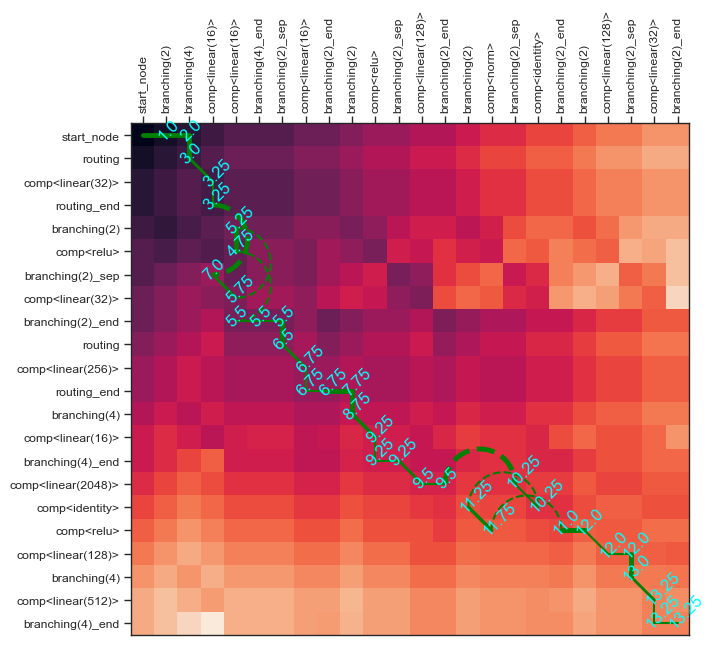

>>>Parent model 1
 sequential(sequential(sequential(branching(2){group(2,3), branching(4){clone(4), sequential(computation<linear(16)>, computation<linear(16)>), cat(4,1)}, computation<linear(16)>, cat(2,1)}, branching(2){group(2,2), computation<relu>, computation<linear(128)>, cat(2,3)}), branching(2){clone(2), computation<norm>, computation<identity>, cat(2,1)}), branching(2){group(2,3), computation<linear(128)>, computation<linear(32)>, cat(2,3)}) 
>>>Parent model 2
 sequential(sequential(sequential(sequential(sequential(sequential(routing[perm(0,2,1,3), computation<linear(32)>, perm(0,3,1,2)], branching(2){clone(2), computation<relu>, computation<linear(32)>, cat(2,3)}), routing[perm(0,3,2,1), computation<linear(256)>, perm(0,3,2,1)]), branching(4){group(4,3), computation<linear(16)>, cat(4,1)}), sequential(computation<linear(2048)>, computation<identity>)), sequential(computation<relu>, computation<linear(128)>)), branching(4){clone(4), computation<linear(512)>, cat(4,2)}) 

>>>Mu

In [116]:
matrix = AlignmentMatrixRecursive(m1, m2, verbose = True)
best_value, best_results = brute_force(m1, m2, verbose = False)
if matrix.distance != best_value: raise Exception("Model generation failed, distance is not the same as brute force")
# Mutate model 2 into model 1 and check that it is, indeed, at distance 0 from model 1
offspring = matrix.generate_offspring()
if AlignmentMatrixRecursive(m1, offspring, verbose = False).distance: raise Exception("Model generation failed, offspring is not identical to model 1")

# Calculating distances for large models

Here I just calculate the distance matrices for the combination of the ResNet, ViT and MLP-Mixer. Pretty.

In [10]:
search.limiter.timer.start()
vit = baselines.build_baseline(baselines.vit.vit_d4, input_params)
search.limiter.timer.start()
resnet = baselines.build_baseline(baselines.resnet.resnet18_no_maxpool, input_params)
search.limiter.timer.start()
mlpmixer = baselines.build_baseline(baselines.mlpmixer.mlpmixer_d8, input_params)

Limiter({'time': 300, 'max_id': 10000, 'depth': 20, 'memory': 8192, 'individual_memory': 1024, 'batch_pass_seconds': 0.1})
Limiter({'time': 300, 'max_id': 10000, 'depth': 20, 'memory': 8192, 'individual_memory': 1024, 'batch_pass_seconds': 0.1})
Limiter({'time': 300, 'max_id': 10000, 'depth': 20, 'memory': 8192, 'individual_memory': 1024, 'batch_pass_seconds': 0.1})


First model:  sequential(sequential(sequential(sequential(sequential(routing[im2col(3,1,1), computation<linear(64)>, col2im], computation<norm>), computation<relu>), routing[im2col(3,2,1), computation<linear(64)>, col2im]), sequential(sequential(sequential(branching(2){clone(2), sequential(sequential(sequential(routing[im2col(3,1,1), computation<linear(64)>, col2im], computation<norm>), computation<relu>), sequential(routing[im2col(3,1,1), computation<linear(64)>, col2im], computation<norm>)), computation<identity>, add(2)}, computation<relu>), sequential(branching(2){clone(2), sequential(sequential(sequential(routing[im2col(3,1,1), computation<linear(64)>, col2im], computation<norm>), computation<relu>), sequential(routing[im2col(3,1,1), computation<linear(64)>, col2im], computation<norm>)), computation<identity>, add(2)}, computation<relu>)), sequential(sequential(branching(2){clone(2), sequential(sequential(sequential(routing[im2col(3,2,1), computation<linear(128)>, col2im], computa

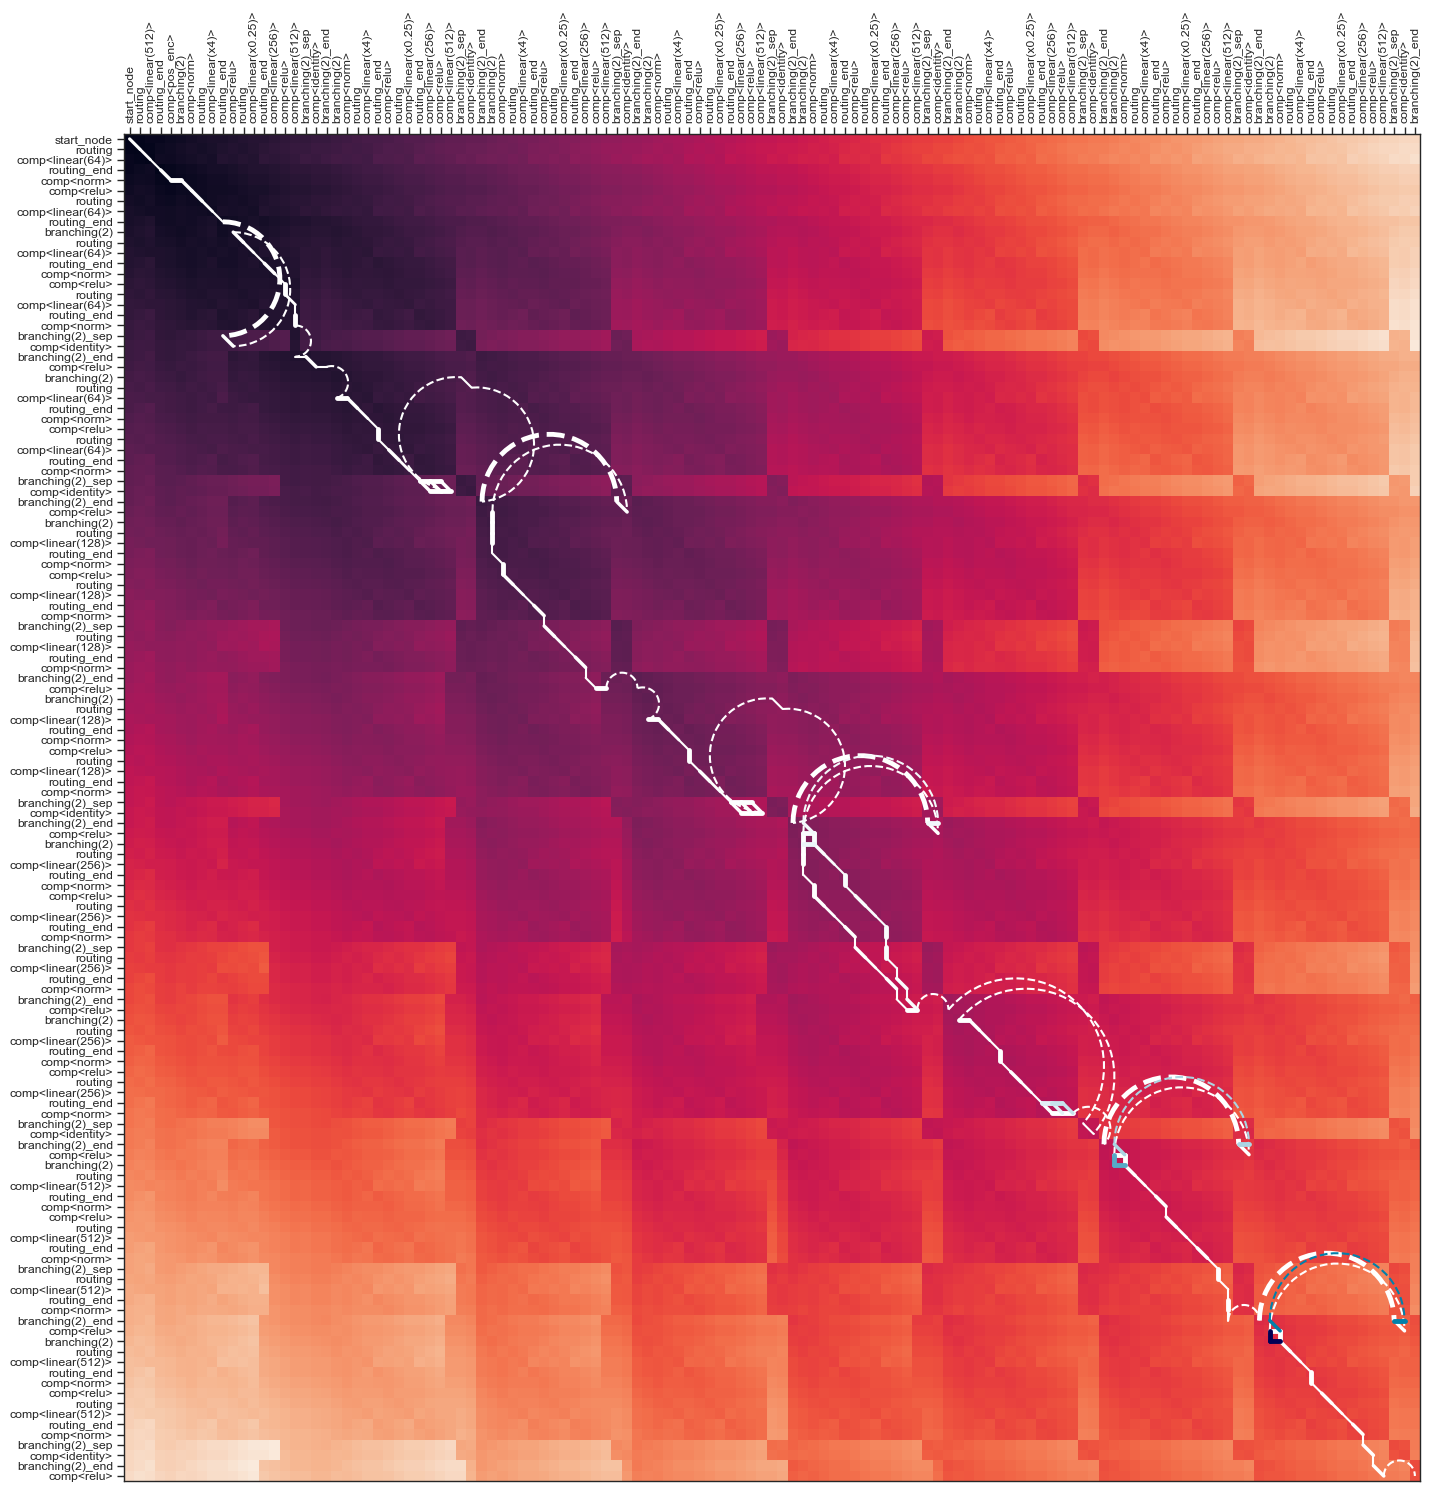

In [12]:
matrix_resnet_mlpmixer = AlignmentMatrixRecursive(resnet, mlpmixer, collapse_corners= True, img_name = "resnet_mlpmixer", verbose = True)
del matrix_resnet_mlpmixer

In [16]:
matrix_resnet_mlpmixer_nonrecursive = AlignmentMatrix(resnet, mlpmixer, collapse_corners= True, verbose = False)
ntimes = sum(["branching(2)" == node.operation.name for node in matrix_resnet_mlpmixer_nonrecursive.model_ops1+matrix_resnet_mlpmixer_nonrecursive.model_ops2])
ms = matrix_resnet_mlpmixer_nonrecursive.compute_time
print("Calculating a single nonrecursive matrix takes", ms,"ms. Thus, computing it",ntimes,"to compute the brute force approach would take", ms*ntimes,"ms.")
del matrix_resnet_mlpmixer_nonrecursive

Calculating a single nonrecursive matrix takes 347.2555019855499 ms. Thus, computing it 16 to compute the brute force approach would take 5556.088031768799 ms.


First model:  sequential(sequential(routing[im2col(4,4,0), computation<linear(512)>, identity], computation<pos_enc>), sequential(sequential(sequential(branching(2){clone(2), sequential(computation<norm>, sequential(branching(4){clone(4), branching(2){clone(2), sequential(branching(2){clone(2), computation<linear(64)>, routing[identity, computation<linear(64)>, perm(0,2,1)], dot_product(scaled)}, computation<softmax>), computation<linear(64)>, dot_product}, cat(4,2)}, computation<linear(512)>)), computation<identity>, add(2)}, branching(2){clone(2), sequential(computation<norm>, sequential(sequential(computation<linear(2048)>, computation<relu>), computation<linear(512)>)), computation<identity>, add(2)}), sequential(branching(2){clone(2), sequential(computation<norm>, sequential(branching(4){clone(4), branching(2){clone(2), sequential(branching(2){clone(2), computation<linear(64)>, routing[identity, computation<linear(64)>, perm(0,2,1)], dot_product(scaled)}, computation<softmax>), co

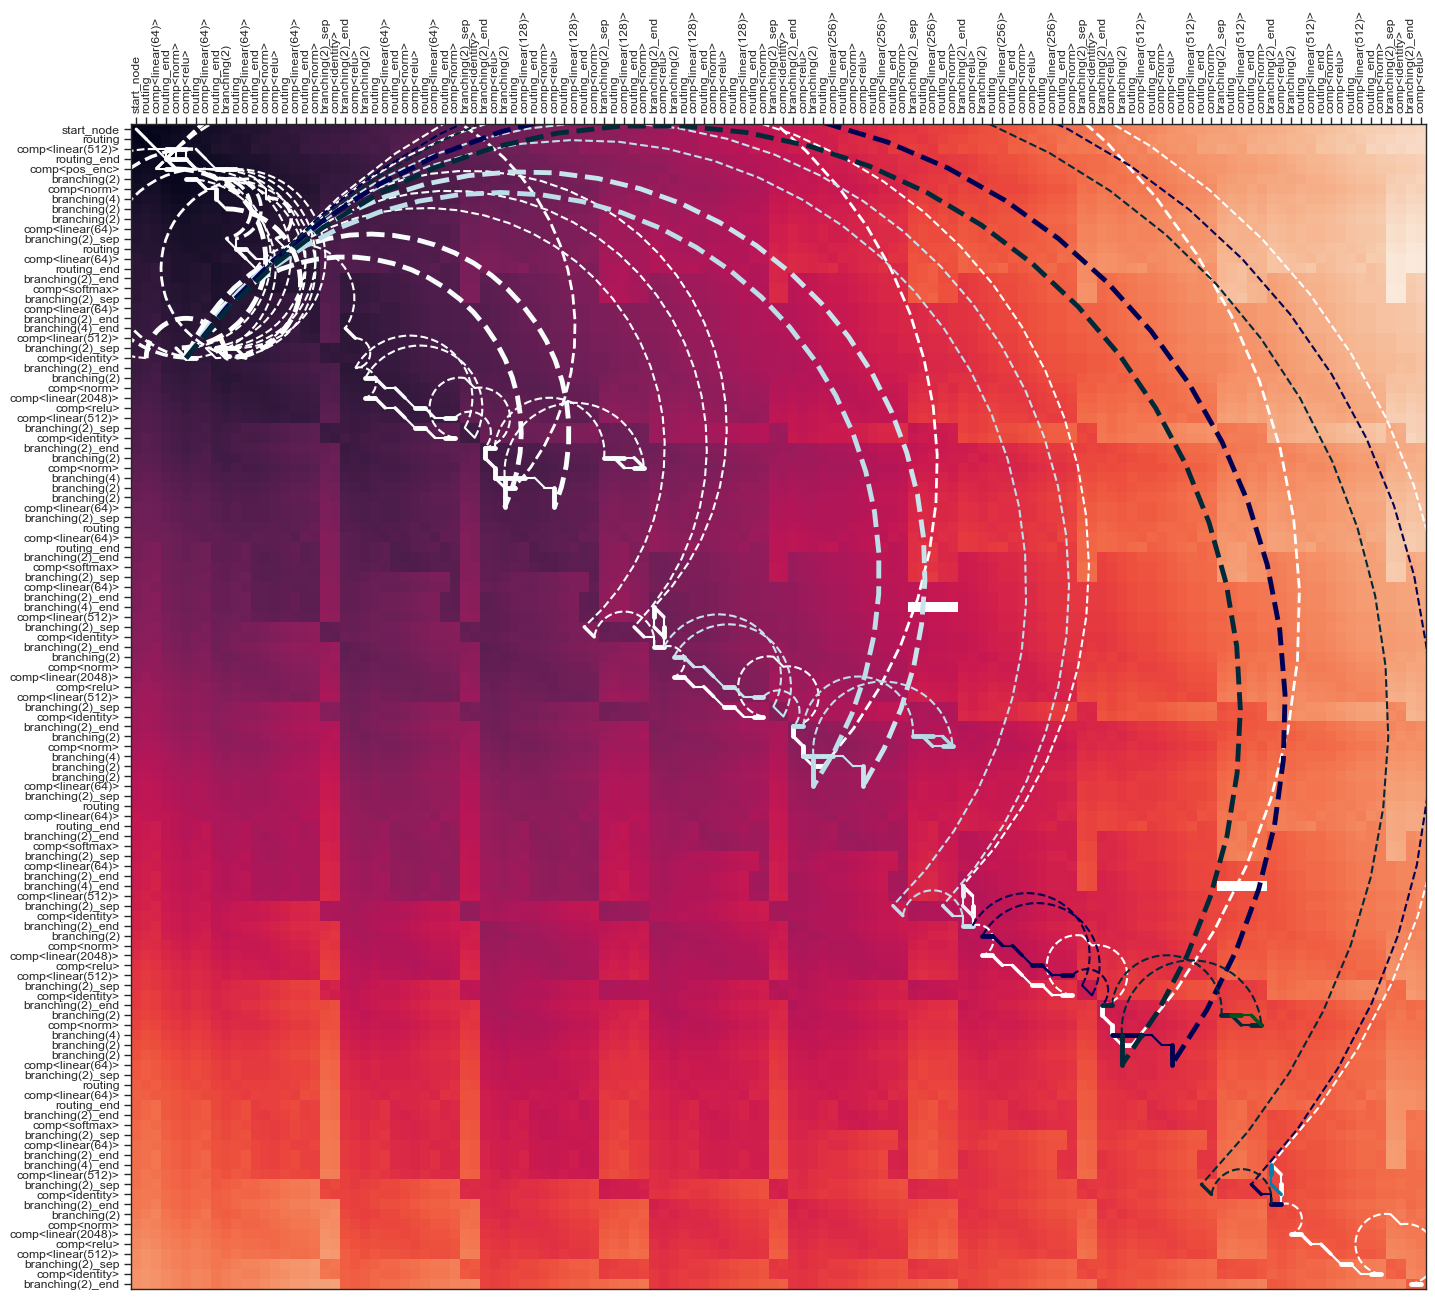

In [18]:
matrix_vit_resnet = AlignmentMatrixRecursive(vit, resnet, collapse_corners= True, img_name = "vit_resnet", verbose = True)
del matrix_vit_resnet

In [20]:
matrix_vit_resnet_nonrecursive = AlignmentMatrix(resnet, mlpmixer, collapse_corners= True, verbose = False)
ntimes = sum(["branching(2)" == node.operation.name for node in matrix_vit_resnet_nonrecursive.model_ops1+matrix_vit_resnet_nonrecursive.model_ops2])
ms = matrix_vit_resnet_nonrecursive.compute_time
print("Calculating a single nonrecursive matrix takes", ms,"ms. Thus, computing it",ntimes,"to compute the brute force approach would take", ms*ntimes,"ms.")
del matrix_vit_resnet_nonrecursive

Calculating a single nonrecursive matrix takes 355.92123794555664 ms. Thus, computing it 16 to compute the brute force approach would take 5694.739807128906 ms.


In [21]:
matrix_vit_mlpmixer = AlignmentMatrixRecursive(vit, mlpmixer, collapse_corners= True, img_name = "vit_mlpmixer", verbose = True)
del matrix_vit_mlpmixer

First model:  sequential(sequential(routing[im2col(4,4,0), computation<linear(512)>, identity], computation<pos_enc>), sequential(sequential(sequential(branching(2){clone(2), sequential(computation<norm>, sequential(branching(4){clone(4), branching(2){clone(2), sequential(branching(2){clone(2), computation<linear(64)>, routing[identity, computation<linear(64)>, perm(0,2,1)], dot_product(scaled)}, computation<softmax>), computation<linear(64)>, dot_product}, cat(4,2)}, computation<linear(512)>)), computation<identity>, add(2)}, branching(2){clone(2), sequential(computation<norm>, sequential(sequential(computation<linear(2048)>, computation<relu>), computation<linear(512)>)), computation<identity>, add(2)}), sequential(branching(2){clone(2), sequential(computation<norm>, sequential(branching(4){clone(4), branching(2){clone(2), sequential(branching(2){clone(2), computation<linear(64)>, routing[identity, computation<linear(64)>, perm(0,2,1)], dot_product(scaled)}, computation<softmax>), co

MemoryError: 

In [ ]:
matrix_vit_mlpmixer_nonrecursive = AlignmentMatrix(resnet, mlpmixer, collapse_corners= True, verbose = False)
ntimes = sum(["branching(2)" == node.operation.name for node in matrix_vit_mlpmixer_nonrecursive.model_ops1+matrix_vit_mlpmixer_nonrecursive.model_ops2])
ms = matrix_vit_mlpmixer_nonrecursive.compute_time
print("Calculating a single nonrecursive matrix takes", ms,"ms. Thus, computing it",ntimes,"to compute the brute force approach would take", ms*ntimes,"ms.")
del matrix_vit_mlpmixer_nonrecursive

# Method Comparison

In this section I compare the runtime and precission of several permutation invariance/compute time tradeoffs.

In [ ]:
class AlignmentMatrix():
    def __init__(self, model1, model2, priorities = ("mut", "add", "rem"), collapse_corners = False, verbose = False):
        self.verbose = verbose
        self.collapse_corners = collapse_corners
        
        self.model1 = model1
        if self.verbose: print("First model: ", self.model1)
        self.model_ops1 = [DecoyNode(None, None, "start_node")] + self.breakdown(self.model1)
        
        self.model2 = model2
        self.new_node_id = max([node.id for node in self.model1.serialise()])+1
        for node in self.model2.serialise(): self.update_id(node) # We reset the models' node ids to avoid anything breaking when we combine the models because of id repetitions
        if self.verbose: print("Second model:", self.model2)
        self.model_ops2 = [DecoyNode(None, None, "start_node")] + self.breakdown(self.model2)
        
        self.operations = []
        self.nontrivial_ops = []
        
        timestart = time.time()
        self.matrix = self.calculate_matrix(self.model_ops1, self.model_ops2, corner_value = 0, corner_op = "start", block_idx=(0,0), priorities = priorities)
        self.compute_time = time.time()-timestart
        #self.trace_back()
        self.distance = self.matrix[-1][-1].value
        if self.verbose:
            print("\nDistance of", round(self.distance,2), "through", len(self.nontrivial_ops), "operations, calculated in" ,round((self.compute_time)*1000,2),"ms."), self.visualize_alignment_matrix()
    
    def breakdown(self, model):
        model_ops = []
        
        condition = model.operation
        if model.parent: condition = condition and ("computation" not in model.parent.operation.name) 
            
        if condition:
            if not ("sequential" in model.operation.name):
                model_ops = [model]
                
            if len(model.children) > 2: # If we have several children (branchings, routings...)
                for child in range(1, len(model.children)-1): # And then add all the children's operations to the list
                    model_ops += self.breakdown(model.children[child])
                    model_ops += [DecoyNode(model, child, "wrap_"+"end"*(child==len(model.children)-2)+"sep"*(child!=len(model.children)-2))]
                
            else:
                for child in model.children:
                    model_ops += self.breakdown(child)
    
        return model_ops
                
    def visualize_alignment_matrix(self, matrix = None, model_ops1 = None, model_ops2 = None, i = -1, j = -1, saveimg = False):
        if matrix == None: matrix = self.matrix
        if model_ops1 == None: model_ops1 = self.model_ops1
        if model_ops2 == None: model_ops2 = self.model_ops2
        
        size = (len(matrix), len(matrix[0]))
        m = np.zeros(size)
        for ii in range(size[0]):
            for jj in range(size[1]):
                m[ii,jj] = matrix[ii][jj].value
        plt.figure(figsize=(10,10))
        plt.imshow(m)
        ax = plt.gca()
        ax.tick_params(top=True, labeltop=True, bottom=False, labelbottom=False)
        ax.set_yticks([x for x in range(len(model_ops1))])
        ax.set_yticklabels([self.get_op_name(op).replace("wrap", self.get_op_name(op.parent)) if "wrap" in self.get_op_name(op) else self.get_op_name(op) for op in model_ops1], rotation=0)
        ax.set_xticks([y for y in range(len(model_ops2))])
        ax.set_xticklabels([self.get_op_name(op).replace("wrap", self.get_op_name(op.parent)) if "wrap" in self.get_op_name(op) else self.get_op_name(op) for op in model_ops2], rotation=90)
        
        length = 1.7
        interval_space = 0.7
        linewidth = 2
        cmap = plt.get_cmap('ocean', len(matrix[i][j].paths))
        for p, path in enumerate(matrix[i][j].paths):
            position = [0, 0]
            for op in path[1:]:
                color = cmap(p)
                #plt.text(op.j-0.5, op.i+0.2, str(matrix[op.i][op.j].value), color="cyan", fontsize=12, rotation=45, rotation_mode='default')
                pos_i = np.linspace(position[0], op.i, 30)
                pos_j = np.linspace(position[1], op.j, 30)
                linestyle = "-"
                if abs(op.i-position[0]) > 1:
                    pos_j += np.linspace(-0.6, 0.6, 30)**2-0.6**2
                    linestyle = "--"
                if abs(op.j-position[1]) > 1:
                    pos_i += np.linspace(-0.6, 0.6, 30)**2-0.6**2
                    linestyle = "--"
                    
                plt.plot(pos_j, pos_i, linestyle = linestyle, color = color, linewidth=(0.75+op.value)*linewidth)
                position  = [op.i, op.j]
                
        if saveimg: plt.savefig("example_crossover.svg", format='svg')
        plt.show()

    def get_op_name(self, op):
        #if ("routing" in op.operation.name or "branching" in op.operation.name) and op.operation.name != "branching(2)": return op.operation.name.split("(")[0]
        if "computation" in op.operation.name: return "comp<"+op.children[0].operation.name+">"
        else: return op.operation.name

    def print_m(self, matrix):
        m = np.array([[row.value for row in column] for column in matrix])
        plt.imshow(m)
        plt.colorbar()
        ax = plt.gca()
        ax.tick_params(top=True, labeltop=True, bottom=False, labelbottom=False)
        ax.set_yticks([x for x in range(len(self.model_ops1))])
        ax.set_yticklabels([self.get_op_name(op).replace("wrap", self.get_op_name(op.parent)) if "wrap" in self.get_op_name(op) else self.get_op_name(op) for op in self.model_ops1], rotation=0)
        ax.set_xticks([y for y in range(len(self.model_ops2))])
        ax.set_xticklabels([self.get_op_name(op).replace("wrap", self.get_op_name(op.parent)) if "wrap" in self.get_op_name(op) else self.get_op_name(op) for op in self.model_ops2], rotation=90)
        plt.show()
    
    def calculate_matrix(self, model_ops1, model_ops2, corner_value = 0, corner_op = "start", block_idx=(0,0), priorities = ("mut", "add", "rem")):
        priorities = sorted(range(len(priorities)), key=priorities.__getitem__)
        priorities = sorted(range(len(priorities)), key=priorities.__getitem__)
        
        matrix = []
        size = (len(model_ops1), len(model_ops2))
        for i in range(size[0]): # We initialize the whole matrix with empty cells
            row = []
            for j in range(size[1]):
                row.append(MatrixCell())
            matrix.append(row)

        for i in range(size[0]):
            matrix[i][0].left = [np.inf ]
            matrix[i][0].corner = [np.inf]
        for j in range(size[1]):
            matrix[0][j].top = [np.inf]
            matrix[0][j].corner = [np.inf] 
        matrix[0][0].value = 0
        matrix[0][0].paths = [[MatrixOperation(op_id = 0, op_type = "start", node1_id = self.model_ops1[0].id, node2_id = self.model_ops2[0].id, i = 0, j = 0)]]

        for i in range(size[0]):
            for j in range(size[1]):
                if matrix[i][j].top == []:
                    for path in matrix[i-1][j].paths:
                        if model_ops1[i].operation.name in ["wrap_end", "wrap_sep"]: # If we are trying to close a new branch,
                            op = 0
                            level = 0 # we keep track of how many branches/routings we go into or exit through the current path with this "level" tracker
                            closed_branches = 0 # and the branches that we close
                            while (model_ops1[i].id != path[op].node1_id) or (path[op].op_type not in ["add_wrap", "add_wrap_jump"]):
                                op -= 1
                                # We update the depth level and the number of branches we closed
                                if (model_ops1[i].id == path[op].node1_id) and ("add" in path[op].op_type): closed_branches += 1
                                if path[op].op_type in ["rem_wrap", "mut_wrap"]: level -= 1
                                elif path[op].op_type in ["rem_wrap_end", "mut_wrap_end"]: level += 1
                                if (level == -1) or (path[op].op_type == "start"): break # If we exit the outer branch/rout, we break this loop
                            # We check that we have closed all the branches we were meant to
                            branches_to_close = len(model_ops1[i].parent.children) - 2 - (model_ops1[i].operation.name=="wrap_sep")
                            if ("_jump" in path[op].op_type): branches_to_close = 3 - branches_to_close
                            if (level==0) and (branches_to_close == closed_branches): matrix[i][j].top += [matrix[i-1][j].value] # If the branch was added within this depth, we allow the ending of the branch
                            else: matrix[i][j].top += [np.inf]
                        else: matrix[i][j].top += [matrix[i-1][j].value + 1] # If we are not trying to close a branch, we simply sum the cost of adding whatever we're adding

                if matrix[i][j].left == []:
                    for path in matrix[i][j-1].paths:
                        if model_ops2[j].operation.name in ["wrap_end", "wrap_sep"]: # If we are trying to close a branch we removed,
                            op = 0
                            level = 0 # we keep track of how many branches/routings we go into or exit through the current path with this "level" tracker
                            closed_branches = 0 # and the branches that we close
                            while (model_ops2[j].id != path[op].node2_id) or (path[op].op_type not in ["rem_wrap", "rem_wrap_jump"]):
                                op -= 1
                                # We update the depth level and the number of branches we closed
                                if (model_ops2[j].id == path[op].node2_id) and ("rem" in path[op].op_type): closed_branches += 1
                                if path[op].op_type in ["add_wrap", "mut_wrap"]: level -= 1
                                elif path[op].op_type in ["add_wrap_end", "mut_wrap_end"]: level += 1
                                if (level == -1) or (path[op].op_type == "start"): break # If we exit the outer branch/rout, we break this loop
                            # We check that we have closed all the branches we were meant to
                            branches_to_close = len(model_ops2[j].parent.children) - 2 - (model_ops2[j].operation.name=="wrap_sep")
                            if ("_jump" in path[op].op_type): branches_to_close = 3 - branches_to_close
                            if (level==0) and (branches_to_close == closed_branches): matrix[i][j].left += [matrix[i][j-1].value] # If the branch was removed within this depth, we allow the ending of the branch
                            else: matrix[i][j].left += [np.inf]
                        else: matrix[i][j].left += [matrix[i][j-1].value + 1] # If we are not trying to close a branch, we simply sum the cost of removing whatever we're removing

                if matrix[i][j].corner == []:
                    mutcost = self.cost_mut(model_ops1[i], model_ops2[j])
                    for path in matrix[i-1][j-1].paths:
                        if (model_ops1[i].operation.name in ["wrap_end", "wrap_sep"]) and (model_ops2[j].operation.name == model_ops1[i].operation.name): # If we are trying to close a branch we mutated into another,
                            op = 0
                            closed_branches1 = 0 # We keep track of how many branches we close on either model
                            closed_branches2 = 0
                            while not ((model_ops1[i].id == path[op].node1_id) and (model_ops2[j].id == path[op].node2_id) and (path[op].op_type in ["mut_wrap", "mut_wrap_jump"])): # we simply have to look at where we added/removed/mutated both branches
                                op -= 1
                                if (model_ops1[i].id == path[op].node1_id) and ("mut" in path[op].op_type): closed_branches1 += 1
                                if (model_ops2[j].id == path[op].node2_id) and ("mut" in path[op].op_type): closed_branches2 += 1
                                if (path[op].op_type == "start"): break
                            # We check that we have closed all the branches we were meant to
                            branches_to_close1 = len(model_ops1[i].parent.children) - 2 - (model_ops1[i].operation.name=="wrap_sep")
                            if ("_jump" in path[op].op_type) and ("1" in path[op].op_type): branches_to_close1 = 3 - branches_to_close1
                            branches_to_close2 = len(model_ops2[j].parent.children) - 2 - (model_ops2[j].operation.name=="wrap_sep")
                            if ("_jump" in path[op].op_type) and ("2" in path[op].op_type): branches_to_close2 = 3 - branches_to_close2
                            if (branches_to_close1 == closed_branches1) and (branches_to_close2 == closed_branches2): matrix[i][j].corner += [matrix[i-1][j-1].value] # and if the branches were mutated, we allow the ending of the branch through mutation
                            else: matrix[i][j].corner += [np.inf]
                        else: matrix[i][j].corner += [matrix[i-1][j-1].value + mutcost] # If we are not trying to close a branch, we simply sum the cost of mutating whatever we're mutating
                    
                if np.isnan(matrix[i][j].value):
                    matrix[i][j].value = np.nanmin(matrix[i][j].top + matrix[i][j].corner + matrix[i][j].left) # We check which would be the cheapest path
                    
                    for idx, top in enumerate(matrix[i][j].top):
                        if top == matrix[i][j].value:
                            path = matrix[i-1][j].paths[idx]
                            if np.isinf(matrix[i][j].value): op_value = matrix[i][j].value
                            else: op_value = matrix[i][j].value-matrix[i-1][j].value
                            if self.model_ops1[i].operation.name == "wrap_end": matrix[i][j].paths += [path + [MatrixOperation(op_id = len(path), op_type = "add_wrap_end", node1_id = self.model_ops1[i].id, node2_id = self.model_ops2[j].id, i = i, j = j)]]
                            elif self.model_ops1[i].operation.name == "wrap_sep": matrix[i][j].paths += [path + [MatrixOperation(op_id = len(path), op_type = "add_wrap_sep", node1_id = self.model_ops1[i].id, node2_id = self.model_ops2[j].id, i = i, j = j)]]    
                            elif (len(self.model_ops1[i].children) >= 3): matrix[i][j].paths += [path + [MatrixOperation(op_id = len(path), op_type = "add_wrap", node1_id = self.model_ops1[i].id, node2_id = self.model_ops2[j].id, i = i, j = j, value = op_value)]]
                            else: matrix[i][j].paths += [path + [MatrixOperation(op_id = len(self.operations), op_type = "add_module", node1_id = self.model_ops1[i].id, node2_id = self.model_ops2[j].id, i = i, j = j, value = op_value)]]
                
                    for idx, left in enumerate(matrix[i][j].left):
                        if left == matrix[i][j].value:
                            path = matrix[i][j-1].paths[idx]
                            if np.isinf(matrix[i][j].value): op_value = matrix[i][j].value
                            else: op_value = matrix[i][j].value-matrix[i][j-1].value
                            if self.model_ops2[j].operation.name == "wrap_end": matrix[i][j].paths += [path + [MatrixOperation(op_id = len(path), op_type = "rem_wrap_end", node1_id = self.model_ops1[i].id, node2_id = self.model_ops2[j].id, i = i, j = j)]]
                            elif self.model_ops2[j].operation.name == "wrap_sep": matrix[i][j].paths += [path + [MatrixOperation(op_id = len(path), op_type = "rem_wrap_sep", node1_id = self.model_ops1[i].id, node2_id = self.model_ops2[j].id, i = i, j = j)]]
                            elif (len(self.model_ops2[j].children) >= 3): matrix[i][j].paths += [path + [MatrixOperation(op_id = len(path), op_type = "rem_wrap", node1_id = self.model_ops1[i].id, node2_id = self.model_ops2[j].id, i = i, j = j, value = op_value)]]
                            else: matrix[i][j].paths += [path + [MatrixOperation(op_id = len(path), op_type = "rem", node2_id = self.model_ops2[j].id, i = i, j = j, value = op_value)]]
                    
                    for idx, corner in enumerate(matrix[i][j].corner):
                        if corner == matrix[i][j].value:
                            path = matrix[i-1][j-1].paths[idx]
                            if np.isinf(matrix[i][j].value): op_value = matrix[i][j].value
                            else: op_value = matrix[i][j].value-matrix[i-1][j-1].value
                            if self.model_ops1[i].operation.name == "wrap_end": matrix[i][j].paths += [path + [MatrixOperation(op_id = len(path), op_type = "mut_wrap_end", node1_id = self.model_ops1[i].id, node2_id = self.model_ops2[j].id, i = i, j = j)]]
                            elif self.model_ops1[i].operation.name == "wrap_sep": matrix[i][j].paths += [path + [MatrixOperation(op_id = len(path), op_type = "mut_wrap_sep", node1_id = self.model_ops1[i].id, node2_id = self.model_ops2[j].id, i = i, j = j)]]
                            elif (len(self.model_ops2[j].children) >= 3): matrix[i][j].paths += [path + [MatrixOperation(op_id = len(self.operations), op_type = "mut_wrap", node1_id = self.model_ops1[i].id, node2_id = self.model_ops2[j].id, i = i, j = j, value = op_value)]]
                            else: matrix[i][j].paths += [path + [MatrixOperation(op_id = len(path), op_type = "mut", node1_id = self.model_ops1[i].id, node2_id = self.model_ops2[j].id, i = i, j = j, value = op_value)]]

                if (i>0) and (j>0): matrix[i-1][j-1].paths = []
                if self.collapse_corners and (((j-i) >= len(self.model_ops2)*0.25) or ((i-j) >= len(self.model_ops1)*0.25)): matrix[i][j].paths = [matrix[i][j].paths[0]]

        return matrix

    def cost_mut(self, op1, op2, max_cost = np.inf):
        if "wrap_" in op1.operation.name or "wrap_" in op2.operation.name:
            return max_cost
        elif op1.operation.name.split("(")[0] == op2.operation.name.split("(")[0]:
            if max_cost == 1: # This only happens when comparing submodules
                if op1.operation == op2.operation: return 0.
                else: return 0.5
            elif sum([op.operation.name == "branching(2)" for op in (op1,op2)]) == 1: return max_cost # We can't change a branching(2) into a branching(8) for instance
            elif len(op1.children)>2: return ((self.cost_mut(op1.children[0], op2.children[0], 1))+(self.cost_mut(op1.children[-1], op2.children[-1], 1)))/4 # If we substitute a branching/branching(2)/rounting module by another, we compare the subtype of module
            else: return (self.cost_mut(op1.children[0], op2.children[0], 1))/2 # If we substitute a computation module by another, we compare the subtype of module
        else:
            return max_cost
            
    def update_id(self, node):
        node.id = self.new_node_id
        self.new_node_id += 1

    def split_sequentials(self, original_node, split_id):
        if split_id not in [n.id for n in original_node.serialise()]: raise Exception("Provided id is not within provided sequential node")
        parent_node = original_node.parent
        if not original_node.is_root(): child_idx = parent_node.children.index(original_node)
        nodes_list = original_node.children

        sequential_in_list = True
        while sequential_in_list:
            sequential_in_list = False
            for n, node in enumerate(nodes_list):
                if node.operation.name == "sequential":
                    sequential_in_list = True
                    nodes_list = nodes_list[:n] + node.children + nodes_list[n+1:]
                    break

        for n, node in enumerate(nodes_list):
            if node.id == split_id: break
        
        list1 = nodes_list[:n]
        list2 = nodes_list[n:]
        
        for _ in range(len(list1)-1):
            child2 = list1.pop()
            child1 = list1.pop()
    
            list1 += [DerivationTreeNode(0,
                                         level=node.level,
                                         parent=node.parent,
                                         input_params=node.input_params,
                                         depth=node.depth,
                                         limiter=node.limiter,
                                         operation = Operation(name="sequential",
                                                               build=einspace.build_sequential_module,
                                                               infer=einspace.infer_sequential_module,
                                                               valid=einspace.valid_sequential_module,
                                                               inherit = [einspace.inherit_first_child,einspace.inherit_other_child],
                                                               give_back = [einspace.give_back_default,einspace.give_back_default],
                                                               type="nonterminal",
                                                               child_levels=["module","module"])
                                        )]
            
            self.update_id(list1[-1])
            list1[-1].children=[child1, child2]
            child1.parent = list1[-1]
            child2.parent = list1[-1]
        
        for _ in range(len(list2)-1):
            child2 = list2.pop()
            child1 = list2.pop()
    
            list2 += [DerivationTreeNode(0,
                                         level=node.level,
                                         parent=node.parent,
                                         input_params=node.input_params,
                                         depth=node.depth,
                                         limiter=node.limiter,
                                         operation = Operation(name="sequential",
                                                               build=einspace.build_sequential_module,
                                                               infer=einspace.infer_sequential_module,
                                                               valid=einspace.valid_sequential_module,
                                                               inherit = [einspace.inherit_first_child,einspace.inherit_other_child],
                                                               give_back = [einspace.give_back_default,einspace.give_back_default],
                                                               type="nonterminal",
                                                               child_levels=["module","module"])
                                        )]
            
            self.update_id(list2[-1])
            list2[-1].children=[child1, child2]
            child1.parent = list2[-1]
            child2.parent = list2[-1]

        if len(list2):
            resequentialized_node = DerivationTreeNode(0,
                                                       level=node.level,
                                                       parent=node.parent,
                                                       input_params=node.input_params,
                                                       depth=node.depth,
                                                       limiter=node.limiter,
                                                       operation = Operation(name="sequential",
                                                                             build=einspace.build_sequential_module,
                                                                             infer=einspace.infer_sequential_module,
                                                                             valid=einspace.valid_sequential_module,
                                                                             inherit = [einspace.inherit_first_child,einspace.inherit_other_child],
                                                                             give_back = [einspace.give_back_default,einspace.give_back_default],
                                                                             type="nonterminal",
                                                                             child_levels=["module","module"])
                                                      )
            self.update_id(resequentialized_node)
            resequentialized_node.children=[list1[0], list2[0]]
            list1[0].parent = resequentialized_node
            list2[0].parent = resequentialized_node
        else:
            raise Exception("Unable to resequentialize as requested")

        if not original_node.is_root(): parent_node.children[child_idx] = resequentialized_node
        resequentialized_node.parent = parent_node
        return resequentialized_node

    def trace_back(self, from_pos = "end", prioritize = []):
        if from_pos == "end": from_pos = (len(self.model_ops1)-1, len(self.model_ops2)-1)
        if self.verbose: print("\nOperations to change from model 1 to model 2:")
        self.operations = []
        self.distance = self.matrix[-1][-1].value
        i=from_pos[0]
        j=from_pos[1]
        while not (i == 0 and j == 0):
            op = None
            for priority_op in prioritize: # We check if the prioritized operations are available (in order of priority)
                if priority_op in self.matrix[i][j].operation:
                    op = priority_op
                    break
            if not op: # If there was no priority, we simply select a random one
                op = random.choice(self.matrix[i][j].operation)
            
            if op == "add":
                value = self.matrix[i][j].value-self.matrix[i-1][j].value
                if self.model_ops1[i].operation.name == "wrap_end": self.operations += [MatrixOperation(op_id = len(self.operations),
                                                                                          op_type = "add_wrap_end",
                                                                                          node1_id = self.model_ops1[i].id,
                                                                                          node2_id = self.model_ops2[j].id,
                                                                                          i = i,
                                                                                          j = j)]
                elif self.model_ops1[i].operation.name == "wrap_sep": self.operations += [MatrixOperation(op_id = len(self.operations),
                                                                                                  op_type = "add_wrap_sep",
                                                                                                  node1_id = self.model_ops1[i].id,
                                                                                                  node2_id = self.model_ops2[j].id,
                                                                                                  i = i,
                                                                                                  j = j)]
                    
                elif (len(self.model_ops1[i].children) == 4): # If we have are adding a branching(2) (that is, parallelizing some modules),
                    for sep_idx, sep_operation in enumerate(self.operations): # we look for the corresponding branch separator
                        if (sep_operation.op_type == "add_wrap_sep") and (sep_operation.node1_id == self.model_ops1[i].id): break
                    for end_idx, end_operation in enumerate(self.operations): # and the corresponding branch end
                        if (end_operation.op_type == "add_wrap_end") and (end_operation.node1_id == self.model_ops1[i].id): break

                    disabler_ops = []
                    enabler_ops = []
                    adds = [[],[]]
                    muts = [[],[]]
                    rems = [[],[]]
                    for inside_op in self.operations[sep_idx+1:]:
                        if inside_op.op_type == "add_module": adds[0] = adds[0] + [inside_op]
                        if inside_op.op_type == "mut": muts[0] = muts[0] + [inside_op]
                        if inside_op.op_type == "rem": rems[0] = rems[0] + [inside_op]
                    if not len(muts[0]):
                        for rem_op in rems[0]:
                            rem_op.enabler_ops = rem_op.enabler_ops + adds[0]
                            rem_op.disabler_ops = rem_op.disabler_ops + [rem_op2 for rem_op2 in rems[0] if rem_op2 != rem_op]
                        disabler_ops = disabler_ops + [rems[0]]
                        enabler_ops = enabler_ops + [adds[0]*len(rems[0])]
                    for inside_op in self.operations[end_idx+1:sep_idx]:
                        if inside_op.op_type == "add_module": adds[1] = adds[1] + [inside_op]
                        if inside_op.op_type == "mut": muts[1] = muts[1] + [inside_op]
                        if inside_op.op_type == "rem": rems[1] = rems[1] + [inside_op]
                    if not len(muts[1]):
                        for rem_op in rems[1]:
                            rem_op.enabler_ops = rem_op.enabler_ops + adds[1]
                            rem_op.disabler_ops = rem_op.disabler_ops + [rem_op2 for rem_op2 in rems[1] if rem_op2 != rem_op]
                        disabler_ops = disabler_ops + [rems[1]]
                        enabler_ops = enabler_ops + [adds[1]*len(rems[1])]
                    
                    self.operations += [MatrixOperation(op_id = len(self.operations),
                                                  op_type = "add_branch2",
                                                  node1_id = self.model_ops1[i].id,
                                                  node2_id = self.model_ops2[j].id,
                                                  i = i,
                                                  j = j,
                                                  ii = (sep_operation.i,end_operation.i),
                                                  jj = (sep_operation.j,end_operation.j),
                                                  value = value,
                                                  disabler_ops = disabler_ops,
                                                  enabler_ops = enabler_ops)]
                    
                    if (len(adds[0]) and (not len(rems[0])) and (not len(muts[0]))) or (len(adds[1]) and (not len(rems[1])) and (not len(muts[1]))): # If we don't remove anything from any branch, and we have to add everything that's inside,
                        self.operations[-1].disabler_ops = self.operations[-1].disabler_ops + [[self.operations[-1]],[self.operations[-1]]] # the operation becomes its own disabler for both branches,
                        self.operations[-1].enabler_ops = self.operations[-1].enabler_ops + adds # only enabled by adding anything inside each branch first
                    if value and self.verbose: print(f"\t(+{value}) Parallelize using {self.get_op_name(self.model_ops1[i])} (id: {self.model_ops1[i+1].id}) from indexes {(i,j)} to {(end_operation.i,end_operation.j)}")
                
                elif (len(self.model_ops1[i].children) == 3): # If we have some of those "group-M-cat" or "rout-M-rout" situations,
                    for end_idx, end_operation in enumerate(self.operations): # we look for the corresponding branch end
                        if (end_operation.op_type == "add_wrap_end") and (end_operation.node1_id == self.model_ops1[i].id): break
                    
                    disabler_ops = []
                    enabler_ops = []
                    adds = []
                    muts = []
                    rems = []
                    for inside_op in self.operations[end_idx+1:]:
                        if inside_op.op_type == "add_module": adds += [inside_op]
                        if inside_op.op_type == "mut": muts += [inside_op]
                        if inside_op.op_type == "rem": rems += [inside_op]
                    if not len(muts):
                        for rem_op in rems:
                            rem_op.enabler_ops = rem_op.enabler_ops + adds
                            rem_op.disabler_ops = rem_op.disabler_ops + [rem_op2 for rem_op2 in rems if rem_op2 != rem_op]
                        disabler_ops = disabler_ops + rems
                        enabler_ops = enabler_ops + adds*len(rems)
                    
                    self.operations += [MatrixOperation(op_id = len(self.operations),
                                                  op_type = "add_wrap",
                                                  node1_id = self.model_ops1[i].id,
                                                  node2_id = self.model_ops2[j].id,
                                                  i = i,
                                                  j = j,
                                                  ii = end_operation.i,
                                                  jj = end_operation.j,
                                                  value = value,
                                                  disabler_ops = disabler_ops,
                                                  enabler_ops = enabler_ops)]

                    if len(adds) and (not len(rems)) and (not len(muts)): # If we don't remove anything, and we have to add everything that's inside,
                        self.operations[-1].disabler_ops = self.operations[-1].disabler_ops + [self.operations[-1]] # the operation becomes its own disabler,
                        self.operations[-1].enabler_ops = self.operations[-1].enabler_ops + adds # only enabled by adding anything inside the wrapper first
                    if value and self.verbose: print(f"\t(+{value}) Add wrapper {self.get_op_name(self.model_ops1[i])} (id: {self.model_ops1[i+1].id}) from indexes {(i,j)} to {(end_operation.i,end_operation.j)}")
                else:
                    self.operations += [MatrixOperation(op_id = len(self.operations),
                                                      op_type = "add_module",
                                                      node1_id = self.model_ops1[i].id,
                                                      node2_id = self.model_ops2[j].id,
                                                      i = i,
                                                      j = j,
                                                      value = value)]
                    if value and self.verbose: print(f"\t(+{value}) Add {self.get_op_name(self.model_ops1[i])} (id: {self.model_ops1[i].id}) at indexes {(i,j)}")
                i -= 1

            elif op == "rem":
                if self.model_ops2[j].operation.name == "wrap_end": self.operations += [MatrixOperation(op_id = len(self.operations),
                                                                                          op_type = "rem_wrap_end",
                                                                                          node1_id = self.model_ops1[i].id,
                                                                                          node2_id = self.model_ops2[j].id,
                                                                                          i = i,
                                                                                          j = j)]
                elif self.model_ops2[j].operation.name == "wrap_sep": self.operations += [MatrixOperation(op_id = len(self.operations),
                                                                                                  op_type = "rem_wrap_sep",
                                                                                                  node1_id = self.model_ops1[i].id,
                                                                                                  node2_id = self.model_ops2[j].id,
                                                                                                  i = i,
                                                                                                  j = j)]
                else:
                    value = self.matrix[i][j].value-self.matrix[i][j-1].value
                    self.operations += [MatrixOperation(op_id = len(self.operations),
                                                  op_type = "rem",
                                                  node2_id = self.model_ops2[j].id,
                                                  i = i,
                                                  j = j,
                                                  value = value)]
                    
                    if (len(self.model_ops2[j].children) == 3): # If we have some of those "group-M-cat" or "rout-M-rout" situations,
                        for end_idx, end_operation in enumerate(self.operations):
                            if (end_operation.op_type == "rem_wrap_end") and (end_operation.node2_id == self.model_ops2[j].id): break # we look for the corresponding branch end,
                        adds = []
                        muts = []
                        rems = []
                        for inside_op in self.operations[end_idx+1:-1]: # check the operations we perform and,
                            if inside_op.op_type == "add_module": adds += [inside_op]
                            if inside_op.op_type == "mut": muts += [inside_op]
                            if inside_op.op_type == "rem": rems += [inside_op]
                        if not len(muts): # if we are not forced to have modules inside regardless of the operations we perform,
                            for rem_op in rems:
                                rem_op.disabler_ops = rem_op.disabler_ops + rems # we forbid removing all layers inside the wrap
                                rem_op.enabler_ops = rem_op.enabler_ops + adds + [self.operations[-1]] # unless we add any layer, or remove the wrap itself
                    
                    elif (len(self.model_ops2[j].children) == 4): # If we have are removing a branching(2) (that is, serializing some modules),
                        for sep_idx, sep_operation in enumerate(self.operations): # we look for the corresponding branch separator
                            if (sep_operation.op_type == "rem_wrap_sep") and (sep_operation.node2_id == self.model_ops2[j].id): break
                        for end_idx, end_operation in enumerate(self.operations): # and the corresponding branch end
                            if (end_operation.op_type == "rem_wrap_end") and (end_operation.node2_id == self.model_ops2[j].id): break
                        adds = [[],[]]
                        muts = [[],[]]
                        rems = [[],[]] # and, for each branch
                        for inside_op in self.operations[sep_idx+1:-1]:
                            if inside_op.op_type == "add_module": adds[0] += [inside_op]
                            if inside_op.op_type == "mut": muts[0] += [inside_op]
                            if inside_op.op_type == "rem": rems[0] += [inside_op]
                        if not len(muts[0]): # if we are not forced to have modules inside the branch regardless of the operations we perform,
                            for rem_op in rems[0]:
                                rem_op.disabler_ops = rem_op.disabler_ops + rems[0] # we forbid removing all layers inside the branch
                                rem_op.enabler_ops = rem_op.enabler_ops + adds[0] + [self.operations[-1]] # unless we add any layer, or remove the wrap itself
                        for inside_op in self.operations[end_idx+1:sep_idx]:
                            if inside_op.op_type == "add_module": adds[1] += [inside_op]
                            if inside_op.op_type == "mut": muts[1] += [inside_op]
                            if inside_op.op_type == "rem": rems[1] += [inside_op]
                        if not len(muts[1]):
                            for rem_op in rems[1]:
                                rem_op.disabler_ops = rem_op.disabler_ops + rems[1]
                                rem_op.enabler_ops = rem_op.enabler_ops + adds[1] + [self.operations[-1]]
                        
                    if value and self.verbose: print(f"\t(+{value}) Remove {self.get_op_name(self.model_ops2[j])} (id: {self.model_ops2[j].id}) at indexes {(i,j)}")
                j -=1

            elif op == "mut":
                if self.model_ops1[i].operation.name == "wrap_end": self.operations += [MatrixOperation(op_id = len(self.operations),
                                                                                          op_type = "mut_wrap_end",
                                                                                          node1_id = self.model_ops1[i].id,
                                                                                          node2_id = self.model_ops2[j].id,
                                                                                          i = i,
                                                                                          j = j)]
                elif self.model_ops1[i].operation.name == "wrap_sep": self.operations += [MatrixOperation(op_id = len(self.operations),
                                                                                          op_type = "mut_wrap_sep",
                                                                                          node1_id = self.model_ops1[i].id,
                                                                                          node2_id = self.model_ops2[j].id,
                                                                                          i = i,
                                                                                          j = j)]
                else:
                    value = self.matrix[i][j].value-self.matrix[i-1][j-1].value
                    self.operations += [MatrixOperation(op_id = len(self.operations),
                                                  op_type = "mut",
                                                  node1_id = self.model_ops1[i].id,
                                                  node2_id = self.model_ops2[j].id,
                                                  i = i,
                                                  j = j,
                                                  value = value)]
                    if value and self.verbose: print(f"\t(+{value}) Substitute {self.get_op_name(self.model_ops2[j])} (id: {self.model_ops2[j].id}) by {self.get_op_name(self.model_ops1[i])} (id: {self.model_ops1[i].id}) at indexes {(i,j)}")
                i -= 1
                j -= 1
            
        self.nontrivial_ops = [operation for operation in self.operations if operation.value]
    
    def generate_offspring(self, selected_ops = None):
        if selected_ops == None: selected_ops = self.nontrivial_ops
        if self.verbose: print(">>>Parent model 1\n",colored(self.model2, "red"), "\n>>>Parent model 2\n",colored(self.model1, "green"),"\n")
        
        self.performed_ops = []
        offspring = self.apply_all_operations(selected_ops, copy.deepcopy(self.model2))
        
        if self.verbose: print(">>>Final model\n", colored(offspring, "yellow"))
        return offspring

    def apply_all_operations(self, selected_ops, offspring):
        for op in selected_ops:
            if len(op.enabler_ops): # If we have operations to perform beforehand, we perform them
                for branch in op.enabler_ops:
                    if type(branch) != list: branch = [branch]
                    for op in branch: offspring = self.apply_all_operations([r_op for r_op in branch if r_op in selected_ops], offspring)
            offspring = self.apply_op(op, offspring)
        return offspring

    def apply_op(self, op, offspring):
        if op.id not in self.performed_ops:
            self.performed_ops += [op.id]
            if op.op_type == "mut":
                for node in self.model_ops1:
                    if node.id == op.node1_id:
                        node1 = copy.deepcopy(node)
                        break

                for node in offspring.serialise():
                    if (node.id == op.node2_id) or (node.id == op.node1_id):
                        node2 = copy.deepcopy(node)
                        break
                if (not node1.id == op.node1_id) or ((not node.id == op.node2_id) and (not node.id == op.node1_id)): raise Exception("Nodes to mutate not found")
                
                node1str = str(node1)
                if ("branching" in node1.operation.name): node1str = node1str.split(")")[0]+")"+node1str.split(")")[1]+")...}"
                if ("routing" in node1.operation.name): node1str = node1str.split(")")[0]+")...]"
                node2str = str(node2)
                if ("branching" in node2.operation.name): node2str = node2str.split(")")[0]+")"+node2str.split(")")[1]+")...}"
                if ("routing" in node2.operation.name): node2str = node2str.split(")")[0]+")...]"
                if self.verbose: print(">>>Mutating",colored(node2str, "red"),"into", colored(node1str, "green"))
                
                node1.parent = node2.parent
                if not node2.is_root(): node2.parent.children[node2.parent.children.index(node2)] = node1
                
                if ("branching" in node1.operation.name) or ("routing" in node1.operation.name):
                    node1.children[1] = node2.children[1]
                    node1.children[1].parent = node1
                    if ("branching(2)" in node1.operation.name):
                        node1.children[2] = node2.children[2]
                        node1.children[2].parent = node1
                
                offspring = node1.get_root()
                                    
            elif op.op_type == "rem":
                for node in offspring.serialise():
                    if node.id == op.node2_id:
                        break
                if (not node.id == op.node2_id): print(">>>Tried to remove module with id", colored(op.node2_id, "red"), "but it was not found.")
                else:
                    if "branching(2)" in node.operation.name:
                        b1 = node.children[1]
                        b2 = node.children[2]
                        if self.verbose: print(">>>Serializing branches",colored(str(b1), "red"),"and",colored(str(b2), "red"))
                        
                        sequential_node = DerivationTreeNode(0,
                                                             level=node.level,
                                                             parent=node.parent,
                                                             input_params=node.input_params,
                                                             depth=node.depth,
                                                             limiter=node.limiter,
                                                             operation = Operation(name="sequential",
                                                                                   build=einspace.build_sequential_module,
                                                                                   infer=einspace.infer_sequential_module,
                                                                                   valid=einspace.valid_sequential_module,
                                                                                   inherit = [einspace.inherit_first_child,einspace.inherit_other_child],
                                                                                   give_back = [einspace.give_back_default,einspace.give_back_default],
                                                                                   type="nonterminal",
                                                                                   child_levels=["module","module"])
                                                        )
                        self.update_id(sequential_node)
                        sequential_node.children=[b1, b2]
                        b1.parent = sequential_node
                        b2.parent = sequential_node
                        if node.parent: node.parent.children[node.parent.children.index(node)] = sequential_node
                        offspring = sequential_node.get_root()
                        
                    else:
                        nodestr = str(node)
                        if ("branching" in node.operation.name): nodestr = nodestr.split(")")[0]+")"+nodestr.split(")")[1]+")...}"
                        if ("routing" in node.operation.name): nodestr = nodestr.split(")")[0]+")...]"
                        if self.verbose: print(">>>Removing", colored(nodestr, "red"))
                            
                        parent_node = node.parent
                        
                        if ("branching" in node.operation.name) or ("routing" in node.operation.name):
                            if parent_node: parent_node.children[parent_node.children.index(node)] = node.children[1]
                            node.children[1].parent = node.parent
                            offspring = node.children[1].get_root()
                        else:
                            sibling_node = parent_node.children[parent_node.children.index(node)-1]
                            if not parent_node.is_root():
                                sibling_node.parent = parent_node.parent
                                parent_node.parent.children[parent_node.parent.children.index(parent_node)] = sibling_node
                            else:
                                sibling_node.parent = None
                                
                            offspring = sibling_node.get_root()
                            
            elif op.op_type == "add_module":
                for node in self.model_ops1:
                    if node.id == op.node1_id:
                        node1 = copy.deepcopy(node)
                        break
                if (not node1.id == op.node1_id): raise Exception("Node",op.node1_id,"not found from model 1 when attempting module addition")
                if op.node2_id == -1:
                    node2 = offspring
                    add_at_the_end = False
                else:
                    last_node_pos = [0,0] # We look for the id of the node we want to add the module before
                    jjj = 1 # which will come from the second model if we parallelized the first branch
                    if op.j+jjj < len(self.model_ops2):
                        while self.model_ops2[op.j+jjj].id not in [n.id for n in offspring.serialise()]:
                            jjj += 1
                            if op.j+jjj == len(self.model_ops2): break
                    if op.j+jjj < len(self.model_ops2):
                        op_name2 = self.model_ops2[op.j+jjj].operation.name
                        while offspring.serialise()[last_node_pos[0]].id != self.model_ops2[op.j+jjj].id:
                            last_node_pos[0] = last_node_pos[0] + 1
                            if last_node_pos[0] == len(offspring.serialise()): break
                    else:
                        op_name2 = ""
                        last_node_pos[0] = len(offspring.serialise())
                    iii = 0 # or from the first model if we added the first branch
                    if op.i+iii < len(self.model_ops1):
                        while self.model_ops1[op.i+iii].id not in [n.id for n in offspring.serialise()]:
                            iii += 1
                            if op.i+iii == len(self.model_ops1): break
                    if op.i+iii < len(self.model_ops1):
                        op_name1 = self.model_ops1[op.i+iii].operation.name
                        while offspring.serialise()[last_node_pos[1]].id != self.model_ops1[op.i+iii].id:
                            last_node_pos[1] = last_node_pos[1] + 1
                            if last_node_pos[1] == len(offspring.serialise()): break
                    else:
                        op_name1 = ""
                        last_node_pos[1] = len(offspring.serialise())

                    if min(last_node_pos) == len(offspring.serialise()):
                        node2 = node1
                        node1 = offspring
                        add_at_the_end = True
                    
                    else:
                        pos_scores = last_node_pos.copy()
                        if (pos_scores[0] < len(offspring.serialise())) and ("wrap_" in op_name2): pos_scores[0] = pos_scores[0] + num_of_children(offspring.serialise()[last_node_pos[0]])
                        if (pos_scores[1] < len(offspring.serialise())) and ("wrap_" in op_name1): pos_scores[1] = pos_scores[1] + num_of_children(offspring.serialise()[last_node_pos[1]])
                        chosen_pos = pos_scores.index(min(pos_scores))
                        if ["wrap_" in op_name2, "wrap_" in op_name1][chosen_pos]:
                            node2 = node1
                            node1 = offspring.serialise()[last_node_pos[chosen_pos]].children[-2]
                            add_at_the_end = True
                        else:
                            node2 = offspring.serialise()[last_node_pos[chosen_pos]]
                            add_at_the_end = False
                
                sequential_node = DerivationTreeNode(0,
                                                     level=node.level,
                                                     parent=None,
                                                     input_params=node.input_params,
                                                     depth=node2.depth,
                                                     limiter=node.limiter,
                                                     operation = Operation(name="sequential",
                                                                           build=einspace.build_sequential_module,
                                                                           infer=einspace.infer_sequential_module,
                                                                           valid=einspace.valid_sequential_module,
                                                                           inherit = [einspace.inherit_first_child,einspace.inherit_other_child],
                                                                           give_back = [einspace.give_back_default,einspace.give_back_default],
                                                                           type="nonterminal",
                                                                           child_levels=["module","module"])
                                                )

                self.update_id(sequential_node)
                
                if add_at_the_end:
                    sequential_node.parent = node1.parent
                    if not node1.is_root():
                        node1.parent.children[node1.parent.children.index(node1)] = sequential_node
                else:
                    sequential_node.parent = node2.parent
                    if not node2.is_root():
                        node2.parent.children[node2.parent.children.index(node2)] = sequential_node
                    
                sequential_node.children=[node1, node2]
                node1.parent = sequential_node
                node2.parent = sequential_node
                
                offspring = sequential_node.get_root()
                
                if self.verbose:
                    if add_at_the_end: print(">>>Adding", colored(str(node2), "green"), "after", colored(str(node1), "red"))
                    else: print(">>>Adding", colored(str(node1), "green"), "before", colored(str(node2), "red"))
                
            elif op.op_type == "add_wrap":
                for node in self.model_ops1:
                    if node.id == op.node1_id:
                        node1 = copy.deepcopy(node)
                        break
                
                split_pos = [0,0] # We look for the id of the node we want to start the wrap at
                jjj = 1 # which will come from the second model if we parallelized the first branch
                if op.j+jjj < len(self.model_ops2):
                    while ("wrap_" in self.model_ops2[op.j+jjj].operation.name) or (self.model_ops2[op.j+jjj].id not in [n.id for n in offspring.serialise()]):
                        jjj += 1
                        if op.j+jjj == len(self.model_ops2): break
                if op.j+jjj < len(self.model_ops2):
                    while offspring.serialise()[split_pos[0]].id != self.model_ops2[op.j+jjj].id:
                        split_pos[0] = split_pos[0] + 1
                        if split_pos[0] == len(offspring.serialise()): break
                else: split_pos[0] = len(offspring.serialise())
                iii = 0 # or from the first model if we added the first branch
                if op.i+iii < len(self.model_ops1):
                    while ("wrap_" in self.model_ops1[op.i+iii].operation.name) or (self.model_ops1[op.i+iii].id not in [n.id for n in offspring.serialise()]):
                        iii += 1
                        if op.i+iii == len(self.model_ops1): break
                if op.i+iii < len(self.model_ops1):
                    while offspring.serialise()[split_pos[1]].id != self.model_ops1[op.i+iii].id:
                        split_pos[1] = split_pos[1] + 1
                        if split_pos[1] == len(offspring.serialise()): break
                else: split_pos[1] = len(offspring.serialise())
                
                node = offspring.serialise()[min(split_pos)]
                # If the previous layer we found is the start of a branch/rout coming from the first model, we are interested on its children
                if (len(node.children) == 3) and (min(split_pos) == split_pos[0]): node = node.children[1]
                starting_node = node
                split_pos = [0,0] # We look for the id of the next node after we end the wrap
                jjj = 0 # which will come from the second model if we didn't have to add the inside modules
                if op.jj+jjj < len(self.model_ops2):
                    op_name2 = self.model_ops2[op.jj+jjj].operation.name
                    while self.model_ops2[op.jj+jjj].id not in [n.id for n in offspring.serialise()]:
                        jjj += 1
                        if op.jj+jjj == len(self.model_ops2): break
                if op.jj+jjj < len(self.model_ops2):
                    while offspring.serialise()[split_pos[0]].id != self.model_ops2[op.jj+jjj].id:
                        split_pos[0] = split_pos[0] + 1
                        if split_pos[0] == len(offspring.serialise()): break
                else:
                    op_name2 = ""
                    split_pos[0] = len(offspring.serialise())
                iii = 0 # or from the first model if we did
                if op.ii+iii < len(self.model_ops1):
                    while self.model_ops1[op.ii+iii].id not in [n.id for n in offspring.serialise()]:
                        iii += 1
                        if op.ii+iii == len(self.model_ops1): break
                if op.ii+iii < len(self.model_ops1):
                    op_name1 = self.model_ops1[op.ii+iii].operation.name
                    while offspring.serialise()[split_pos[1]].id != self.model_ops1[op.ii+iii].id:
                        split_pos[1] = split_pos[1] + 1
                        if split_pos[1] == len(offspring.serialise()): break
                else:
                    op_name1 = ""
                    split_pos[1] = len(offspring.serialise())
                
                if min(split_pos) == len(offspring.serialise()): # If we need to wrap up until the end of the model
                    split_pos = len(offspring.serialise())
                    found_parent_sequential = False
                    while not found_parent_sequential: # We need to find the sequential node that holds the modules up to the end of the model
                        if not node.is_root():
                            if (node.parent.operation.name == "sequential") and (offspring.serialise()[-1] not in node.serialise()): node = node.parent 
                            else: found_parent_sequential = True
                        else: found_parent_sequential = True
                else: # If we need to wrap up until a certain module
                    if split_pos[0] == len(offspring.serialise()): split_pos[0] = -1
                    if split_pos[1] == len(offspring.serialise()): split_pos[1] = -1
                    chosen_pos = split_pos.index(max(split_pos))
                    split_pos = split_pos[chosen_pos]
                    found_parent_sequential = False
                    while not found_parent_sequential: # We need to find the sequential node that holds up to the module we woould like to wrap
                        if not node.is_root():
                            if (node.parent.operation.name == "sequential") and (offspring.serialise()[split_pos] not in node.serialise()): node = node.parent 
                            else: found_parent_sequential = True
                        else: found_parent_sequential = True
                
                if (split_pos == len(offspring.serialise())) or ["wrap_" in op_name2, "wrap_" in op_name1][chosen_pos]: end_at_id = -1 # If we are wrapping until the end of the model nor a wrap_end,
                else: end_at_id = offspring.serialise()[split_pos].id # we save the id of the last node to split the sequentials at further on
                
                if node.operation.name == "sequential":
                    try:
                        node = self.split_sequentials(node, starting_node.id).children[1] # We resequentialize the modules to be able to fit the wrap where we want it to be
                    except: # If we couldn't split it, it means that the original sequential already started with the first module we are insterested in
                        node = node
                else: node = node
                if node.operation.name == "sequential": # If  we are wrapping a sequential module
                    if end_at_id != -1: # and we have a valid end id,
                        try: node2 = self.split_sequentials(node, end_at_id).children[0] # we resequentialize the modules to be able to fit the wrap where we want it to be
                        except: node2 = node
                    else: node2 = node
                else: node2 = node

                if self.verbose: print(">>>Adding wrapper", colored(node1.operation.name, "green"), "around", colored(str(node2), "red"))
                node1.parent = node2.parent
                if not node2.is_root(): node2.parent.children[node2.parent.children.index(node2)] = node1
                node1.children[1] = node2
                node2.parent = node1
                offspring = node1.get_root()

            elif op.op_type == "add_branch2":
                for node in self.model_ops1:
                    if node.id == op.node1_id:
                        node1 = copy.deepcopy(node)
                        break

                split_pos = [0, 0] # We look for the id of the node we want to start the parallelization at
                jjj = 1 # which will come from the second model if we already had the first node from the first branch
                if op.j+jjj < len(self.model_ops2):
                    while ("wrap_" in self.model_ops2[op.j+jjj].operation.name) or (self.model_ops2[op.j+jjj].id not in [n.id for n in offspring.serialise()]):
                        jjj += 1
                        if op.j+jjj == len(self.model_ops2): break
                if op.j+jjj < len(self.model_ops2):
                    while offspring.serialise()[split_pos[0]].id != self.model_ops2[op.j+jjj].id:
                        split_pos[0] = split_pos[0] + 1
                        if split_pos[0] == len(offspring.serialise()): break
                else: split_pos[0] = len(offspring.serialise())
                
                iii = 0 # or from the first model if we had to add the first node from the first branch
                if op.i+iii < len(self.model_ops1):
                    while ("wrap_" in self.model_ops1[op.i+iii].operation.name) or (self.model_ops1[op.i+iii].id not in [n.id for n in offspring.serialise()]):
                        iii += 1
                        if op.i+iii == len(self.model_ops1): break
                if op.i+iii < len(self.model_ops1):
                    while offspring.serialise()[split_pos[1]].id != self.model_ops1[op.i+iii].id:
                        split_pos[1] += 1
                        if split_pos[1] == len(offspring.serialise()): break
                else: split_pos[1] = len(offspring.serialise())

                node = offspring.serialise()[min(split_pos)]
                starting_node = node

                split_pos = [0,0] # We look for the id of the next node after we end the second branch
                jjj = 1 # which will come from the second model if we already had it in the offspring
                if op.jj[1]+jjj < len(self.model_ops2):
                    op_name2 = self.model_ops2[op.jj[1]+jjj].operation.name
                    while self.model_ops2[op.jj[1]+jjj].id not in [n.id for n in offspring.serialise()]:
                        jjj += 1
                        if op.jj[1]+jjj == len(self.model_ops2): break
                if op.jj[1]+jjj < len(self.model_ops2):
                    while offspring.serialise()[split_pos[0]].id != self.model_ops2[op.jj[1]+jjj].id:
                        split_pos[0] = split_pos[0] + 1
                        if split_pos[0] == len(offspring.serialise()): break
                else:
                    op_name2 = ""
                    split_pos[0] = len(offspring.serialise())
                    
                iii = 0 # or from the first model if we didn't
                if op.ii[1]+iii < len(self.model_ops1):
                    while self.model_ops1[op.ii[1]+iii].id not in [n.id for n in offspring.serialise()]:
                        iii += 1
                        if op.ii[1]+iii == len(self.model_ops1): break
                if op.ii[1]+iii < len(self.model_ops1):
                    op_name1 = self.model_ops1[op.ii[1]+iii].operation.name
                    while offspring.serialise()[split_pos[1]].id != self.model_ops1[op.ii[1]+iii].id:
                        split_pos[1] = split_pos[1] + 1
                        if split_pos[1] == len(offspring.serialise()): break
                else:
                    op_name1 = ""
                    split_pos[1] = len(offspring.serialise())

                if min(split_pos) == len(offspring.serialise()): # If we need to wrap up until the end of the model
                    split_pos = len(offspring.serialise())
                    found_parent_sequential = False
                    while not found_parent_sequential: # We need to find the sequential node that holds the modules up to the end of the model
                        if not node.is_root():
                            if (node.parent.operation.name == "sequential") and (offspring.serialise()[-1] not in node.serialise()): node = node.parent 
                            else: found_parent_sequential = True
                        else: found_parent_sequential = True
                else: # If we need to wrap up until a certain module
                    if split_pos[0] == len(offspring.serialise()): split_pos[0] = -1
                    if split_pos[1] == len(offspring.serialise()): split_pos[1] = -1
                    chosen_pos = split_pos.index(max(split_pos))
                    split_pos = split_pos[chosen_pos]
                    found_parent_sequential = False
                    while not found_parent_sequential: # We need to find the sequential node that holds up to the module we woould like to wrap
                        if not node.is_root():
                            if (node.parent.operation.name == "sequential") and (offspring.serialise()[split_pos] not in node.serialise()): node = node.parent 
                            else: found_parent_sequential = True
                        else: found_parent_sequential = True

                if (split_pos == len(offspring.serialise())) or ["wrap_" in op_name2, "wrap_" in op_name1][chosen_pos]: end_at_id = -1 # If we are wrapping until the end of the model nor a wrap_end,
                else: end_at_id = offspring.serialise()[split_pos].id # we save the id of the last node to split the sequentials at further on
                    
                if node.operation.name == "sequential":
                    try:
                        node = self.split_sequentials(node, starting_node.id).children[1] # We resequentialize the modules to be able to fit the branch(2) where we want it to be
                    except: # If we couldn't split it, it means that the original sequential already started with the first module we are insterested in
                        node = node
                else: node = node

                if node.operation.name == "sequential": # If  we are wrapping a sequential module
                    if end_at_id != -1: # and we have a valid end id,
                        try: node2 = self.split_sequentials(node, end_at_id).children[0] # we resequentialize the modules to be able to fit the wrap where we want it to be
                        except: node2 = node
                    else: node2 = node
                else: node2 = node

                split_pos = [0, 0] # We look for the id of the node we want to start the second branch at
                jjj = 1 # which will come from the second model if we already had the second branch
                if op.jj[0]+jjj < len(self.model_ops2):
                    while ("wrap_" in self.model_ops2[op.jj[0]+jjj].operation.name) or (self.model_ops2[op.jj[0]+jjj].id not in [n.id for n in node2.serialise()]):
                        jjj += 1
                        if op.jj[0]+jjj == len(self.model_ops2): break
                if op.jj[0]+jjj < len(self.model_ops2):
                    while node2.serialise()[split_pos[0]].id != self.model_ops2[op.jj[0]+jjj].id:
                        split_pos[0] = split_pos[0] + 1
                        if split_pos[0] == len(node2.serialise()): break
                else: split_pos[0] = len(node2.serialise())
                
                iii = 0 # or from the first model if we added the second branch
                if op.ii[0]+iii < len(self.model_ops1):
                    while ("wrap_" in self.model_ops1[op.ii[0]+iii].operation.name) or (self.model_ops1[op.ii[0]+iii].id not in [n.id for n in node2.serialise()]):
                        iii += 1
                        if op.ii[0]+iii == len(self.model_ops1): break
                if op.ii[0]+iii < len(self.model_ops1):
                    while node2.serialise()[split_pos[1]].id != self.model_ops1[op.ii[0]+iii].id:
                        split_pos[1] += 1
                        if split_pos[1] == len(node2.serialise()): break
                else: split_pos[1] = len(node2.serialise())

                if (node2.operation.name == "sequential") and (min(split_pos) < len(node2.serialise())):
                    node2 = self.split_sequentials(node2, node2.serialise()[min(split_pos)].id) # We resequentialize the modules to be able to split the branches right where we want to
                else: node2 = node2

                if self.verbose: print(">>>Parallelizing modules", colored(str(node2.children[0]), "red"), "and", colored(str(node2.children[1]), "red"), "using", colored(node1.operation.name, "green"))

                parent_node = node2.parent
                if not node2.is_root(): parent_node.children[parent_node.children.index(node2)] = node1
                node1.parent = parent_node
                node1.children[1] = node2.children[0]
                node1.children[2] = node2.children[1]
                node2.children[0].parent = node1
                node2.children[1].parent = node1
                offspring = node1.get_root()
            
            if self.verbose and ("wrap_end" not in op.op_type) and ("wrap_sep" not in op.op_type): print("",colored(offspring, "light_grey"), "\n")
        return offspring


def num_of_children(node, n = 0):
    for child in node.children:
        n = n + 1 + num_of_children(child)
    return n


def select_operations(operations, skewness = 0):
    combinations = {}
    for i in range(2**len(operations)):
        combo_str = bin(i)[2:].zfill(len(operations))
        ops = [op for idx, op in enumerate(operations) if combo_str[idx] == "1"]
        value = sum([op.value for op in ops])
        for op in ops:
            # We take all enabler operations and separate them by branch (we add non-branch operations as if they were a branch)
            enablers = [op_en for op_en in op.enabler_ops if type(op_en) == list] + [[op_en for op_en in op.enabler_ops if type(op_en) != list]]
            # We do the same for the disabler operations
            disablers = [op_dis for op_dis in op.disabler_ops if type(op_dis) == list] + [[op_dis for op_dis in op.disabler_ops if type(op_dis) != list]]
            for b in range(len(enablers)):
                if len(disablers[b]) and all([disabler in ops for disabler in disablers[b]]) and (not any([enabler in ops for enabler in enablers[b]])): value = np.nan
        if not np.isnan(value): combinations[combo_str] = value

    sknorm = skewnorm(skewness)
    sample_resolution = 4
    sample_at = np.linspace(sknorm.ppf(0.01), sknorm.ppf(0.99), int(combinations[max(combinations)]*sample_resolution))
    samples = sknorm.pdf(sample_at)
    probs = [samples[int(combinations[c]*sample_resolution)-1] for c in combinations]
    probs /= np.sum(probs)
    
    selected = np.random.choice([c for c in combinations], p = probs)
    
    return [operations[i] for i, v in enumerate(selected) if v == "1"]


def constrained_smith_waterman_crossover(parent1, parent2):
    # build alignment matrix
    matrix = AlignmentMatrix(parent1, parent2, priorities=("mut", "add", "rem"), verbose=False)
    operations = matrix.nontrivial_ops
    if len(operations) == 0:
        return parent1, []
    else:
        # sample random operations along the shortest path
        selected_ops = select_operations(operations)
        # perform the operations to generate the offspring
        child = matrix.generate_offspring(selected_ops, skewness = 0)
        return child, corrected_ops

def compile_fn(node, args):
    backbone = node.build(node, set_memory_checkpoint=True)
    return Network(
        backbone,
        node.output_params["shape"],
        args.num_classes,
        vars(args)
    ).to(args.device)

In [6]:
def best_swap_alternating(model1, model2, verbose = False):
    b2s_first_model = sum([node.operation.name == "branching(2)" for node in model1.serialise()])
    b2s_second_model = sum([node.operation.name == "branching(2)" for node in model2.serialise()])
    if verbose: print("model1 has",b2s_first_model,"branching(2)s\nmodel2 has",b2s_second_model,"branching(2)s\n")
    
    time1 = time.time()
    combo_swap1 = f'{0:0{b2s_first_model}b}'
    combo_swap2 = f'{0:0{b2s_second_model}b}'
    matrix = AlignmentMatrix(model1, model2, priorities = ("mut", "add", "rem"), verbose = False)
    results = [(matrix.matrix[-1][-1].value, combo_swap1, combo_swap2)]
    best_results = [(matrix.matrix[-1][-1].value, combo_swap1, combo_swap2)]
    if verbose: print("First single alignment in", time.time()-time1,"seconds")
    
    time0 = time.time()
    finish = False
    swap_model_1 = True
    while not finish:
        finish = True
        time1 = time.time()
        if swap_model_1:
            swap_model_1 = False
            for result in best_results:
                # We fix the swap of the branches in the second model
                combo_swap2 = result[2]
                model2_swapped = copy.deepcopy(model2)
                n = 0
                for node in model2_swapped.serialise():
                    if node.operation.name == "branching(2)":
                        if combo_swap2[n] == "1":
                            node.children = [node.children[child] for child in [0,2,1,3]]
                        n += 1
                
                for swap1 in range(2**b2s_first_model):
                    # We swap the corresponding branches in the first model
                    combo_swap1 = f'{swap1:0{b2s_first_model}b}'
                    # We check that we have not calculated this combination of swaps already
                    repeated = False
                    for result in results:
                        if (result[1] == combo_swap1) and (result[2] == combo_swap2):
                            repeated = True
                            break
                    # If we haven't, we calculate the alignment
                    if not repeated:
                        finish = False
                        model1_swapped = copy.deepcopy(model1)
                        n = 0
                        for node in model1_swapped.serialise():
                            if node.operation.name == "branching(2)":
                                if combo_swap1[n] == "1":
                                    node.children = [node.children[child] for child in [0,2,1,3]]
                                n += 1
                        matrix = AlignmentMatrix(model1_swapped, model2_swapped, priorities = ("mut", "add", "rem"), verbose = False)
                        results += [(matrix.matrix[-1][-1].value, combo_swap1, combo_swap2)]
            if (not finish) and verbose: print("model1 swaps calculated in in", time.time()-time1,"seconds")
    
        else:
            swap_model_1 = True
            # We repeat the same thing, fixing the first model
            for result in best_results:
                # We fix the swap of the branches in the first model
                combo_swap1 = result[1]
                model1_swapped = copy.deepcopy(model1)
                n = 0
                for node in model1_swapped.serialise():
                    if node.operation.name == "branching(2)":
                        if combo_swap1[n] == "1":
                            node.children = [node.children[child] for child in [0,2,1,3]]
                        n += 1
                
                for swap2 in range(2**b2s_second_model):
                    # We swap the corresponding branches in the second model
                    combo_swap2 = f'{swap2:0{b2s_second_model}b}'
                    # We check that we have not calculated this combination of swaps already
                    repeated = False
                    for result in results:
                        if (result[1] == combo_swap1) and (result[2] == combo_swap2):
                            repeated = True
                            break
                    # If we haven't, we calculate the alignment
                    if not repeated:
                        finish = False
                        model2_swapped = copy.deepcopy(model2)
                        n = 0
                        for node in model2_swapped.serialise():
                            if node.operation.name == "branching(2)":
                                if combo_swap2[n] == "1":
                                    node.children = [node.children[child] for child in [0,2,1,3]]
                                n += 1
                        matrix = AlignmentMatrix(model1_swapped, model2_swapped, priorities = ("mut", "add", "rem"), verbose = False)
                        results += [(matrix.matrix[-1][-1].value, combo_swap1, combo_swap2)]
            if (not finish) and verbose: print("model2 swaps calculated in in", time.time()-time1,"seconds")
                
        # We select the best combination found so far
        best_value = min([result[0] for result in results])
        best_results = [result for result in results if result[0] == best_value]
        if (not finish) and verbose: print("Best results so far:", best_results, "\n")
    
    if verbose: print("\nBest swap calculated in",time.time()-time0,"seconds.\nBest swaps found:\n", best_results)
    return best_value, best_results

In [7]:
def brute_force(model1, model2, verbose = False):
    results = []
    b2s_first_model = sum([node.operation.name == "branching(2)" for node in model1.serialise()])
    b2s_second_model = sum([node.operation.name == "branching(2)" for node in model2.serialise()])
    if verbose: print("model1 has",b2s_first_model,"branching(2)s\nmodel2 has",b2s_second_model,"branching(2)s\n")

    
    time1 = time.time()
    for swap1 in range(2**b2s_first_model):
        # We swap the corresponding branches
        combo_swap1 = f'{swap1:0{b2s_first_model}b}'
        model1_swapped = copy.deepcopy(model1)
        n = 0
        for node in model1_swapped.serialise():
            if node.operation.name == "branching(2)":
                if combo_swap1[n] == "1":
                    node.children = [node.children[child] for child in [0,2,1,3]]
                n += 1
        
        for swap2 in range(2**b2s_second_model):
            # We swap the corresponding branches
            combo_swap2 = f'{swap2:0{b2s_second_model}b}'
            model2_swapped = copy.deepcopy(model2)
            n = 0
            for node in model2_swapped.serialise():
                if node.operation.name == "branching(2)":
                    if combo_swap2[n] == "1":
                        node.children = [node.children[child] for child in [0,2,1,3]]
                    n += 1
            
            matrix = AlignmentMatrix(model1_swapped, model2_swapped, priorities = ("mut", "add", "rem"), verbose = False)
            results += [(matrix.matrix[-1][-1].value, combo_swap1, combo_swap2)]

    best_value = min([result[0] for result in results])
    best_results = [result for result in results if result[0] == best_value]
    if verbose: print("Best swap (value of "+str(best_value)+") found in in", time.time()-time1,"seconds")
        
    return best_value, best_results

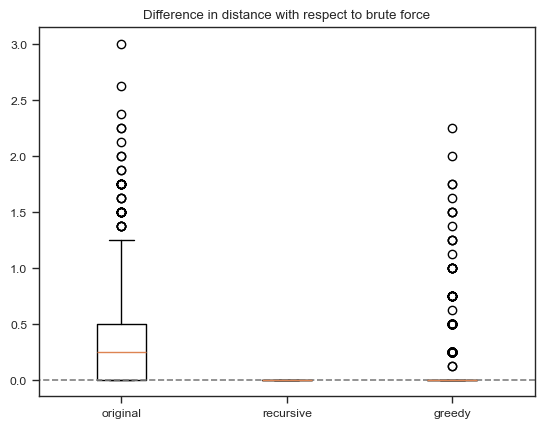

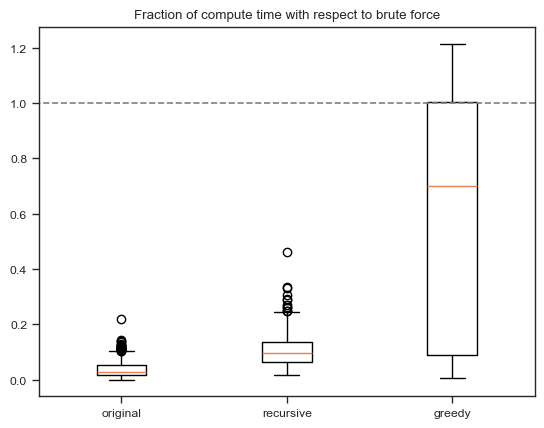

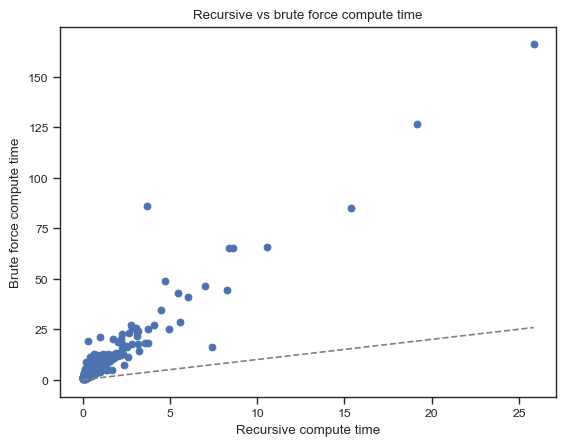

In [7]:
results_big_seq_b2 = {"original" :    {"distance" : [], "compute time" : []},
                      "recursive" :   {"distance" : [], "compute time" : []},
                      "greedy" :      {"distance" : [], "compute time" : []},
                      "brute force" : {"distance" : [], "compute time" : []}}

for i in range(30):
    with open(r"models_big/seq/"+str(i)+".pkl", "rb") as f:
        m1 = pickle.load(f)
    for ii in range(30):
        with open(r"models_big/b2/"+str(ii)+".pkl", "rb") as f:
            m2 = pickle.load(f)
            
        t1 = time.time()
        matrix = AlignmentMatrix(m1, m2, verbose = False)
        results_big_seq_b2["original"]["distance"] += [matrix.matrix[-1][-1].value]
        results_big_seq_b2["original"]["compute time"] += [time.time()-t1]
        
        t1 = time.time()
        matrix = AlignmentMatrixRecursive(m1, m2, verbose = False)
        results_big_seq_b2["recursive"]["distance"] += [matrix.distance]
        results_big_seq_b2["recursive"]["compute time"] += [time.time()-t1]
        
        t1 = time.time()
        best_value, best_results = best_swap_alternating(m1, m2, verbose = False)
        results_big_seq_b2["greedy"]["distance"] += [best_value]
        results_big_seq_b2["greedy"]["compute time"] += [time.time()-t1]
        
        t1 = time.time()
        best_value, best_results = brute_force(m1, m2, verbose = False)
        results_big_seq_b2["brute force"]["distance"] += [best_value]
        results_big_seq_b2["brute force"]["compute time"] += [time.time()-t1]

plt.boxplot([np.array(results_big_seq_b2["original"]["distance"])-np.array(results_big_seq_b2["brute force"]["distance"]),
             np.array(results_big_seq_b2["recursive"]["distance"])-np.array(results_big_seq_b2["brute force"]["distance"]),
             np.array(results_big_seq_b2["greedy"]["distance"])-np.array(results_big_seq_b2["brute force"]["distance"])]);

ax = plt.gca()
ax.set_xticks([1,2,3])
ax.set_xticklabels(["original","recursive","greedy"])
plt.title("Difference in distance with respect to brute force")
plt.plot((0,4),(0,0), "--", c="grey")
plt.xlim((0.5,3.5))
plt.show();

plt.boxplot([np.array(results_big_seq_b2["original"]["compute time"])/np.array(results_big_seq_b2["brute force"]["compute time"]),
             np.array(results_big_seq_b2["recursive"]["compute time"])/np.array(results_big_seq_b2["brute force"]["compute time"]),
             np.array(results_big_seq_b2["greedy"]["compute time"])/np.array(results_big_seq_b2["brute force"]["compute time"])]);

ax = plt.gca()
ax.set_xticks([1,2,3])
ax.set_xticklabels(["original","recursive","greedy"])
plt.title("Fraction of compute time with respect to brute force")
plt.plot((0,4),(1,1), "--", c="grey")
plt.xlim((0.5,3.5))
plt.show();

plt.scatter(results_big_seq_b2["recursive"]["compute time"], results_big_seq_b2["brute force"]["compute time"])
plt.ylabel("Brute force compute time")
plt.xlabel("Recursive compute time")
plt.plot((0,min(max(results_big_seq_b2["recursive"]["compute time"]),max(results_big_seq_b2["brute force"]["compute time"]))),(0,min(max(results_big_seq_b2["recursive"]["compute time"]),max(results_big_seq_b2["brute force"]["compute time"]))), "--", c="grey")
plt.title("Recursive vs brute force compute time")
plt.show()

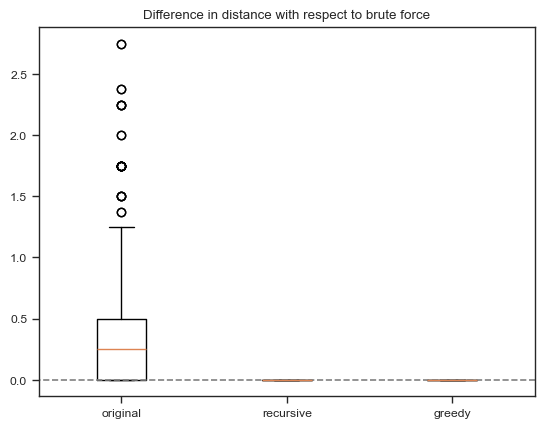

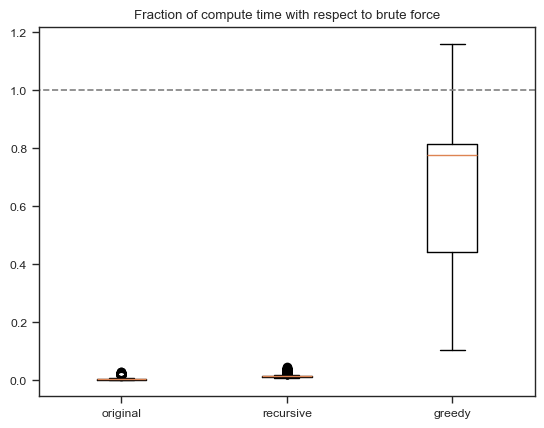

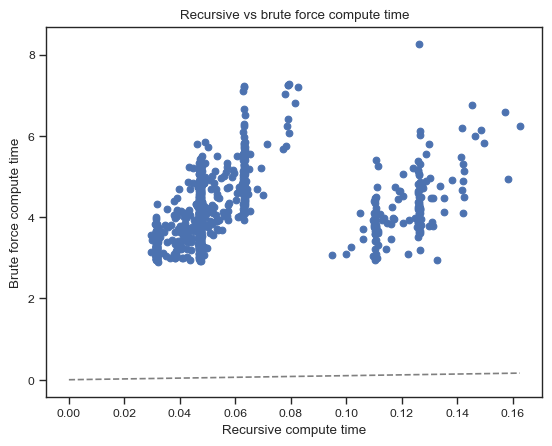

In [8]:
results_big_b2_b2 = {"original" :    {"distance" : [], "compute time" : []},
                      "recursive" :   {"distance" : [], "compute time" : []},
                      "greedy" :      {"distance" : [], "compute time" : []},
                      "brute force" : {"distance" : [], "compute time" : []}}

for i in range(30):
    with open(r"models_big/b2/"+str(i)+".pkl", "rb") as f:
        m1 = pickle.load(f)
    for ii in range(30):
        with open(r"models_big/b2/"+str(ii)+".pkl", "rb") as f:
            m2 = pickle.load(f)
            
        t1 = time.time()
        matrix = AlignmentMatrix(m1, m2, verbose = False)
        results_big_b2_b2["original"]["distance"] += [matrix.matrix[-1][-1].value]
        results_big_b2_b2["original"]["compute time"] += [time.time()-t1]
        
        t1 = time.time()
        matrix = AlignmentMatrixRecursive(m1, m2, verbose = False)
        results_big_b2_b2["recursive"]["distance"] += [matrix.matrix[-1][-1].value]
        results_big_b2_b2["recursive"]["compute time"] += [time.time()-t1]
        
        t1 = time.time()
        best_value, best_results = best_swap_alternating(m1, m2, verbose = False)
        results_big_b2_b2["greedy"]["distance"] += [best_value]
        results_big_b2_b2["greedy"]["compute time"] += [time.time()-t1]
        
        t1 = time.time()
        best_value, best_results = brute_force(m1, m2, verbose = False)
        results_big_b2_b2["brute force"]["distance"] += [best_value]
        results_big_b2_b2["brute force"]["compute time"] += [time.time()-t1]

plt.boxplot([np.array(results_big_b2_b2["original"]["distance"])-np.array(results_big_b2_b2["brute force"]["distance"]),
             np.array(results_big_b2_b2["recursive"]["distance"])-np.array(results_big_b2_b2["brute force"]["distance"]),
             np.array(results_big_b2_b2["greedy"]["distance"])-np.array(results_big_b2_b2["brute force"]["distance"])]);

ax = plt.gca()
ax.set_xticks([1,2,3])
ax.set_xticklabels(["original","recursive","greedy"])
plt.title("Difference in distance with respect to brute force")
plt.plot((0,4),(0,0), "--", c="grey")
plt.xlim((0.5,3.5))
plt.show();

plt.boxplot([np.array(results_big_b2_b2["original"]["compute time"])/np.array(results_big_b2_b2["brute force"]["compute time"]),
             np.array(results_big_b2_b2["recursive"]["compute time"])/np.array(results_big_b2_b2["brute force"]["compute time"]),
             np.array(results_big_b2_b2["greedy"]["compute time"])/np.array(results_big_b2_b2["brute force"]["compute time"])]);

ax = plt.gca()
ax.set_xticks([1,2,3])
ax.set_xticklabels(["original","recursive","greedy"])
plt.title("Fraction of compute time with respect to brute force")
plt.plot((0,4),(1,1), "--", c="grey")
plt.xlim((0.5,3.5))
plt.show();

plt.scatter(results_big_b2_b2["recursive"]["compute time"], results_big_b2_b2["brute force"]["compute time"])
plt.ylabel("Brute force compute time")
plt.xlabel("Recursive compute time")
plt.plot((0,min(max(results_big_b2_b2["recursive"]["compute time"]),max(results_big_b2_b2["brute force"]["compute time"]))),(0,min(max(results_big_b2_b2["recursive"]["compute time"]),max(results_big_b2_b2["brute force"]["compute time"]))), "--", c="grey")
plt.title("Recursive vs brute force compute time")
plt.show()

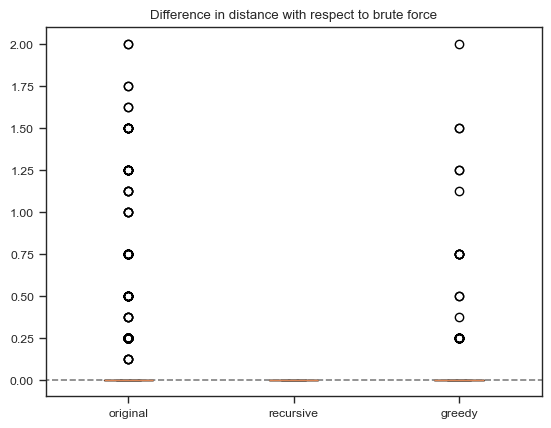

C:\Users\agomez\AppData\Local\Temp\ipykernel_110948\1390746164.py:45: RuntimeWarning: divide by zero encountered in divide
  plt.boxplot([np.array(results_big_seq_seq["original"]["compute time"])/np.array(results_big_seq_seq["brute force"]["compute time"]),
C:\Users\agomez\AppData\Local\Temp\ipykernel_110948\1390746164.py:46: RuntimeWarning: divide by zero encountered in divide
  np.array(results_big_seq_seq["recursive"]["compute time"])/np.array(results_big_seq_seq["brute force"]["compute time"]),
C:\Users\agomez\AppData\Local\Temp\ipykernel_110948\1390746164.py:47: RuntimeWarning: divide by zero encountered in divide
  np.array(results_big_seq_seq["greedy"]["compute time"])/np.array(results_big_seq_seq["brute force"]["compute time"])]);


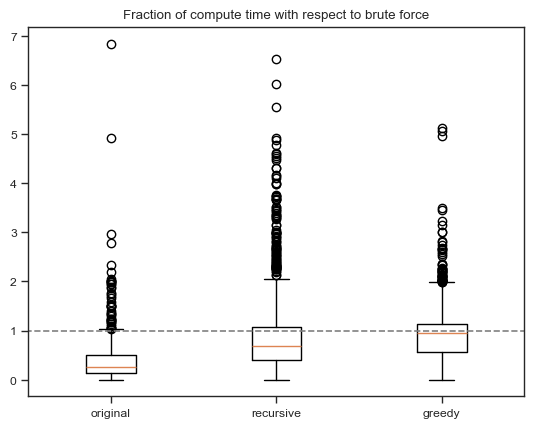

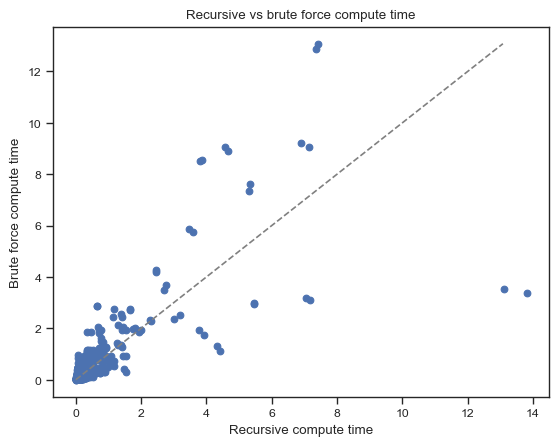

In [9]:
results_big_seq_seq = {"original" :    {"distance" : [], "compute time" : []},
                      "recursive" :   {"distance" : [], "compute time" : []},
                      "greedy" :      {"distance" : [], "compute time" : []},
                      "brute force" : {"distance" : [], "compute time" : []}}

for i in range(30):
    with open(r"models_big/seq/"+str(i)+".pkl", "rb") as f:
        m1 = pickle.load(f)
    for ii in range(30):
        with open(r"models_big/seq/"+str(ii)+".pkl", "rb") as f:
            m2 = pickle.load(f)
            
        t1 = time.time()
        matrix = AlignmentMatrix(m1, m2, verbose = False)
        results_big_seq_seq["original"]["distance"] += [matrix.matrix[-1][-1].value]
        results_big_seq_seq["original"]["compute time"] += [time.time()-t1]
        
        t1 = time.time()
        matrix = AlignmentMatrixRecursive(m1, m2, verbose = False)
        results_big_seq_seq["recursive"]["distance"] += [matrix.matrix[-1][-1].value]
        results_big_seq_seq["recursive"]["compute time"] += [time.time()-t1]
        
        t1 = time.time()
        best_value, best_results = best_swap_alternating(m1, m2, verbose = False)
        results_big_seq_seq["greedy"]["distance"] += [best_value]
        results_big_seq_seq["greedy"]["compute time"] += [time.time()-t1]
        
        t1 = time.time()
        best_value, best_results = brute_force(m1, m2, verbose = False)
        results_big_seq_seq["brute force"]["distance"] += [best_value]
        results_big_seq_seq["brute force"]["compute time"] += [time.time()-t1]

plt.boxplot([np.array(results_big_seq_seq["original"]["distance"])-np.array(results_big_seq_seq["brute force"]["distance"]),
             np.array(results_big_seq_seq["recursive"]["distance"])-np.array(results_big_seq_seq["brute force"]["distance"]),
             np.array(results_big_seq_seq["greedy"]["distance"])-np.array(results_big_seq_seq["brute force"]["distance"])]);

ax = plt.gca()
ax.set_xticks([1,2,3])
ax.set_xticklabels(["original","recursive","greedy"])
plt.title("Difference in distance with respect to brute force")
plt.plot((0,4),(0,0), "--", c="grey")
plt.xlim((0.5,3.5))
plt.show();

plt.boxplot([np.array(results_big_seq_seq["original"]["compute time"])/np.array(results_big_seq_seq["brute force"]["compute time"]),
             np.array(results_big_seq_seq["recursive"]["compute time"])/np.array(results_big_seq_seq["brute force"]["compute time"]),
             np.array(results_big_seq_seq["greedy"]["compute time"])/np.array(results_big_seq_seq["brute force"]["compute time"])]);

ax = plt.gca()
ax.set_xticks([1,2,3])
ax.set_xticklabels(["original","recursive","greedy"])
plt.title("Fraction of compute time with respect to brute force")
plt.plot((0,4),(1,1), "--", c="grey")
plt.xlim((0.5,3.5))
plt.show();

plt.scatter(results_big_seq_seq["recursive"]["compute time"], results_big_seq_seq["brute force"]["compute time"])
plt.ylabel("Brute force compute time")
plt.xlabel("Recursive compute time")
plt.plot((0,min(max(results_big_seq_seq["recursive"]["compute time"]),max(results_big_seq_seq["brute force"]["compute time"]))),(0,min(max(results_big_seq_seq["recursive"]["compute time"]),max(results_big_seq_seq["brute force"]["compute time"]))), "--", c="grey")
plt.title("Recursive vs brute force compute time")
plt.show()

900it [01:34,  9.52it/s]


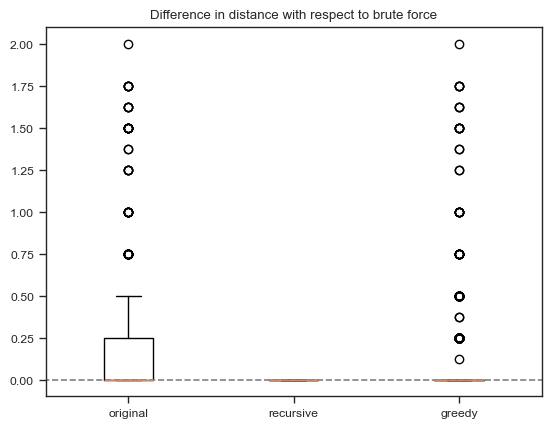

C:\Users\agomez\AppData\Local\Temp\ipykernel_110948\3299045452.py:47: RuntimeWarning: divide by zero encountered in divide
  plt.boxplot([np.array(results_small_seq_b2["original"]["compute time"])/np.array(results_small_seq_b2["brute force"]["compute time"]),
C:\Users\agomez\AppData\Local\Temp\ipykernel_110948\3299045452.py:48: RuntimeWarning: divide by zero encountered in divide
  np.array(results_small_seq_b2["recursive"]["compute time"])/np.array(results_small_seq_b2["brute force"]["compute time"]),
C:\Users\agomez\AppData\Local\Temp\ipykernel_110948\3299045452.py:49: RuntimeWarning: divide by zero encountered in divide
  np.array(results_small_seq_b2["greedy"]["compute time"])/np.array(results_small_seq_b2["brute force"]["compute time"])]);


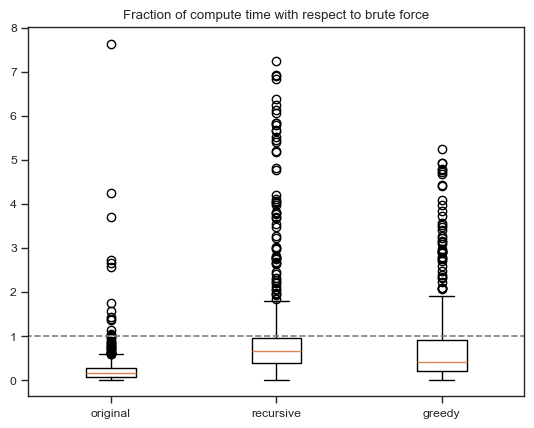

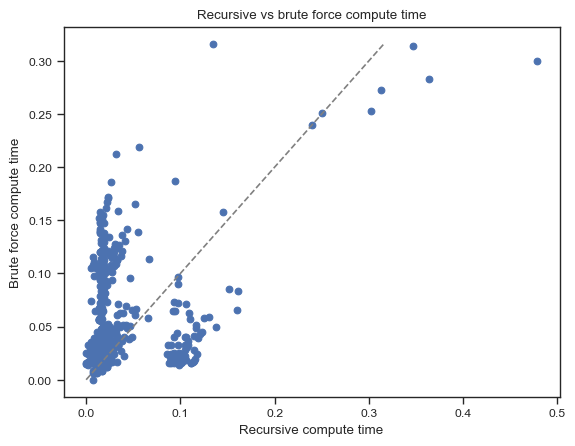

In [10]:
results_small_seq_b2 = {"original" :    {"distance" : [], "compute time" : []},
                      "recursive" :   {"distance" : [], "compute time" : []},
                      "greedy" :      {"distance" : [], "compute time" : []},
                      "brute force" : {"distance" : [], "compute time" : []}}

with tqdm(900) as pbar:
    for i in range(30):
        with open(r"models/seq/"+str(i)+".pkl", "rb") as f:
            m1 = pickle.load(f)
        for ii in range(30):
            with open(r"models/b2/"+str(ii)+".pkl", "rb") as f:
                m2 = pickle.load(f)
                
            t1 = time.time()
            matrix = AlignmentMatrix(m1, m2, verbose = False)
            results_small_seq_b2["original"]["distance"] += [matrix.matrix[-1][-1].value]
            results_small_seq_b2["original"]["compute time"] += [time.time()-t1]
            
            t1 = time.time()
            matrix = AlignmentMatrixRecursive(m1, m2, verbose = False)
            results_small_seq_b2["recursive"]["distance"] += [matrix.matrix[-1][-1].value]
            results_small_seq_b2["recursive"]["compute time"] += [time.time()-t1]
            
            t1 = time.time()
            best_value, best_results = best_swap_alternating(m1, m2, verbose = False)
            results_small_seq_b2["greedy"]["distance"] += [best_value]
            results_small_seq_b2["greedy"]["compute time"] += [time.time()-t1]
            
            t1 = time.time()
            best_value, best_results = brute_force(m1, m2, verbose = False)
            results_small_seq_b2["brute force"]["distance"] += [best_value]
            results_small_seq_b2["brute force"]["compute time"] += [time.time()-t1]
            pbar.update()

plt.boxplot([np.array(results_small_seq_b2["original"]["distance"])-np.array(results_small_seq_b2["brute force"]["distance"]),
             np.array(results_small_seq_b2["recursive"]["distance"])-np.array(results_small_seq_b2["brute force"]["distance"]),
             np.array(results_small_seq_b2["greedy"]["distance"])-np.array(results_small_seq_b2["brute force"]["distance"])]);

ax = plt.gca()
ax.set_xticks([1,2,3])
ax.set_xticklabels(["original","recursive","greedy"])
plt.title("Difference in distance with respect to brute force")
plt.plot((0,4),(0,0), "--", c="grey")
plt.xlim((0.5,3.5))
plt.show();

plt.boxplot([np.array(results_small_seq_b2["original"]["compute time"])/np.array(results_small_seq_b2["brute force"]["compute time"]),
             np.array(results_small_seq_b2["recursive"]["compute time"])/np.array(results_small_seq_b2["brute force"]["compute time"]),
             np.array(results_small_seq_b2["greedy"]["compute time"])/np.array(results_small_seq_b2["brute force"]["compute time"])]);

ax = plt.gca()
ax.set_xticks([1,2,3])
ax.set_xticklabels(["original","recursive","greedy"])
plt.title("Fraction of compute time with respect to brute force")
plt.plot((0,4),(1,1), "--", c="grey")
plt.xlim((0.5,3.5))
plt.show();

plt.scatter(results_small_seq_b2["recursive"]["compute time"], results_small_seq_b2["brute force"]["compute time"])
plt.ylabel("Brute force compute time")
plt.xlabel("Recursive compute time")
plt.plot((0,min(max(results_small_seq_b2["recursive"]["compute time"]),max(results_small_seq_b2["brute force"]["compute time"]))),(0,min(max(results_small_seq_b2["recursive"]["compute time"]),max(results_small_seq_b2["brute force"]["compute time"]))), "--", c="grey")
plt.title("Recursive vs brute force compute time")
plt.show()

900it [01:57,  7.63it/s]


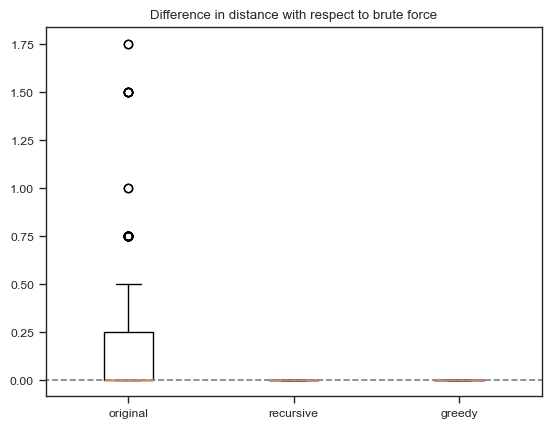

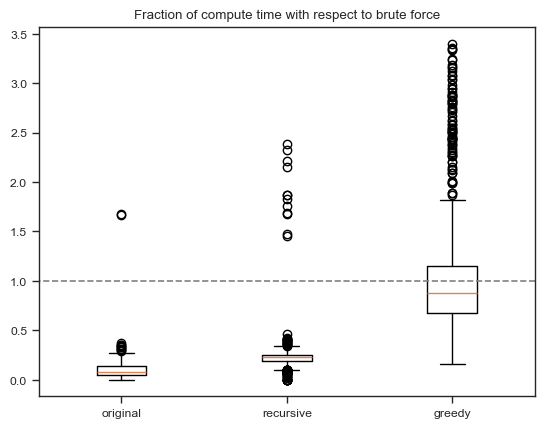

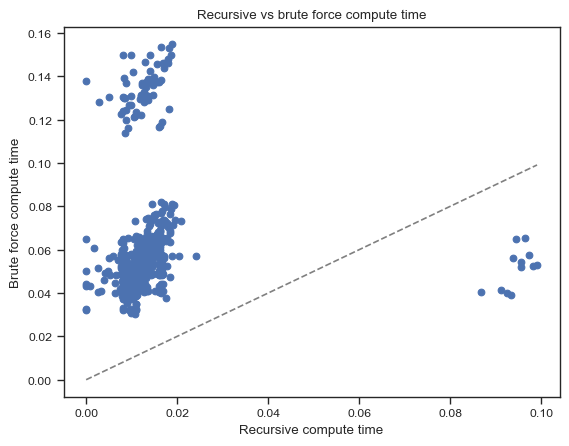

In [11]:
results_small_b2_b2 = {"original" :    {"distance" : [], "compute time" : []},
                      "recursive" :   {"distance" : [], "compute time" : []},
                      "greedy" :      {"distance" : [], "compute time" : []},
                      "brute force" : {"distance" : [], "compute time" : []}}

with tqdm(900) as pbar:
    for i in range(30):
        with open(r"models/b2/"+str(i)+".pkl", "rb") as f:
            m1 = pickle.load(f)
        for ii in range(30):
            with open(r"models/b2/"+str(ii)+".pkl", "rb") as f:
                m2 = pickle.load(f)
                
            t1 = time.time()
            matrix = AlignmentMatrix(m1, m2, verbose = False)
            results_small_b2_b2["original"]["distance"] += [matrix.matrix[-1][-1].value]
            results_small_b2_b2["original"]["compute time"] += [time.time()-t1]
            
            t1 = time.time()
            matrix = AlignmentMatrixRecursive(m1, m2, verbose = False)
            results_small_b2_b2["recursive"]["distance"] += [matrix.matrix[-1][-1].value]
            results_small_b2_b2["recursive"]["compute time"] += [time.time()-t1]
            
            t1 = time.time()
            best_value, best_results = best_swap_alternating(m1, m2, verbose = False)
            results_small_b2_b2["greedy"]["distance"] += [best_value]
            results_small_b2_b2["greedy"]["compute time"] += [time.time()-t1]
            
            t1 = time.time()
            best_value, best_results = brute_force(m1, m2, verbose = False)
            results_small_b2_b2["brute force"]["distance"] += [best_value]
            results_small_b2_b2["brute force"]["compute time"] += [time.time()-t1]
            pbar.update()

plt.boxplot([np.array(results_small_b2_b2["original"]["distance"])-np.array(results_small_b2_b2["brute force"]["distance"]),
             np.array(results_small_b2_b2["recursive"]["distance"])-np.array(results_small_b2_b2["brute force"]["distance"]),
             np.array(results_small_b2_b2["greedy"]["distance"])-np.array(results_small_b2_b2["brute force"]["distance"])]);

ax = plt.gca()
ax.set_xticks([1,2,3])
ax.set_xticklabels(["original","recursive","greedy"])
plt.title("Difference in distance with respect to brute force")
plt.plot((0,4),(0,0), "--", c="grey")
plt.xlim((0.5,3.5))
plt.show();

plt.boxplot([np.array(results_small_b2_b2["original"]["compute time"])/np.array(results_small_b2_b2["brute force"]["compute time"]),
             np.array(results_small_b2_b2["recursive"]["compute time"])/np.array(results_small_b2_b2["brute force"]["compute time"]),
             np.array(results_small_b2_b2["greedy"]["compute time"])/np.array(results_small_b2_b2["brute force"]["compute time"])]);

ax = plt.gca()
ax.set_xticks([1,2,3])
ax.set_xticklabels(["original","recursive","greedy"])
plt.title("Fraction of compute time with respect to brute force")
plt.plot((0,4),(1,1), "--", c="grey")
plt.xlim((0.5,3.5))
plt.show();

plt.scatter(results_small_b2_b2["recursive"]["compute time"], results_small_b2_b2["brute force"]["compute time"])
plt.ylabel("Brute force compute time")
plt.xlabel("Recursive compute time")
plt.plot((0,min(max(results_small_b2_b2["recursive"]["compute time"]),max(results_small_b2_b2["brute force"]["compute time"]))),(0,min(max(results_small_b2_b2["recursive"]["compute time"]),max(results_small_b2_b2["brute force"]["compute time"]))), "--", c="grey")
plt.title("Recursive vs brute force compute time")
plt.show()

Total compute time:
Brute force: 7928.763415336609 seconds
Recursive: 880.5025894641876 seconds


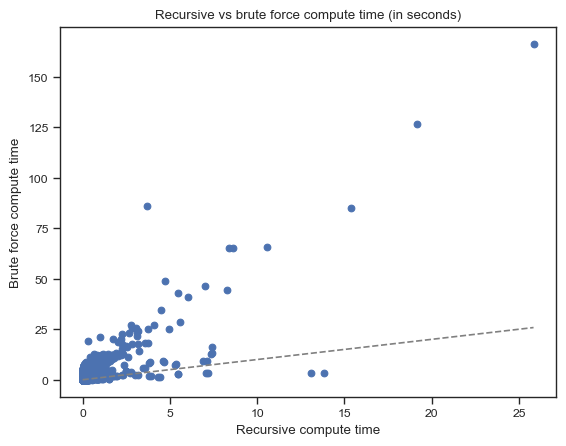

In [12]:
combined_rec_times = results_big_seq_b2["recursive"]["compute time"]+results_big_b2_b2["recursive"]["compute time"]+results_big_seq_seq["recursive"]["compute time"]+results_small_seq_b2["recursive"]["compute time"]+results_small_b2_b2["recursive"]["compute time"]
combined_bf_times = results_big_seq_b2["brute force"]["compute time"]+results_big_b2_b2["brute force"]["compute time"]+results_big_seq_seq["brute force"]["compute time"]+results_small_seq_b2["brute force"]["compute time"]+results_small_b2_b2["brute force"]["compute time"]
print("Total compute time:\nBrute force:",sum(combined_bf_times),"seconds\nRecursive:",sum(combined_rec_times),"seconds")
plt.scatter(combined_rec_times, combined_bf_times)
plt.ylabel("Brute force compute time")
plt.xlabel("Recursive compute time")
plt.plot((0,min(max(combined_rec_times),max(combined_bf_times))),(0,min(max(combined_rec_times),max(combined_bf_times))), "--", c="grey")
plt.title("Recursive vs brute force compute time (in seconds)")
plt.show()

# Generate models to test with

This is what I used to generate the big and small sequential and b2-filled models.

In [4]:
def generate_model_with_b2():
    b2s = 0
    while b2s != 1:
        search.limiter.timer.start()
        try:
            m = search.evolver.sample(search.input_params)
            b2s = 0
            for node in m.serialise():
                if node.operation.name == "branching(2)": b2s += 1
        except Exception as e:
            if "Key" in str(e): break
    return m

def generate_model_with_branching2s(b2s = 3, m1 = None):
    try: m1.id
    except:
        m1 = generate_model_with_b2()
        b2s -= 1
    m2 = generate_model_with_b2()
    b2s -= 1
    model = DerivationTreeNode(0,
                             level=m1.level,
                             parent=None,
                             input_params=m1.input_params,
                             depth=0,
                             limiter=m1.limiter,
                             operation = Operation(name="sequential",
                                                   build=einspace.build_sequential_module,
                                                   infer=einspace.infer_sequential_module,
                                                   valid=einspace.valid_sequential_module,
                                                   inherit = [einspace.inherit_first_child,einspace.inherit_other_child],
                                                   give_back = [einspace.give_back_default,einspace.give_back_default],
                                                   type="nonterminal",
                                                   child_levels=["module","module"])
                              )
    model.children = [m1, m2]
    m1.parent = model
    m2.parent = model
    if b2s: model = generate_model_with_branching2s(b2s = b2s, m1 = model)
    return search.evolver.re_id(model)


def generate_model_with_min_length(length = 20):
    model_length = -1
    while model_length == -1:
        search.limiter.timer.start()
        try:
            m1 = search.evolver.sample(search.input_params)
            model_length = len(m1.serialise())
        except Exception as e:
            if "Key" in str(e): break
    
    while model_length < length:
        search.limiter.timer.start()
        try:
            m2 = search.evolver.sample(search.input_params)
            model = DerivationTreeNode(0,
                             level=m1.level,
                             parent=None,
                             input_params=m1.input_params,
                             depth=0,
                             limiter=m1.limiter,
                             operation = Operation(name="sequential",
                                                   build=einspace.build_sequential_module,
                                                   infer=einspace.infer_sequential_module,
                                                   valid=einspace.valid_sequential_module,
                                                   inherit = [einspace.inherit_first_child,einspace.inherit_other_child],
                                                   give_back = [einspace.give_back_default,einspace.give_back_default],
                                                   type="nonterminal",
                                                   child_levels=["module","module"])
                              )
            model.children = [m1, m2]
            m1.parent = model
            m2.parent = model
            m1 = model
            model_length = len(model.serialise())
        except Exception as e:
            if "Key" in str(e): break

    return search.evolver.re_id(model)

In [18]:
min_length = 20
b2s = 2
n_models = 30

n = len(os.listdir(r"models/seq/"))
while n < n_models:
    try:
        model = generate_model_with_min_length(min_length)
        with open(r"models/seq/"+str(n)+".pkl", "wb") as f: # Save the results we obtained so far
            pickle.dump(model, f)
        n += 1
    except: pass

n = len(os.listdir(r"models/b2/"))
while n < n_models:
    try:
        model = generate_model_with_branching2s(b2s)
        with open(r"models/b2/"+str(n)+".pkl", "wb") as f: # Save the results we obtained so far
            pickle.dump(model, f)
        n += 1
    except: pass


In [51]:
min_length = 40
b2s = 4
n_models = 30

n = len(os.listdir(r"models_big/seq/"))
while n < n_models:
    try:
        model = generate_model_with_min_length(min_length)
        with open(r"models_big/seq/"+str(n)+".pkl", "wb") as f: # Save the results we obtained so far
            pickle.dump(model, f)
        n += 1
    except: pass

n = len(os.listdir(r"models_big/b2/"))
while n < n_models:
    try:
        model = generate_model_with_branching2s(b2s)
        with open(r"models_big/b2/"+str(n)+".pkl", "wb") as f: # Save the results we obtained so far
            pickle.dump(model, f)
        n += 1
    except: pass